# Predicting League of Legends Match Outcomes from In-Game Snapshots

**CS 363M Machine Learning Project — Bibek, Isaac, and Yejune**

## Introduction

We predict whether the blue team will win a ranked League of Legends match using information available while the match is still in progress. This is a supervised binary-classification problem: `hasWon=1` means blue eventually wins, and `hasWon=0` means blue loses. Our primary prediction time is **minute 14**, with secondary comparisons at minutes **10, 18, and 20**.

Our questions are: How informative are current resource advantages? Do objective summaries and the history of a lead add information? Can random forest or gradient boosting improve on an interpretable logistic-regression model? Which game states remain difficult to predict?

The dataset contains **242,572 snapshots from 24,912 matches**, with 59 original columns. Snapshots repeat every two minutes starting at minute 10; matches, rather than rows, are the independent units for splitting and evaluation. The source is [League of Legends SOLO-Q Ranked Games, provided by bobbyscience on Kaggle](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-soloq-ranked-games). It is described by the provider as Platinum-level solo-queue play; our conclusions concern the supplied sample and eligible in-progress matches.

We compare majority-class and gold-lead baselines with logistic regression, a decision tree, random forest, and HistGradientBoosting. We selected configurations using training CV, froze all four final model families, and then conducted one held-out evaluation stage. The preferred minute-14 model from CV was a four-feature logistic regression.

**Contributions:** Bibek prepared validation, exploration, initial features, and clustering; Isaac developed LR/DT models, richer features, and shared evaluation; Yejune developed ensemble comparisons, final evaluation, and error analysis. This notebook integrates the completed work from notebooks 01–05.

### Reproduction

This notebook requires only the original **`lol_ranked_games.csv`** and the Python environment. Put the CSV in `data/raw/` beneath the launch directory (or a parent), or beside the notebook. No other notebooks, `src/` files, processed CSVs, or report files are required.

The feature and evaluation functions are included below. Completed training-CV records and the model specifications frozen before test inspection are embedded in this notebook, so a normal **Restart Kernel and Run All** does not repeat the full hyperparameter searches. The complete search procedures are also included; `RECOMPUTE_TRAINING_SEARCHES=True` repeats the same training-only experiments without changing the frozen final models.

Final predictions are reused when a matching checkpoint is present. In a clean folder they are reproduced by refitting the same frozen configurations, with results checked against the original final evaluation. This deterministic replay does not introduce another round of model selection. Generated tables and plots go to `reports/submission06/`.

The completed experiments used Python 3.13.3, NumPy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, joblib 1.6.0, Matplotlib 3.11.2, and seaborn 0.13.2. Use the same versions for numerical reproduction; the project requirements pin these packages. Select the project environment as the notebook kernel.

In [1]:
import ast
import hashlib
import io
import json
import platform
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from joblib import parallel_config
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay, log_loss, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from threadpoolctl import threadpool_limits

RECOMPUTE_TRAINING_SEARCHES = False
MINUTES = [10, 14, 18, 20]
PRIMARY_MINUTE = 14
THRESHOLD = 0.5
CONFIDENCE_CUTOFF = 0.90
LARGE_GOLD_LEAD = 3000
MODEL_ORDER = ["Logistic regression", "Decision tree", "Random forest", "HistGradientBoosting"]
MODEL_COLORS = dict(zip(MODEL_ORDER, ["#2a9d8f", "#d97757", "#457b9d", "#8f5ca6"]))
METRICS = ["accuracy", "roc_auc", "log_loss", "brier"]

raw_candidates = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
                  for candidate in (parent / "data/raw/lol_ranked_games.csv", parent / "lol_ranked_games.csv")]
raw_path = next((p for p in raw_candidates if p.is_file()), None)
if raw_path is None:
    raise FileNotFoundError("Place lol_ranked_games.csv beside this notebook or in data/raw/.")
root = raw_path.parents[2] if raw_path.parent.name == "raw" and raw_path.parent.parent.name == "data" else raw_path.parent
report_dir = root / "reports/submission06"
figure_dir = report_dir / "figures"
prediction_dir = report_dir / "final_predictions"
for directory in (report_dir, figure_dir, prediction_dir):
    directory.mkdir(parents=True, exist_ok=True)

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def decode_saved(value):
    if not isinstance(value, str):
        return value
    try:
        return json.loads(value)
    except json.JSONDecodeError:
        return ast.literal_eval(value)

def save_csv(frame, path):
    frame.to_csv(path, index=False)

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figure_dir / name, dpi=150, bbox_inches="tight")
    plt.show()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "figure.max_open_warning": 40})
print("Python:", platform.python_version(), "| scikit-learn:", version("scikit-learn"))
print("Raw input:", raw_path)
print("Outputs:", report_dir)

Python: 3.13.3 | scikit-learn: 1.9.1
Raw input: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/data/raw/lol_ranked_games.csv
Outputs: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/reports/submission06


### Embedded completed experiment records

The next collapsed cell contains the original numeric training-CV records, frozen model specifications, and prediction-checkpoint metadata. These are carried forward from completed experiments, not estimated from test outcomes. Keeping them inside the notebook makes the submission portable. The raw CSV remains the only external data input.

In [2]:
ARCHIVE = json.loads('{"csv": {"lr_dt_cv_results.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,params\\nMajority class,none,0.5028646680909153,0.5,0.6931307721124009,0.24999179582105358,6.174464538513284e-05,{}\\nGold-lead rule,sign of goldDiff,0.7622063772408137,0.7621778281916624,0.5486540829412209,0.18129517007016213,0.007789786853061159,{}\\nLogistic regression,Gold only,0.7623076942852662,0.8452854332348354,0.48505538021367733,0.1605583432768344,0.008551635868406278,{\'logisticregression__C\': 1}\\nLogistic regression,Resources,0.7639810065890785,0.8496494097278795,0.47888211572573186,0.15823849241025667,0.0092935293491823,{\'logisticregression__C\': 1}\\nLogistic regression,Resources + changes,0.7641331492607532,0.8496231508581443,0.47891937946244606,0.15825843187630095,0.009871760834695865,{\'logisticregression__C\': 1}\\nLogistic regression,Resources + objectives,0.7710283255822323,0.855362134640264,0.4707319498902073,0.15512614067176272,0.00913587507322682,{\'logisticregression__C\': 10}\\nLogistic regression,Compact,0.7711804939623679,0.8553718013365537,0.4707518223613813,0.15512976883953716,0.008485480618165795,{\'logisticregression__C\': 1}\\nLogistic regression,All features,0.7704707090650603,0.8548533118072765,0.4715201424433409,0.15541113543881885,0.009390115250534025,{\'logisticregression__C\': 0.1}\\nDecision tree,Gold only,0.7610908742676302,0.8434146663787618,0.4867543586322524,0.16102599456422378,0.007600497235623376,\\"{\'max_depth\': 4, \'min_samples_leaf\': 200}\\"\\nDecision tree,Resources,0.7602290752409525,0.8445907773308153,0.48554222445989514,0.16027717827230464,0.008310078740852128,\\"{\'max_depth\': 4, \'min_samples_leaf\': 200}\\"\\nDecision tree,Resources + changes,0.759772801476694,0.8444275152741774,0.48597292304820944,0.16038729200750632,0.00810866356181764,\\"{\'max_depth\': 4, \'min_samples_leaf\': 200}\\"\\nDecision tree,Resources + objectives,0.7650961882065006,0.8489866748182784,0.4829541897216405,0.1582182013122093,0.008849852641812204,\\"{\'max_depth\': 5, \'min_samples_leaf\': 200}\\"\\nDecision tree,Compact,0.7635245785740545,0.8484746544277268,0.4834920310078069,0.15834465417588253,0.007626625234987372,\\"{\'max_depth\': 5, \'min_samples_leaf\': 200}\\"\\nDecision tree,All features,0.7642343377629011,0.8484115176267399,0.48273960062648824,0.15841652975566423,0.008051124784816673,\\"{\'max_depth\': 5, \'min_samples_leaf\': 200}\\"\\n\\"Decision tree (depth 3, for display)\\",Compact,0.7610908742676302,0.8400609261538585,0.4896680012025623,0.1615726679639384,0.007600497235623376,\\"{\'max_depth\': 3, \'min_samples_leaf\': 100}\\"\\n", "frame_comparison.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,minute,train_matches\\nGold-lead rule,All features (no change features),0.7141412908426862,0.714086554681876,0.5985043384851017,0.20418538899306388,0.008529382559014123,10,19912\\nLogistic regression,All features (no change features),0.7225788077480977,0.8024050313348475,0.5380659152401333,0.1813622688036223,0.007336430946868272,10,19912\\nDecision tree,All features (no change features),0.7212226674567314,0.7968578518762863,0.5452417482737034,0.18383415680672618,0.008032121964519875,10,19912\\nGold-lead rule,All features (no change features),0.7622063772408137,0.7621778281916624,0.5486540829412209,0.18129517007016213,0.007789786853061159,14,19723\\nLogistic regression,All features (no change features),0.7703185278306943,0.8548430733496651,0.4714840368746736,0.1554108552892009,0.01009296827729961,14,19723\\nDecision tree,All features (no change features),0.7642343377629011,0.8484879030573058,0.48230093463879325,0.1583901022446605,0.008051124784816673,14,19723\\nGold-lead rule,All features (no change features),0.7869108537570696,0.7869016827111587,0.5180692261374193,0.1676982582012784,0.0053116264091014635,18,18565\\nLogistic regression,All features (no change features),0.7999461352006463,0.8843225675777668,0.4258588945693985,0.1383182058986672,0.004779723253752531,18,18565\\nDecision tree,All features (no change features),0.7911661729060059,0.8760473256134038,0.43961916635506526,0.14276258105777934,0.0037341944546053435,18,18565\\nGold-lead rule,All features (no change features),0.7985677751718032,0.7985703719801643,0.5024973459814167,0.16089471113953868,0.00604341365820852,20,17738\\nLogistic regression,All features (no change features),0.8080952225057045,0.8953772352322673,0.4069579555546007,0.1313870771832359,0.006495422583785688,20,17738\\nDecision tree,All features (no change features),0.8043748007510038,0.8877205524605156,0.4209990023743984,0.1358407890870505,0.006800418307834583,20,17738\\n", "fe_minute14_results.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,params,fold_accuracy,fold_log_loss,minute,n_features\\nGold-lead rule,sign of goldDiff,0.7622063772408137,0.7621778281916624,0.5486540829412209,0.18129517007016213,0.007789786853061159,{},\\"[0.7533586818757921, 0.767807351077313, 0.7690747782002535, 0.7520283975659229, 0.768762677484787]\\",\\"[0.5590492885716877, 0.5420569688561657, 0.5406137560910689, 0.5605383819670495, 0.5410120192201329]\\",14,1\\nLogistic regression,Notebook 01 features,0.7704707090650603,0.8548533118072765,0.4715201424433409,0.15541113543881885,0.009390115250534025,{\'logisticregression__C\': 0.1},\\"[0.7581749049429658, 0.7787072243346007, 0.7807351077313055, 0.7603955375253549, 0.7743407707910751]\\",\\"[0.4875114982846222, 0.4641853248303355, 0.45761672978639023, 0.4842277558080027, 0.464059403507354]\\",14,58\\nDecision tree,Notebook 01 features,0.764183653532214,0.8483078627896304,0.48173708136771387,0.15865093094575716,0.010460564758905999,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.7503168567807351, 0.7743979721166033, 0.773637515842839, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.49984034754279855, 0.4690382336149802, 0.4721087169357026, 0.4943057787263499, 0.47339233001873793]\\",14,58\\nLogistic regression,+ objective,0.7689495522871532,0.8549545963857401,0.4714188291123122,0.15536129225701908,0.009253284570453081,{\'logisticregression__C\': 0.1},\\"[0.7584283903675538, 0.7799746514575412, 0.776425855513308, 0.757606490872211, 0.7723123732251521]\\",\\"[0.4869992816522293, 0.4644848591690726, 0.45749443762281533, 0.4837674008338107, 0.46434816628363285]\\",14,72\\nDecision tree,+ objective,0.7658059602495777,0.8483964435138223,0.4818255056031737,0.15866124450465122,0.00964105270774955,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.755893536121673, 0.7743979721166033, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.4996077188293771, 0.46929651630313374, 0.47261707160290795, 0.4934437999929006, 0.4741624212875492]\\",14,72\\nLogistic regression,+ trajectory,0.7700142939042668,0.8545896169944072,0.4717635900154506,0.15555713833393878,0.00981528483809058,{\'logisticregression__C\': 0.01},\\"[0.758681875792142, 0.7792141951837769, 0.7802281368821293, 0.7578600405679513, 0.7740872210953347]\\",\\"[0.48705897926529235, 0.4641940185621602, 0.4582363200211546, 0.48468251333301865, 0.46464611889562707]\\",14,66\\nDecision tree,+ trajectory,0.764183653532214,0.8477821794525189,0.48251607888353354,0.15884811676518118,0.010460564758905999,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.7503168567807351, 0.7743979721166033, 0.773637515842839, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.5010967584962468, 0.46913545988596683, 0.47243122283795225, 0.49551620925910156, 0.4744007439384004]\\",14,66\\nLogistic regression,All engineered,0.7696592729133085,0.854640108942245,0.4716865822043831,0.15552851759843592,0.009240729935469035,{\'logisticregression__C\': 0.01},\\"[0.7602027883396705, 0.7807351077313055, 0.7782002534854245, 0.7578600405679513, 0.7712981744421906]\\",\\"[0.4867780316598918, 0.46435788167153813, 0.4581530366369834, 0.4843601101020958, 0.4647838509514063]\\",14,80\\nDecision tree,All engineered,0.7658059602495777,0.8480896673434147,0.48241612495734865,0.15875947446834415,0.00964105270774955,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.755893536121673, 0.7743979721166033, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.500129303144114, 0.46939374257412037, 0.47203487769005487, 0.49477531795162355, 0.4757473834268306]\\",14,80\\nLogistic regression,Compact engineered,0.7701157523452544,0.8553344129004186,0.4708210853353503,0.15517298240900862,0.008650033721675965,{\'logisticregression__C\': 10},\\"[0.7599493029150823, 0.7807351077313055, 0.776679340937896, 0.7598884381338742, 0.7733265720081136]\\",\\"[0.4865351723723081, 0.46244776907131, 0.4575174300881355, 0.4833107411083115, 0.4642943140366863]\\",14,30\\nDecision tree,Compact engineered,0.7663129310987539,0.8481142592110791,0.4822419332392049,0.15878643183433705,0.01013359631058875,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.755893536121673, 0.7769328263624842, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.500129303144114, 0.46942911823251937, 0.4716546008448181, 0.4942492605477426, 0.4757473834268306]\\",14,30\\nLogistic regression,All engineered + PCA on resources,0.7691523277725932,0.8545903974890516,0.4719508745787322,0.15554821873256325,0.009612367012902143,\\"{\'columntransformer__resources__pca__n_components\': 2, \'logisticregression__C\': 0.1}\\",\\"[0.7579214195183777, 0.7804816223067174, 0.7776932826362484, 0.7578600405679513, 0.7718052738336714]\\",\\"[0.4873053455412399, 0.4650549768013719, 0.4580354844103878, 0.48437328314115063, 0.46498528299951075]\\",14,80\\nLogistic regression,All engineered + K-means distances,0.7690001722466882,0.8547422509293827,0.47171111035196694,0.15546895283636036,0.009803990475571582,\\"{\'featureunion__clusters__kmeans__n_clusters\': 4, \'logisticregression__C\': 0.1}\\",\\"[0.7581749049429658, 0.779721166032953, 0.7787072243346007, 0.7568458417849898, 0.771551724137931]\\",\\"[0.4872187775397599, 0.46473136990248787, 0.45798153536126546, 0.48422493729741145, 0.46439893165890994]\\",14,80\\nLogistic regression,L1-selected,0.770977718476928,0.8555488928183154,0.47045440224127083,0.15504547525190016,0.008171244022350378,{\'logisticregression__C\': 10},\\"[0.761470215462611, 0.7809885931558935, 0.7769328263624842, 0.7611561866125761, 0.7743407707910751]\\",\\"[0.48658698150123203, 0.46153582240863394, 0.45680019301527647, 0.48344543529000383, 0.46390357899120827]\\",14,4\\nDecision tree,L1-selected,0.7649948583078177,0.8482117804848308,0.48160544112332937,0.15868865319107875,0.010640945591961635,\\"{\'max_depth\': 6, \'min_samples_leaf\': 400}\\",\\"[0.7508238276299113, 0.7769328263624842, 0.773637515842839, 0.7538032454361054, 0.7697768762677485]\\",\\"[0.4994583939750013, 0.46889908635296396, 0.471597310602156, 0.4943089372019585, 0.47376347748456715]\\",14,4\\n", "fe_by_minute.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,params,fold_accuracy,fold_log_loss,minute,n_features\\nGold-lead rule,sign of goldDiff,0.7141412908426862,0.714086554681876,0.5985043384851017,0.20418538899306388,0.008529382559014123,{},\\"[0.7280944012051218, 0.7124560522350578, 0.718804920913884, 0.7049221496735308, 0.7064289301858363]\\",\\"[0.5858977353136353, 0.5999504722994208, 0.5941622374259635, 0.6069604002611761, 0.6055508471253122]\\",10,1\\nLogistic regression,Notebook 01 features,0.7225788077480977,0.8024050313348475,0.5380659152401333,0.1813622688036223,0.007336430946868272,{\'logisticregression__C\': 0.1},\\"[0.735375345217173, 0.7199899547965847, 0.7205623901581723, 0.7129583124058262, 0.7240080361627323]\\",\\"[0.5312600523535101, 0.5387337840074541, 0.5335100711848408, 0.5471005036573423, 0.5397251649975189]\\",10,56\\nDecision tree,Notebook 01 features,0.7188624103469378,0.7967974035186852,0.544881099058095,0.18377677704710854,0.008102954737078779,\\"{\'max_depth\': 6, \'min_samples_leaf\': 400}\\",\\"[0.7336178759728847, 0.7172275238573581, 0.7157921164951042, 0.7089402310396785, 0.7187343043696635]\\",\\"[0.5333385810075619, 0.5480330392360908, 0.539861562595997, 0.5528226655165637, 0.5503496469342614]\\",10,56\\nLogistic regression,+ objective,0.7231816586640887,0.8025337853727301,0.5379138425659498,0.18131060110566283,0.005950821797370607,{\'logisticregression__C\': 0.1},\\"[0.7316093396936982, 0.7222501255650426, 0.7215666582977655, 0.7137117026619789, 0.7267704671019588]\\",\\"[0.5313101355892478, 0.5381329324735963, 0.5335471978571762, 0.5474795700875459, 0.5390993768221825]\\",10,70\\nDecision tree,+ objective,0.7188624103469378,0.7964790747233763,0.545437905526711,0.18392827604802342,0.008102954737078779,\\"{\'max_depth\': 6, \'min_samples_leaf\': 400}\\",\\"[0.7336178759728847, 0.7172275238573581, 0.7157921164951042, 0.7089402310396785, 0.7187343043696635]\\",\\"[0.5342812377136451, 0.5483068957655395, 0.5405690240060695, 0.5538746272894947, 0.5501577428588066]\\",10,70\\nLogistic regression,Compact engineered,0.7233824870718131,0.8024770722354841,0.537895615612627,0.1813264946141691,0.007700832979664774,{\'logisticregression__C\': 0.1},\\"[0.733868943007783, 0.7209944751381215, 0.7208134571930706, 0.7117026619789051, 0.7295328980411854]\\",\\"[0.5314249060603863, 0.5382117989049406, 0.5327861150829709, 0.547717296225374, 0.5393379617894628]\\",10,20\\nDecision tree,Compact engineered,0.7190633144152452,0.796254540245134,0.545503504357981,0.18400481356736512,0.008695182408221983,\\"{\'max_depth\': 6, \'min_samples_leaf\': 400}\\",\\"[0.7336178759728847, 0.720492214967353, 0.7157921164951042, 0.7066800602712205, 0.7187343043696635]\\",\\"[0.5340204421843312, 0.5477987923233493, 0.5411091192604797, 0.5539681928456348, 0.5506209751761105]\\",10,20\\nGold-lead rule,sign of goldDiff,0.7622063772408137,0.7621778281916624,0.5486540829412209,0.18129517007016213,0.007789786853061159,{},\\"[0.7533586818757921, 0.767807351077313, 0.7690747782002535, 0.7520283975659229, 0.768762677484787]\\",\\"[0.5590492885716877, 0.5420569688561657, 0.5406137560910689, 0.5605383819670495, 0.5410120192201329]\\",14,1\\nLogistic regression,Notebook 01 features,0.7704707090650603,0.8548533118072765,0.4715201424433409,0.15541113543881885,0.009390115250534025,{\'logisticregression__C\': 0.1},\\"[0.7581749049429658, 0.7787072243346007, 0.7807351077313055, 0.7603955375253549, 0.7743407707910751]\\",\\"[0.4875114982846222, 0.4641853248303355, 0.45761672978639023, 0.4842277558080027, 0.464059403507354]\\",14,58\\nDecision tree,Notebook 01 features,0.764183653532214,0.8483078627896304,0.48173708136771387,0.15865093094575716,0.010460564758905999,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.7503168567807351, 0.7743979721166033, 0.773637515842839, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.49984034754279855, 0.4690382336149802, 0.4721087169357026, 0.4943057787263499, 0.47339233001873793]\\",14,58\\nLogistic regression,+ objective,0.7689495522871532,0.8549545963857401,0.4714188291123122,0.15536129225701908,0.009253284570453081,{\'logisticregression__C\': 0.1},\\"[0.7584283903675538, 0.7799746514575412, 0.776425855513308, 0.757606490872211, 0.7723123732251521]\\",\\"[0.4869992816522293, 0.4644848591690726, 0.45749443762281533, 0.4837674008338107, 0.46434816628363285]\\",14,72\\nDecision tree,+ objective,0.7658059602495777,0.8483964435138223,0.4818255056031737,0.15866124450465122,0.00964105270774955,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.755893536121673, 0.7743979721166033, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.4996077188293771, 0.46929651630313374, 0.47261707160290795, 0.4934437999929006, 0.4741624212875492]\\",14,72\\nLogistic regression,+ trajectory,0.7700142939042668,0.8545896169944072,0.4717635900154506,0.15555713833393878,0.00981528483809058,{\'logisticregression__C\': 0.01},\\"[0.758681875792142, 0.7792141951837769, 0.7802281368821293, 0.7578600405679513, 0.7740872210953347]\\",\\"[0.48705897926529235, 0.4641940185621602, 0.4582363200211546, 0.48468251333301865, 0.46464611889562707]\\",14,66\\nDecision tree,+ trajectory,0.764183653532214,0.8477821794525189,0.48251607888353354,0.15884811676518118,0.010460564758905999,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.7503168567807351, 0.7743979721166033, 0.773637515842839, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.5010967584962468, 0.46913545988596683, 0.47243122283795225, 0.49551620925910156, 0.4744007439384004]\\",14,66\\nLogistic regression,All engineered,0.7696592729133085,0.854640108942245,0.4716865822043831,0.15552851759843592,0.009240729935469035,{\'logisticregression__C\': 0.01},\\"[0.7602027883396705, 0.7807351077313055, 0.7782002534854245, 0.7578600405679513, 0.7712981744421906]\\",\\"[0.4867780316598918, 0.46435788167153813, 0.4581530366369834, 0.4843601101020958, 0.4647838509514063]\\",14,80\\nDecision tree,All engineered,0.7658059602495777,0.8480896673434147,0.48241612495734865,0.15875947446834415,0.00964105270774955,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.755893536121673, 0.7743979721166033, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.500129303144114, 0.46939374257412037, 0.47203487769005487, 0.49477531795162355, 0.4757473834268306]\\",14,80\\nLogistic regression,Compact engineered,0.7701157523452544,0.8553344129004186,0.4708210853353503,0.15517298240900862,0.008650033721675965,{\'logisticregression__C\': 10},\\"[0.7599493029150823, 0.7807351077313055, 0.776679340937896, 0.7598884381338742, 0.7733265720081136]\\",\\"[0.4865351723723081, 0.46244776907131, 0.4575174300881355, 0.4833107411083115, 0.4642943140366863]\\",14,30\\nDecision tree,Compact engineered,0.7663129310987539,0.8481142592110791,0.4822419332392049,0.15878643183433705,0.01013359631058875,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.755893536121673, 0.7769328263624842, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.500129303144114, 0.46942911823251937, 0.4716546008448181, 0.4942492605477426, 0.4757473834268306]\\",14,30\\nGold-lead rule,sign of goldDiff,0.7869108537570696,0.7869016827111587,0.5180692261374193,0.1676982582012784,0.0053116264091014635,{},\\"[0.7780770266630757, 0.7842714785887422, 0.7934284944788581, 0.7885806625370321, 0.7901966065176407]\\",\\"[0.5297872029646997, 0.5214320621636817, 0.5095852178131183, 0.5158370974877555, 0.5137045502578418]\\",18,1\\nLogistic regression,Notebook 01 features,0.7995152168058175,0.8846334843176977,0.42537828270368144,0.13813598253510478,0.004914996916572227,{\'logisticregression__C\': 0.1},\\"[0.7969297064368436, 0.7950444384594667, 0.798007002423916, 0.7985456504174522, 0.8090492862914086]\\",\\"[0.43020274060251823, 0.4324308545574549, 0.42345512721173917, 0.4221919187290475, 0.4186107724176475]\\",18,58\\nDecision tree,Notebook 01 features,0.7908429841098842,0.873598551295594,0.44149439715657984,0.14357869042756632,0.005425658754384902,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7815782386210611, 0.7920818744950175, 0.7982763264206841, 0.7926205224885537, 0.7896579585241045]\\",\\"[0.45419111150531144, 0.44765442295699004, 0.4317443566055316, 0.4372127816541537, 0.43666931306091233]\\",18,58\\nLogistic regression,+ objective,0.7988688392135739,0.8847186700117996,0.4252550185408096,0.13809331926122725,0.004923254447515154,{\'logisticregression__C\': 0.1},\\"[0.7955830864530029, 0.7936978184756261, 0.7990842984109884, 0.798007002423916, 0.8079719903043361]\\",\\"[0.43021842552589906, 0.4323584683652186, 0.42297489315537873, 0.42156299626716787, 0.4191603093903839]\\",18,72\\nDecision tree,+ objective,0.7899811473202263,0.8732464054764459,0.4419746486033363,0.14383404462315674,0.005417095862870856,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7815782386210611, 0.7920818744950175, 0.7982763264206841, 0.7883113385402639, 0.7896579585241045]\\",\\"[0.45419111150531144, 0.44701321687442974, 0.4317443566055316, 0.43843235597738855, 0.43849220205402006]\\",18,72\\nLogistic regression,+ trajectory,0.8000538647993537,0.884608648232956,0.4253528217975382,0.13812304615497262,0.004284199046624978,{\'logisticregression__C\': 0.01},\\"[0.7961217344465392, 0.7971990304336116, 0.7996229464045247, 0.7990842984109884, 0.8082413143011042]\\",\\"[0.42893655599305214, 0.43273351208413235, 0.42313917994633204, 0.42331036284680174, 0.4186444981173726]\\",18,66\\nDecision tree,+ trajectory,0.7908429841098842,0.8731537047924995,0.44254541296729866,0.14397462603171432,0.005425658754384902,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7815782386210611, 0.7920818744950175, 0.7982763264206841, 0.7926205224885537, 0.7896579585241045]\\",\\"[0.4538935040548549, 0.4508997435989165, 0.43345972717701337, 0.437804776944796, 0.43666931306091233]\\",18,66\\nLogistic regression,All engineered,0.7998384056019392,0.8846602354852304,0.42531474830181076,0.13811163829244572,0.004313894543533724,{\'logisticregression__C\': 0.01},\\"[0.7974683544303798, 0.7961217344465392, 0.7982763264206841, 0.7990842984109884, 0.8082413143011042]\\",\\"[0.4290024236092564, 0.4328427310534163, 0.4229519769614933, 0.4229235935296565, 0.4188530163552312]\\",18,80\\nDecision tree,All engineered,0.7899811473202263,0.8728015589733514,0.44302566441405505,0.14422998022730477,0.005417095862870856,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7815782386210611, 0.7920818744950175, 0.7982763264206841, 0.7883113385402639, 0.7896579585241045]\\",\\"[0.4538935040548549, 0.45025853751635614, 0.43345972717701337, 0.4390243512680309, 0.43849220205402006]\\",18,80\\nLogistic regression,Compact engineered,0.8007541071909507,0.8850085801634201,0.4248184604512607,0.1379041121504081,0.002417323530548544,{\'logisticregression__C\': 0.1},\\"[0.7996229464045247, 0.7977376784271478, 0.8020468623754377, 0.7996229464045247, 0.8047401023431188]\\",\\"[0.42753296036034594, 0.4336784671171684, 0.42140289645625467, 0.42139095804622234, 0.4200870202763122]\\",18,30\\nDecision tree,Compact engineered,0.7897118233234581,0.8759492860629399,0.4394543414500286,0.1432510710183243,0.0031008538571773436,\\"{\'max_depth\': 8, \'min_samples_leaf\': 400}\\",\\"[0.786156746566119, 0.7920818744950175, 0.7945057904659305, 0.7883113385402639, 0.7875033665499596]\\",\\"[0.4501585969818959, 0.4446068517113781, 0.4324572309135373, 0.4343902952235761, 0.4356587324197558]\\",18,30\\nGold-lead rule,sign of goldDiff,0.7985677751718032,0.7985703719801643,0.5024973459814167,0.16089471113953868,0.00604341365820852,{},\\"[0.794250281848929, 0.8055242390078917, 0.8007328072153326, 0.8032139836481533, 0.7891175641387088]\\",\\"[0.5083957284247524, 0.49308836473686174, 0.4994161879141955, 0.4960410805689661, 0.5155453682623077]\\",20,1\\nLogistic regression,Notebook 01 features,0.8100683557154387,0.8955206788287112,0.4067019357363497,0.13132355787538813,0.0062059097771612025,{\'logisticregression__C\': 0.1},\\"[0.8114430665163472, 0.8125704622322435, 0.8136978579481398, 0.814773047645898, 0.7978573442345644]\\",\\"[0.4052690844776301, 0.3982603096195846, 0.40222855249650935, 0.40687597395565084, 0.4208757581323738]\\",20,58\\nDecision tree,Notebook 01 features,0.7994133060664824,0.8874511596962579,0.4239464978618062,0.136153059363638,0.008184245198838322,\\"{\'max_depth\': 6, \'min_samples_leaf\': 400}\\",\\"[0.7931228861330327, 0.810879368658399, 0.8010146561443067, 0.8043416972089089, 0.7877079221877643]\\",\\"[0.4212419760442151, 0.4153227145462633, 0.4267719643373247, 0.4204832839170387, 0.43591255046418925]\\",20,58\\nLogistic regression,+ objective,0.809673671861417,0.8955787754396886,0.4065779434591099,0.13128612562677525,0.0066810878913044925,{\'logisticregression__C\': 0.1},\\"[0.8122886133032694, 0.8117249154453213, 0.8134160090191658, 0.814491119255709, 0.7964477022836199]\\",\\"[0.4050699378577935, 0.3981225367084677, 0.40210149998579514, 0.40692407197392416, 0.42067167076956913]\\",20,72\\nDecision tree,+ objective,0.7993569998496595,0.8852241569374304,0.4243489989194994,0.13680006553337484,0.00831894781654842,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7922773393461104, 0.810315670800451, 0.8010146561443067, 0.8054694107696645, 0.7877079221877643]\\",\\"[0.42556644664481774, 0.406569079626419, 0.4251434596040348, 0.4258941817632379, 0.43857182695898767]\\",20,72\\nLogistic regression,+ trajectory,0.8086027253925305,0.8956295654798737,0.40645260883707524,0.13124875978785955,0.004974067512269929,{\'logisticregression__C\': 0.01},\\"[0.8069334836527621, 0.8117249154453213, 0.8120067643742954, 0.8127995489145757, 0.7995489145756978]\\",\\"[0.40494446575404086, 0.3983468841940249, 0.4020978025161158, 0.40688158277773595, 0.4199923089434587]\\",20,66\\nDecision tree,+ trajectory,0.7996388487786336,0.885402055316054,0.4240014030073434,0.13666580055551394,0.008331174763761405,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7931228861330327, 0.810879368658399, 0.8010146561443067, 0.8054694107696645, 0.7877079221877643]\\",\\"[0.4251825348640231, 0.4064332801868389, 0.42505195978080235, 0.4258941817632379, 0.43744505844181464]\\",20,66\\nLogistic regression,All engineered,0.808151767106172,0.8956598826058422,0.4064199252505437,0.13124655801171325,0.00519601029186815,{\'logisticregression__C\': 0.01},\\"[0.8060879368658399, 0.810315670800451, 0.8120067643742954, 0.8133634056949535, 0.79898505779532]\\",\\"[0.4048534958498677, 0.3982941683135148, 0.40199979081804754, 0.40699909023574316, 0.4199530810355453]\\",20,80\\nDecision tree,All engineered,0.7993569998496595,0.8852241569374304,0.4243489989194994,0.13680006553337484,0.00831894781654842,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7922773393461104, 0.810315670800451, 0.8010146561443067, 0.8054694107696645, 0.7877079221877643]\\",\\"[0.42556644664481774, 0.406569079626419, 0.4251434596040348, 0.4258941817632379, 0.43857182695898767]\\",20,80\\nLogistic regression,Compact engineered,0.8069115046807424,0.8960579536657469,0.40570556277483183,0.1310634363747884,0.0061546843185037465,{\'logisticregression__C\': 0.1},\\"[0.8046786922209695, 0.8089064261555806, 0.810879368658399, 0.8139272624753313, 0.796165773893431]\\",\\"[0.4043825235963105, 0.39768939931555086, 0.401372163234969, 0.4048318522085177, 0.4202518755188113]\\",20,30\\nDecision tree,Compact engineered,0.7993569998496595,0.8852914893657957,0.42422174951208724,0.13675163650668268,0.00831894781654842,\\"{\'max_depth\': 4, \'min_samples_leaf\': 400}\\",\\"[0.7922773393461104, 0.810315670800451, 0.8010146561443067, 0.8054694107696645, 0.7877079221877643]\\",\\"[0.4249301996077569, 0.406569079626419, 0.4251434596040348, 0.4258941817632379, 0.43857182695898767]\\",20,30\\n", "fe_paired_gain.csv": "model,features,minute,log loss reduction,log loss SE,accuracy gain (pp),accuracy SE (pp)\\nLogistic regression,+ objective,10,0.0001520726741835343,0.00019806324668795165,0.06028509159911266,0.11550151392761211\\nDecision tree,+ objective,10,-0.0005568064686161112,0.00022993305975952614,0.0,0.0\\nLogistic regression,+ objective,14,0.00010131333102876283,0.00017478998253065832,-0.15211567779071844,0.10139987488836216\\nDecision tree,+ objective,14,-8.842423545988299e-05,0.00028949993135683625,0.16223067173637418,0.11037536657580284\\nLogistic regression,+ trajectory,14,-0.0002434475721096563,0.00020535905804326226,-0.045641516079357736,0.055778654519202935\\nDecision tree,+ trajectory,14,-0.0007789975158197348,0.00023873484752131617,0.0,0.0\\nLogistic regression,All engineered,14,-0.00016643976104216974,0.00025091880948947994,-0.08114361517519209,0.11628435494622778\\nDecision tree,All engineered,14,-0.0006790435896348312,0.0004287526588650492,0.16223067173637418,0.11037536657580284\\nLogistic regression,+ objective,18,0.00012326416287182783,0.0002070838724713849,-0.06463775922435078,0.04554682069832444\\nDecision tree,+ objective,18,-0.00048025144675645226,0.00045101129646833666,-0.0861836789657966,0.0861836789657966\\nLogistic regression,+ trajectory,18,2.5460906143282e-05,0.0003900936488123331,0.05386479935362232,0.06082192184560418\\nDecision tree,+ trajectory,18,-0.0010510158107187918,0.0006477059407333329,0.0,0.0\\nLogistic regression,All engineered,18,6.353440187071291e-05,0.0003490995806784999,0.03231887961217428,0.031176506605953627\\nDecision tree,All engineered,18,-0.001531267257475244,0.0004844218568775056,-0.0861836789657966,0.0861836789657966\\nLogistic regression,+ objective,20,0.000123992277239815,4.575900930503897e-05,-0.039468385402148254,0.03739675708162064\\nDecision tree,+ objective,20,-0.0004025010576932164,0.0025837833638127517,-0.005630621682295445,0.03382743390191834\\nLogistic regression,+ trajectory,20,0.0002493268992744935,0.00017315635200419017,-0.1465630322908118,0.09981690911941367\\nDecision tree,+ trajectory,20,-5.490514553715409e-05,0.0025408638889735484,0.022554271215111665,0.022554271215111665\\nLogistic regression,All engineered,20,0.00028201048580605014,0.00018641798426193243,-0.1916588609266623,0.1037149079670979\\nDecision tree,All engineered,20,-0.0004025010576932164,0.0025837833638127517,-0.005630621682295445,0.03382743390191834\\n", "feature_definitions.csv": "feature,group,definition\\ndragonDiff,objective,Dragons taken by blue minus dragons taken by red\\nblueDragons,objective,Dragons taken by blue (progress toward dragon soul)\\nredDragons,objective,Dragons taken by red (progress toward dragon soul)\\nheraldDiff,objective,Rift Heralds taken by blue minus red\\nbaronDiff,objective,Barons taken by blue minus red\\nelderDiff,objective,Elder dragons taken by blue minus red\\nouterTurretDiff,objective,Outer turrets destroyed by blue minus lost by blue\\ninnerTurretDiff,objective,Inner turrets destroyed by blue minus lost by blue\\nbaseTurretDiff,objective,Base turrets destroyed by blue minus lost by blue\\nnexusTurretDiff,objective,Nexus turrets destroyed by blue minus lost by blue\\ntotalTurretDiff,objective,All turrets destroyed by blue minus lost by blue\\ninhibitorDiff,objective,Inhibitors destroyed by blue minus lost by blue\\nkillDeathDiff,objective,Blue kills minus blue deaths\\nkillShare,objective,Smoothed share of all kills that blue has: (kills + 1) / (kills + deaths + 2)\\nassistsPerKill,objective,Blue assists per blue kill (team-fight participation)\\nwardDiff,objective,Enemy wards blue destroyed minus blue wards destroyed by red\\nlogWardsPlaced,objective,log(1 + wards placed by blue); tames extreme ward counts\\ngoldChange2,trajectory,Gold difference now minus 2 minutes ago\\ngoldChange4,trajectory,Gold difference now minus 4 minutes ago\\nexpChange4,trajectory,Experience difference now minus 4 minutes ago\\nkillDeathChange4,trajectory,Kill-death difference now minus 4 minutes ago\\ngoldSlope,trajectory,Least-squares slope of gold difference per minute since minute 10\\nexpSlope,trajectory,Least-squares slope of experience difference per minute since minute 10\\nmaxGoldLead,trajectory,Largest blue gold lead seen so far\\nminGoldLead,trajectory,Smallest blue gold lead (largest deficit) seen so far\\ngoldVolatility,trajectory,Standard deviation of 2-minute gold-difference changes\\nleadChanges,trajectory,Number of times the gold lead switched teams\\n", "cluster_selection.csv": "clusters,inertia,silhouette,smallest_cluster\\n2,64981.46512308912,0.3573846348440238,9775\\n3,50109.83888497067,0.273025979920903,5030\\n4,43132.32257741629,0.24076426649900692,4142\\n5,37996.352416567956,0.23119570711859797,2270\\n6,34029.08605011121,0.22166359151864254,2248\\n", "cluster_profiles.csv": "cluster,matches,goldDiff,expDiff,killDeathDiff,dragonDiff,outerTurretDiff,goldChange10to14,win_rate_percent\\n0,9775,3327.5001534526855,2304.8260869565215,4.555498721227622,0.5624552429667519,0.570230179028133,1857.9448593350385,77.22762148337597\\n1,9948,-3107.708685162847,-2363.768496180137,-4.223160434258142,-0.6198230800160837,-0.49668275030156817,-1731.565138721351,23.81383192601528\\n", "ensemble_by_minute.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,params,fold_accuracy,fold_log_loss,minute,n_features,train_matches,feature_columns,source,elapsed_seconds,fingerprint\\nGold-lead rule,sign of goldDiff,0.7141412908426862,0.714086554681876,0.5985043384851017,0.20418538899306388,0.008529382559014123,{},\\"[0.7280944012051218, 0.7124560522350578, 0.718804920913884, 0.7049221496735308, 0.7064289301858363]\\",\\"[0.5858977353136353, 0.5999504722994208, 0.5941622374259635, 0.6069604002611761, 0.6055508471253122]\\",10,1,19912,\\"[\\"\\"goldDiff\\"\\"]\\",Yejune (04),1.8735656249918975,f233aead8e5e7e5f625dd189a4a8c7f16355d07ffdfa735d95be51747f0b7d9d\\nRandom forest,Notebook 01 features,0.7200174952488306,0.8005713180222189,0.541034069988433,0.1822443963503731,0.005769498608182284,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.72985187044941, 0.7194876946258162, 0.7218177253326639, 0.7129583124058262, 0.715971873430437]\\",\\"[0.5334068376997547, 0.5432849428019485, 0.533977114028021, 0.5489025163742174, 0.5455989390382231]\\",10,56,19912,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\"]\\",Yejune (04),80.77192766702501,524aba9cb35bb0975aa4628eb81a0c2c30ddc40fd2be96ae31078e61f049c369\\nHistGradientBoosting,Notebook 01 features,0.7217252428799293,0.7991233853346086,0.5429459264598455,0.18292105321228808,0.004798906647122281,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7280944012051218, 0.7230035158211954, 0.7223198594024605, 0.7132094424912104, 0.7219989954796585]\\",\\"[0.5349868221034936, 0.5438382300803841, 0.5356134943626089, 0.5520625654169478, 0.5482285203357934]\\",10,56,19912,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\"]\\",Yejune (04),29.14396720798686,404d98968c1193da243397668a431ff57b4e181d94effd02ebac7b467c21b46c\\nRandom forest,All engineered,0.7208212250129349,0.8001156649254663,0.5411609658082039,0.18240298542521674,0.005901750940451763,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 5, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.729098669344715, 0.724761426418885, 0.720311323123274, 0.7117026619789051, 0.7182320441988951]\\",\\"[0.5338272014519762, 0.5417523719072748, 0.5344002648518571, 0.549574343180479, 0.5462506476494324]\\",10,70,19912,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\"]\\",Yejune (04),92.04952333401889,9f4a411dc0179b23eda57645696d56540f10373888c1c78c68dcfa4dd6668686\\nHistGradientBoosting,All engineered,0.7192141942280307,0.7986697001041652,0.5431517547318471,0.18309003843319407,0.0053697767827714646,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.724328395681647, 0.7245102963335007, 0.7210645242279689, 0.7106981416373681, 0.7154696132596685]\\",\\"[0.5376452208319777, 0.5426119511620175, 0.5356030354012837, 0.5509605995427415, 0.5489379667212152]\\",10,70,19912,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\"]\\",Yejune (04),33.608701208024286,10ffd56150c4e948d7ed592e56b1ee4637bfa68fe79777f641acf0679d1c6c76\\nGold-lead rule,sign of goldDiff,0.7622063772408137,0.7621778281916624,0.5486540829412209,0.18129517007016213,0.007789786853061159,{},\\"[0.7533586818757921, 0.767807351077313, 0.7690747782002535, 0.7520283975659229, 0.768762677484787]\\",\\"[0.5590492885716877, 0.5420569688561657, 0.5406137560910689, 0.5605383819670495, 0.5410120192201329]\\",14,1,19723,\\"[\\"\\"goldDiff\\"\\"]\\",Yejune (04),3.571223374980036,19c81e3dc2ee47e71d59156f376978a90e4fb99f27b1353d0ebed3d040874036\\nRandom forest,Notebook 01 features,0.7697102656455266,0.8535662696838842,0.47352643333862304,0.15614423838658684,0.01021385665724967,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.7543726235741445, 0.7802281368821293, 0.7789607097591889, 0.7611561866125761, 0.7738336713995944]\\",\\"[0.4884337403344118, 0.4656865263026925, 0.4612139303849137, 0.4864359188730328, 0.46586205079806453]\\",14,58,19723,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),110.67660745797912,9184ad831486ffcb533625cb4c7e6d37646125bda678ca581de3edcc189510be\\nHistGradientBoosting,Notebook 01 features,0.7697608598966006,0.8528630155456947,0.474656569246206,0.15655911874985168,0.009095400521173379,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7576679340937896, 0.7804816223067174, 0.7776932826362484, 0.7606490872210954, 0.7723123732251521]\\",\\"[0.49079249431937505, 0.4669414190638383, 0.4622145118758503, 0.48541847312794134, 0.46791594784402457]\\",14,58,19723,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),29.782052458031103,7798fe8bd42a868ae7bcce4b00fa9d3f224d0b29b13552dccdd889f18a403c7a\\nRandom forest,All engineered,0.768239857369459,0.8537183445598886,0.4733069163929107,0.15609637520618208,0.00889538640818178,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.7566539923954373, 0.7771863117870722, 0.7761723700887199, 0.7583671399594321, 0.7728194726166329]\\",\\"[0.4864545277830064, 0.46517014789530703, 0.4617281055617657, 0.48612841064449286, 0.46705339007998153]\\",14,80,19723,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),177.88241329201264,a31f908e0264acf364608ee18e5bd933c77eae017dc8cda922099ba98e1d9213\\nHistGradientBoosting,All engineered,0.7680368376536402,0.8524643502460789,0.4753334271845838,0.15672102128493673,0.009699154819039863,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7574144486692015, 0.7807351077313055, 0.7754119138149557, 0.7563387423935092, 0.7702839756592292]\\",\\"[0.4923764646511814, 0.4678049071543401, 0.46137292714798506, 0.48722652808766653, 0.4678863088817461]\\",14,80,19723,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),36.39229374995921,ed24f0913d895e626627a00784ad1933729e69bb414d9e10abb4306e5cea56f8\\nGold-lead rule,sign of goldDiff,0.7869108537570696,0.7869016827111587,0.5180692261374193,0.1676982582012784,0.0053116264091014635,{},\\"[0.7780770266630757, 0.7842714785887422, 0.7934284944788581, 0.7885806625370321, 0.7901966065176407]\\",\\"[0.5297872029646997, 0.5214320621636817, 0.5095852178131183, 0.5158370974877555, 0.5137045502578418]\\",18,1,18565,\\"[\\"\\"goldDiff\\"\\"]\\",Yejune (04),1.7615805839886889,a4f1eb3dc88075acfe2c82b5cff85c2f17baa5a9e4febc07aa464e80bb420009\\nRandom forest,Notebook 01 features,0.7959601400484784,0.8832154409548686,0.4275250019173534,0.13893876317187576,0.004486003299468248,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.7961217344465392, 0.7923511984917856, 0.8012388903851333, 0.7896579585241045, 0.8004309183948289]\\",\\"[0.432507436921015, 0.4359615365185857, 0.41971293297759715, 0.4261881494716002, 0.4232549536979687]\\",18,58,18565,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),102.5913993329741,e4b8051244ec6b55480a348dc83af08ac00bf9bbcde0a6c9f2a05d5cd1fae717\\nHistGradientBoosting,Notebook 01 features,0.7954214920549421,0.8824409926622776,0.4293911415734989,0.13946486824049226,0.0028735747198166644,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.7904659305144088, 0.7950444384594667, 0.7971990304336116, 0.7953137624562349, 0.7990842984109884]\\",\\"[0.4352729806185685, 0.439016637318849, 0.4221979820381594, 0.4261085924886109, 0.42435951540330663]\\",18,58,18565,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),31.593423667014576,3ccdfa7c386a950b0b198402222ed6c95189dc6d11e87958c956f72764b486c7\\nRandom forest,All engineered,0.798868839213574,0.8834431447817954,0.42767407301177274,0.13883499565179122,0.0035542605303148277,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.7963910584433073, 0.7977376784271478, 0.8025855103689739, 0.7942364664691623, 0.8033934823592782]\\",\\"[0.43286044876429836, 0.43628575593305247, 0.4204607559994445, 0.42554791079019016, 0.42321549357187854]\\",18,80,18565,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),173.55462516698753,30087eebf4fcd3e29fe3e55b7b95cc4dfadeae9273c14c67c91efbe542af5ab5\\nHistGradientBoosting,All engineered,0.7980070024239161,0.8822452629172324,0.4296273543379586,0.13962427068660604,0.002354082777636658,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.7958524104497711, 0.7963910584433073, 0.8001615943980609, 0.7961217344465392, 0.8015082143819015]\\",\\"[0.4332623397628686, 0.44015222852729785, 0.42380485381795924, 0.42762981336522254, 0.42328753621644477]\\",18,80,18565,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),34.46236520801904,3b185edc38e23201433da112c8419f120def4a05ef83596d3315e54574f9e8c0\\nGold-lead rule,sign of goldDiff,0.7985677751718032,0.7985703719801643,0.5024973459814167,0.16089471113953868,0.00604341365820852,{},\\"[0.794250281848929, 0.8055242390078917, 0.8007328072153326, 0.8032139836481533, 0.7891175641387088]\\",\\"[0.5083957284247524, 0.49308836473686174, 0.4994161879141955, 0.4960410805689661, 0.5155453682623077]\\",20,1,17738,\\"[\\"\\"goldDiff\\"\\"]\\",Yejune (04),1.7097107920562848,4511a8f0dc5adac9c20f2266ebf339d5ba68dce36cee0f3b5f13924a92b9f848\\nRandom forest,Notebook 01 features,0.8064041289318601,0.8939655094759532,0.40996909945997057,0.13225998338635522,0.004207370220858613,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.8055242390078917, 0.8094701240135288, 0.8077790304396844, 0.8105441217930646, 0.7987031294051311]\\",\\"[0.409512209226973, 0.3987578791332838, 0.40847039597837104, 0.4105956930863936, 0.42250931987483137]\\",20,58,17738,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),111.97999150003307,9e7a0ff772eb41090a7ae6e84b7f089f4f4a53dd52b646c57e0730f0c664217c\\nHistGradientBoosting,Notebook 01 features,0.8074188645373817,0.8931340005685108,0.41170766613705123,0.13270372435296346,0.005655895541885723,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.8055242390078917, 0.810315670800451, 0.8105975197294251, 0.8133634056949535, 0.7972934874541866]\\",\\"[0.4094029542048535, 0.39992771537012, 0.4089849096639691, 0.4123980395116055, 0.42782471193470784]\\",20,58,17738,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),29.094288333959412,44789ff2ba562c511df0749edb0d23af8cb954bcb961fdde77aa67bc6661ba8a\\nRandom forest,All engineered,0.8067988286781246,0.8941315864886571,0.4097317358919826,0.13219020571676438,0.0050310890157739645,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.8041149943630215, 0.8097519729425028, 0.8089064261555806, 0.8127995489145757, 0.7984212010149422]\\",\\"[0.40925472050067707, 0.4002136038395291, 0.40776212761686664, 0.40993599708240563, 0.4214922304204345]\\",20,80,17738,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),169.3989976249868,ca3499ac58059cbd90a9e752e7bda0ccb78958594da44945a99882ddae8da865\\nHistGradientBoosting,All engineered,0.8067426019225165,0.893118721503494,0.4117223097222487,0.13281359798655484,0.0027351066433490014,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.802423900789177, 0.8091882750845547, 0.8083427282976324, 0.8091344798421201, 0.8046236255990978]\\",\\"[0.4117673480039178, 0.40050890897314884, 0.4088574375287011, 0.411823332836296, 0.4256545212691802]\\",20,80,17738,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),33.189353749970905,ee2e46753c719834edf0de88aca312793f73fb634f1b6c11938d72fdd6f3c91a\\n", "ensemble_all_models_by_minute.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,params,fold_accuracy,fold_log_loss,minute,n_features,isaac_feature_label,train_matches,source,feature_columns,elapsed_seconds,fingerprint\\nLogistic regression,Notebook 01 features,0.7225788077480977,0.8024050313348475,0.5380659152401333,0.1813622688036223,0.0073364309468682,\\"{\\"\\"logisticregression__C\\"\\": 0.1}\\",\\"[0.735375345217173, 0.7199899547965847, 0.7205623901581723, 0.7129583124058262, 0.7240080361627323]\\",\\"[0.5312600523535101, 0.5387337840074541, 0.5335100711848408, 0.5471005036573423, 0.5397251649975189]\\",10,56,Notebook 01 features,19912,Isaac (03),,,\\nDecision tree,Notebook 01 features,0.7188624103469378,0.7967974035186852,0.544881099058095,0.1837767770471085,0.0081029547370787,\\"{\\"\\"max_depth\\"\\": 6, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7336178759728847, 0.7172275238573581, 0.7157921164951042, 0.7089402310396785, 0.7187343043696635]\\",\\"[0.5333385810075619, 0.5480330392360908, 0.539861562595997, 0.5528226655165637, 0.5503496469342614]\\",10,56,Notebook 01 features,19912,Isaac (03),,,\\nLogistic regression,All engineered,0.7231816586640887,0.8025337853727301,0.5379138425659498,0.1813106011056628,0.0059508217973706,\\"{\\"\\"logisticregression__C\\"\\": 0.1}\\",\\"[0.7316093396936982, 0.7222501255650426, 0.7215666582977655, 0.7137117026619789, 0.7267704671019588]\\",\\"[0.5313101355892478, 0.5381329324735963, 0.5335471978571762, 0.5474795700875459, 0.5390993768221825]\\",10,70,+ objective,19912,Isaac (03),,,\\nDecision tree,All engineered,0.7188624103469378,0.7964790747233763,0.545437905526711,0.1839282760480234,0.0081029547370787,\\"{\\"\\"max_depth\\"\\": 6, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7336178759728847, 0.7172275238573581, 0.7157921164951042, 0.7089402310396785, 0.7187343043696635]\\",\\"[0.5342812377136451, 0.5483068957655395, 0.5405690240060695, 0.5538746272894947, 0.5501577428588066]\\",10,70,+ objective,19912,Isaac (03),,,\\nLogistic regression,Notebook 01 features,0.7704707090650603,0.8548533118072765,0.4715201424433409,0.1554111354388188,0.009390115250534,\\"{\\"\\"logisticregression__C\\"\\": 0.1}\\",\\"[0.7581749049429658, 0.7787072243346007, 0.7807351077313055, 0.7603955375253549, 0.7743407707910751]\\",\\"[0.4875114982846222, 0.4641853248303355, 0.45761672978639023, 0.4842277558080027, 0.464059403507354]\\",14,58,Notebook 01 features,19723,Isaac (03),,,\\nDecision tree,Notebook 01 features,0.764183653532214,0.8483078627896304,0.4817370813677138,0.1586509309457571,0.0104605647589059,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7503168567807351, 0.7743979721166033, 0.773637515842839, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.49984034754279855, 0.4690382336149802, 0.4721087169357026, 0.4943057787263499, 0.47339233001873793]\\",14,58,Notebook 01 features,19723,Isaac (03),,,\\nLogistic regression,All engineered,0.7696592729133085,0.854640108942245,0.4716865822043831,0.1555285175984359,0.009240729935469,\\"{\\"\\"logisticregression__C\\"\\": 0.01}\\",\\"[0.7602027883396705, 0.7807351077313055, 0.7782002534854245, 0.7578600405679513, 0.7712981744421906]\\",\\"[0.4867780316598918, 0.46435788167153813, 0.4581530366369834, 0.4843601101020958, 0.4647838509514063]\\",14,80,All engineered,19723,Isaac (03),,,\\nDecision tree,All engineered,0.7658059602495777,0.8480896673434147,0.4824161249573486,0.1587594744683441,0.0096410527077495,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.755893536121673, 0.7743979721166033, 0.7761723700887199, 0.7527890466531441, 0.7697768762677485]\\",\\"[0.500129303144114, 0.46939374257412037, 0.47203487769005487, 0.49477531795162355, 0.4757473834268306]\\",14,80,All engineered,19723,Isaac (03),,,\\nLogistic regression,Notebook 01 features,0.7995152168058175,0.8846334843176977,0.4253782827036814,0.1381359825351047,0.0049149969165722,\\"{\\"\\"logisticregression__C\\"\\": 0.1}\\",\\"[0.7969297064368436, 0.7950444384594667, 0.798007002423916, 0.7985456504174522, 0.8090492862914086]\\",\\"[0.43020274060251823, 0.4324308545574549, 0.42345512721173917, 0.4221919187290475, 0.4186107724176475]\\",18,58,Notebook 01 features,18565,Isaac (03),,,\\nDecision tree,Notebook 01 features,0.7908429841098842,0.873598551295594,0.4414943971565798,0.1435786904275663,0.0054256587543849,\\"{\\"\\"max_depth\\"\\": 4, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7815782386210611, 0.7920818744950175, 0.7982763264206841, 0.7926205224885537, 0.7896579585241045]\\",\\"[0.45419111150531144, 0.44765442295699004, 0.4317443566055316, 0.4372127816541537, 0.43666931306091233]\\",18,58,Notebook 01 features,18565,Isaac (03),,,\\nLogistic regression,All engineered,0.7998384056019392,0.8846602354852304,0.4253147483018107,0.1381116382924457,0.0043138945435337,\\"{\\"\\"logisticregression__C\\"\\": 0.01}\\",\\"[0.7974683544303798, 0.7961217344465392, 0.7982763264206841, 0.7990842984109884, 0.8082413143011042]\\",\\"[0.4290024236092564, 0.4328427310534163, 0.4229519769614933, 0.4229235935296565, 0.4188530163552312]\\",18,80,All engineered,18565,Isaac (03),,,\\nDecision tree,All engineered,0.7899811473202263,0.8728015589733514,0.443025664414055,0.1442299802273047,0.0054170958628708,\\"{\\"\\"max_depth\\"\\": 4, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7815782386210611, 0.7920818744950175, 0.7982763264206841, 0.7883113385402639, 0.7896579585241045]\\",\\"[0.4538935040548549, 0.45025853751635614, 0.43345972717701337, 0.4390243512680309, 0.43849220205402006]\\",18,80,All engineered,18565,Isaac (03),,,\\nLogistic regression,Notebook 01 features,0.8100683557154387,0.8955206788287112,0.4067019357363497,0.1313235578753881,0.0062059097771612,\\"{\\"\\"logisticregression__C\\"\\": 0.1}\\",\\"[0.8114430665163472, 0.8125704622322435, 0.8136978579481398, 0.814773047645898, 0.7978573442345644]\\",\\"[0.4052690844776301, 0.3982603096195846, 0.40222855249650935, 0.40687597395565084, 0.4208757581323738]\\",20,58,Notebook 01 features,17738,Isaac (03),,,\\nDecision tree,Notebook 01 features,0.7994133060664824,0.8874511596962579,0.4239464978618062,0.136153059363638,0.0081842451988383,\\"{\\"\\"max_depth\\"\\": 6, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7931228861330327, 0.810879368658399, 0.8010146561443067, 0.8043416972089089, 0.7877079221877643]\\",\\"[0.4212419760442151, 0.4153227145462633, 0.4267719643373247, 0.4204832839170387, 0.43591255046418925]\\",20,58,Notebook 01 features,17738,Isaac (03),,,\\nLogistic regression,All engineered,0.808151767106172,0.8956598826058422,0.4064199252505437,0.1312465580117132,0.0051960102918681,\\"{\\"\\"logisticregression__C\\"\\": 0.01}\\",\\"[0.8060879368658399, 0.810315670800451, 0.8120067643742954, 0.8133634056949535, 0.79898505779532]\\",\\"[0.4048534958498677, 0.3982941683135148, 0.40199979081804754, 0.40699909023574316, 0.4199530810355453]\\",20,80,All engineered,17738,Isaac (03),,,\\nDecision tree,All engineered,0.7993569998496595,0.8852241569374304,0.4243489989194994,0.1368000655333748,0.0083189478165484,\\"{\\"\\"max_depth\\"\\": 4, \\"\\"min_samples_leaf\\"\\": 400}\\",\\"[0.7922773393461104, 0.810315670800451, 0.8010146561443067, 0.8054694107696645, 0.7877079221877643]\\",\\"[0.42556644664481774, 0.406569079626419, 0.4251434596040348, 0.4258941817632379, 0.43857182695898767]\\",20,80,All engineered,17738,Isaac (03),,,\\nGold-lead rule,sign of goldDiff,0.7141412908426862,0.714086554681876,0.5985043384851017,0.20418538899306388,0.008529382559014123,{},\\"[0.7280944012051218, 0.7124560522350578, 0.718804920913884, 0.7049221496735308, 0.7064289301858363]\\",\\"[0.5858977353136353, 0.5999504722994208, 0.5941622374259635, 0.6069604002611761, 0.6055508471253122]\\",10,1,,19912,Yejune (04),\\"[\\"\\"goldDiff\\"\\"]\\",1.8735656249918975,f233aead8e5e7e5f625dd189a4a8c7f16355d07ffdfa735d95be51747f0b7d9d\\nRandom forest,Notebook 01 features,0.7200174952488306,0.8005713180222189,0.541034069988433,0.1822443963503731,0.005769498608182284,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.72985187044941, 0.7194876946258162, 0.7218177253326639, 0.7129583124058262, 0.715971873430437]\\",\\"[0.5334068376997547, 0.5432849428019485, 0.533977114028021, 0.5489025163742174, 0.5455989390382231]\\",10,56,,19912,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\"]\\",80.77192766702501,524aba9cb35bb0975aa4628eb81a0c2c30ddc40fd2be96ae31078e61f049c369\\nHistGradientBoosting,Notebook 01 features,0.7217252428799293,0.7991233853346086,0.5429459264598455,0.18292105321228808,0.004798906647122281,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7280944012051218, 0.7230035158211954, 0.7223198594024605, 0.7132094424912104, 0.7219989954796585]\\",\\"[0.5349868221034936, 0.5438382300803841, 0.5356134943626089, 0.5520625654169478, 0.5482285203357934]\\",10,56,,19912,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\"]\\",29.14396720798686,404d98968c1193da243397668a431ff57b4e181d94effd02ebac7b467c21b46c\\nRandom forest,All engineered,0.7208212250129349,0.8001156649254663,0.5411609658082039,0.18240298542521674,0.005901750940451763,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 5, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.729098669344715, 0.724761426418885, 0.720311323123274, 0.7117026619789051, 0.7182320441988951]\\",\\"[0.5338272014519762, 0.5417523719072748, 0.5344002648518571, 0.549574343180479, 0.5462506476494324]\\",10,70,,19912,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\"]\\",92.04952333401889,9f4a411dc0179b23eda57645696d56540f10373888c1c78c68dcfa4dd6668686\\nHistGradientBoosting,All engineered,0.7192141942280307,0.7986697001041652,0.5431517547318471,0.18309003843319407,0.0053697767827714646,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.724328395681647, 0.7245102963335007, 0.7210645242279689, 0.7106981416373681, 0.7154696132596685]\\",\\"[0.5376452208319777, 0.5426119511620175, 0.5356030354012837, 0.5509605995427415, 0.5489379667212152]\\",10,70,,19912,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\"]\\",33.608701208024286,10ffd56150c4e948d7ed592e56b1ee4637bfa68fe79777f641acf0679d1c6c76\\nGold-lead rule,sign of goldDiff,0.7622063772408137,0.7621778281916624,0.5486540829412209,0.18129517007016213,0.007789786853061159,{},\\"[0.7533586818757921, 0.767807351077313, 0.7690747782002535, 0.7520283975659229, 0.768762677484787]\\",\\"[0.5590492885716877, 0.5420569688561657, 0.5406137560910689, 0.5605383819670495, 0.5410120192201329]\\",14,1,,19723,Yejune (04),\\"[\\"\\"goldDiff\\"\\"]\\",3.571223374980036,19c81e3dc2ee47e71d59156f376978a90e4fb99f27b1353d0ebed3d040874036\\nRandom forest,Notebook 01 features,0.7697102656455266,0.8535662696838842,0.47352643333862304,0.15614423838658684,0.01021385665724967,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.7543726235741445, 0.7802281368821293, 0.7789607097591889, 0.7611561866125761, 0.7738336713995944]\\",\\"[0.4884337403344118, 0.4656865263026925, 0.4612139303849137, 0.4864359188730328, 0.46586205079806453]\\",14,58,,19723,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",110.67660745797912,9184ad831486ffcb533625cb4c7e6d37646125bda678ca581de3edcc189510be\\nHistGradientBoosting,Notebook 01 features,0.7697608598966006,0.8528630155456947,0.474656569246206,0.15655911874985168,0.009095400521173379,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7576679340937896, 0.7804816223067174, 0.7776932826362484, 0.7606490872210954, 0.7723123732251521]\\",\\"[0.49079249431937505, 0.4669414190638383, 0.4622145118758503, 0.48541847312794134, 0.46791594784402457]\\",14,58,,19723,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",29.782052458031103,7798fe8bd42a868ae7bcce4b00fa9d3f224d0b29b13552dccdd889f18a403c7a\\nRandom forest,All engineered,0.768239857369459,0.8537183445598886,0.4733069163929107,0.15609637520618208,0.00889538640818178,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.7566539923954373, 0.7771863117870722, 0.7761723700887199, 0.7583671399594321, 0.7728194726166329]\\",\\"[0.4864545277830064, 0.46517014789530703, 0.4617281055617657, 0.48612841064449286, 0.46705339007998153]\\",14,80,,19723,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",177.88241329201264,a31f908e0264acf364608ee18e5bd933c77eae017dc8cda922099ba98e1d9213\\nHistGradientBoosting,All engineered,0.7680368376536402,0.8524643502460789,0.4753334271845838,0.15672102128493673,0.009699154819039863,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7574144486692015, 0.7807351077313055, 0.7754119138149557, 0.7563387423935092, 0.7702839756592292]\\",\\"[0.4923764646511814, 0.4678049071543401, 0.46137292714798506, 0.48722652808766653, 0.4678863088817461]\\",14,80,,19723,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",36.39229374995921,ed24f0913d895e626627a00784ad1933729e69bb414d9e10abb4306e5cea56f8\\nGold-lead rule,sign of goldDiff,0.7869108537570696,0.7869016827111587,0.5180692261374193,0.1676982582012784,0.0053116264091014635,{},\\"[0.7780770266630757, 0.7842714785887422, 0.7934284944788581, 0.7885806625370321, 0.7901966065176407]\\",\\"[0.5297872029646997, 0.5214320621636817, 0.5095852178131183, 0.5158370974877555, 0.5137045502578418]\\",18,1,,18565,Yejune (04),\\"[\\"\\"goldDiff\\"\\"]\\",1.7615805839886889,a4f1eb3dc88075acfe2c82b5cff85c2f17baa5a9e4febc07aa464e80bb420009\\nRandom forest,Notebook 01 features,0.7959601400484784,0.8832154409548686,0.4275250019173534,0.13893876317187576,0.004486003299468248,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.7961217344465392, 0.7923511984917856, 0.8012388903851333, 0.7896579585241045, 0.8004309183948289]\\",\\"[0.432507436921015, 0.4359615365185857, 0.41971293297759715, 0.4261881494716002, 0.4232549536979687]\\",18,58,,18565,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",102.5913993329741,e4b8051244ec6b55480a348dc83af08ac00bf9bbcde0a6c9f2a05d5cd1fae717\\nHistGradientBoosting,Notebook 01 features,0.7954214920549421,0.8824409926622776,0.4293911415734989,0.13946486824049226,0.0028735747198166644,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.7904659305144088, 0.7950444384594667, 0.7971990304336116, 0.7953137624562349, 0.7990842984109884]\\",\\"[0.4352729806185685, 0.439016637318849, 0.4221979820381594, 0.4261085924886109, 0.42435951540330663]\\",18,58,,18565,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",31.593423667014576,3ccdfa7c386a950b0b198402222ed6c95189dc6d11e87958c956f72764b486c7\\nRandom forest,All engineered,0.798868839213574,0.8834431447817954,0.42767407301177274,0.13883499565179122,0.0035542605303148277,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.7963910584433073, 0.7977376784271478, 0.8025855103689739, 0.7942364664691623, 0.8033934823592782]\\",\\"[0.43286044876429836, 0.43628575593305247, 0.4204607559994445, 0.42554791079019016, 0.42321549357187854]\\",18,80,,18565,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",173.55462516698753,30087eebf4fcd3e29fe3e55b7b95cc4dfadeae9273c14c67c91efbe542af5ab5\\nHistGradientBoosting,All engineered,0.7980070024239161,0.8822452629172324,0.4296273543379586,0.13962427068660604,0.002354082777636658,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.7958524104497711, 0.7963910584433073, 0.8001615943980609, 0.7961217344465392, 0.8015082143819015]\\",\\"[0.4332623397628686, 0.44015222852729785, 0.42380485381795924, 0.42762981336522254, 0.42328753621644477]\\",18,80,,18565,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",34.46236520801904,3b185edc38e23201433da112c8419f120def4a05ef83596d3315e54574f9e8c0\\nGold-lead rule,sign of goldDiff,0.7985677751718032,0.7985703719801643,0.5024973459814167,0.16089471113953868,0.00604341365820852,{},\\"[0.794250281848929, 0.8055242390078917, 0.8007328072153326, 0.8032139836481533, 0.7891175641387088]\\",\\"[0.5083957284247524, 0.49308836473686174, 0.4994161879141955, 0.4960410805689661, 0.5155453682623077]\\",20,1,,17738,Yejune (04),\\"[\\"\\"goldDiff\\"\\"]\\",1.7097107920562848,4511a8f0dc5adac9c20f2266ebf339d5ba68dce36cee0f3b5f13924a92b9f848\\nRandom forest,Notebook 01 features,0.8064041289318601,0.8939655094759532,0.40996909945997057,0.13225998338635522,0.004207370220858613,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.8055242390078917, 0.8094701240135288, 0.8077790304396844, 0.8105441217930646, 0.7987031294051311]\\",\\"[0.409512209226973, 0.3987578791332838, 0.40847039597837104, 0.4105956930863936, 0.42250931987483137]\\",20,58,,17738,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",111.97999150003307,9e7a0ff772eb41090a7ae6e84b7f089f4f4a53dd52b646c57e0730f0c664217c\\nHistGradientBoosting,Notebook 01 features,0.8074188645373817,0.8931340005685108,0.41170766613705123,0.13270372435296346,0.005655895541885723,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.8055242390078917, 0.810315670800451, 0.8105975197294251, 0.8133634056949535, 0.7972934874541866]\\",\\"[0.4094029542048535, 0.39992771537012, 0.4089849096639691, 0.4123980395116055, 0.42782471193470784]\\",20,58,,17738,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",29.094288333959412,44789ff2ba562c511df0749edb0d23af8cb954bcb961fdde77aa67bc6661ba8a\\nRandom forest,All engineered,0.8067988286781246,0.8941315864886571,0.4097317358919826,0.13219020571676438,0.0050310890157739645,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.8041149943630215, 0.8097519729425028, 0.8089064261555806, 0.8127995489145757, 0.7984212010149422]\\",\\"[0.40925472050067707, 0.4002136038395291, 0.40776212761686664, 0.40993599708240563, 0.4214922304204345]\\",20,80,,17738,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",169.3989976249868,ca3499ac58059cbd90a9e752e7bda0ccb78958594da44945a99882ddae8da865\\nHistGradientBoosting,All engineered,0.8067426019225165,0.893118721503494,0.4117223097222487,0.13281359798655484,0.0027351066433490014,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.802423900789177, 0.8091882750845547, 0.8083427282976324, 0.8091344798421201, 0.8046236255990978]\\",\\"[0.4117673480039178, 0.40050890897314884, 0.4088574375287011, 0.411823332836296, 0.4256545212691802]\\",20,80,,17738,Yejune (04),\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",33.189353749970905,ee2e46753c719834edf0de88aca312793f73fb634f1b6c11938d72fdd6f3c91a\\n", "ensemble_paired_gain.csv": "model,minute,features,log_loss_reduction,log_loss_se,accuracy_gain_pp,accuracy_se_pp\\nDecision tree,10,All engineered,-0.0005568064686161112,0.00022993305975952614,0.0,0.0\\nDecision tree,14,All engineered,-0.0006790435896348312,0.0004287526588650492,0.16223067173637418,0.11037536657580284\\nDecision tree,18,All engineered,-0.001531267257475244,0.0004844218568775056,-0.0861836789657966,0.0861836789657966\\nDecision tree,20,All engineered,-0.0004025010576932164,0.0025837833638127517,-0.005630621682295445,0.03382743390191834\\nHistGradientBoosting,10,All engineered,-0.0002058282720015958,0.0007098158123427532,-0.2511048651898684,0.1331196623486586\\nHistGradientBoosting,14,All engineered,-0.0006768579383779283,0.0004970963895665931,-0.17240222429603547,0.081133714221507\\nHistGradientBoosting,18,All engineered,-0.00023621276445972005,0.0007449345925001998,0.2585510368973898,0.07971262368407583\\nHistGradientBoosting,20,All engineered,-1.4643585197593456e-05,0.0007410579026289522,-0.0676262614865153,0.20651305774993253\\nLogistic regression,10,All engineered,0.0001520726741835343,0.00019806324668795165,0.06028509159911266,0.11550151392761211\\nLogistic regression,14,All engineered,-0.00016643976104216974,0.00025091880948947994,-0.08114361517519209,0.11628435494622778\\nLogistic regression,18,All engineered,6.353440187071291e-05,0.0003490995806784999,0.03231887961217428,0.031176506605953627\\nLogistic regression,20,All engineered,0.00028201048580605014,0.00018641798426193243,-0.1916588609266623,0.1037149079670979\\nRandom forest,10,All engineered,-0.00012689581977096687,0.0004183358983672899,0.08037297641041663,0.13058317038285963\\nRandom forest,14,All engineered,0.00021951694571236134,0.0005348465781758906,-0.14704082760677695,0.10057101878456105\\nRandom forest,18,All engineered,-0.00014907109441943955,0.00023338022377528538,0.2908699165095596,0.09575216178093877\\nRandom forest,20,All engineered,0.00023736356798798042,0.0004401727726321579,0.03946997462644486,0.062144694291697375\\n", "ensemble_candidates.csv": "model,features,accuracy,roc_auc,log_loss,brier,accuracy_sd,params,fold_accuracy,fold_log_loss,minute,n_features,train_matches,feature_columns,source,elapsed_seconds,fingerprint\\nHistGradientBoosting,Notebook 01 features,0.7217252428799293,0.7991233853346086,0.5429459264598455,0.18292105321228808,0.004798906647122281,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7280944012051218, 0.7230035158211954, 0.7223198594024605, 0.7132094424912104, 0.7219989954796585]\\",\\"[0.5349868221034936, 0.5438382300803841, 0.5356134943626089, 0.5520625654169478, 0.5482285203357934]\\",10,56,19912,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\"]\\",Yejune (04),29.14396720798686,404d98968c1193da243397668a431ff57b4e181d94effd02ebac7b467c21b46c\\nRandom forest,Notebook 01 features,0.7200174952488306,0.8005713180222189,0.541034069988433,0.1822443963503731,0.005769498608182284,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.72985187044941, 0.7194876946258162, 0.7218177253326639, 0.7129583124058262, 0.715971873430437]\\",\\"[0.5334068376997547, 0.5432849428019485, 0.533977114028021, 0.5489025163742174, 0.5455989390382231]\\",10,56,19912,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\"]\\",Yejune (04),80.77192766702501,524aba9cb35bb0975aa4628eb81a0c2c30ddc40fd2be96ae31078e61f049c369\\nHistGradientBoosting,Notebook 01 features,0.7697608598966006,0.8528630155456947,0.474656569246206,0.15655911874985168,0.009095400521173379,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.7576679340937896, 0.7804816223067174, 0.7776932826362484, 0.7606490872210954, 0.7723123732251521]\\",\\"[0.49079249431937505, 0.4669414190638383, 0.4622145118758503, 0.48541847312794134, 0.46791594784402457]\\",14,58,19723,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),29.782052458031103,7798fe8bd42a868ae7bcce4b00fa9d3f224d0b29b13552dccdd889f18a403c7a\\nRandom forest,All engineered,0.768239857369459,0.8537183445598886,0.4733069163929107,0.15609637520618208,0.00889538640818178,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.7566539923954373, 0.7771863117870722, 0.7761723700887199, 0.7583671399594321, 0.7728194726166329]\\",\\"[0.4864545277830064, 0.46517014789530703, 0.4617281055617657, 0.48612841064449286, 0.46705339007998153]\\",14,80,19723,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),177.88241329201264,a31f908e0264acf364608ee18e5bd933c77eae017dc8cda922099ba98e1d9213\\nHistGradientBoosting,Notebook 01 features,0.7954214920549421,0.8824409926622776,0.4293911415734989,0.13946486824049226,0.0028735747198166644,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 100}\\",\\"[0.7904659305144088, 0.7950444384594667, 0.7971990304336116, 0.7953137624562349, 0.7990842984109884]\\",\\"[0.4352729806185685, 0.439016637318849, 0.4221979820381594, 0.4261085924886109, 0.42435951540330663]\\",18,58,18565,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),31.593423667014576,3ccdfa7c386a950b0b198402222ed6c95189dc6d11e87958c956f72764b486c7\\nRandom forest,Notebook 01 features,0.7959601400484784,0.8832154409548686,0.4275250019173534,0.13893876317187576,0.004486003299468248,\\"{\\"\\"max_depth\\"\\": 8, \\"\\"max_features\\"\\": 0.5, \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 200}\\",\\"[0.7961217344465392, 0.7923511984917856, 0.8012388903851333, 0.7896579585241045, 0.8004309183948289]\\",\\"[0.432507436921015, 0.4359615365185857, 0.41971293297759715, 0.4261881494716002, 0.4232549536979687]\\",18,58,18565,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),102.5913993329741,e4b8051244ec6b55480a348dc83af08ac00bf9bbcde0a6c9f2a05d5cd1fae717\\nHistGradientBoosting,Notebook 01 features,0.8074188645373817,0.8931340005685108,0.41170766613705123,0.13270372435296346,0.005655895541885723,\\"{\\"\\"l2_regularization\\"\\": 1.0, \\"\\"learning_rate\\"\\": 0.05, \\"\\"max_iter\\"\\": 200, \\"\\"max_leaf_nodes\\"\\": 15, \\"\\"min_samples_leaf\\"\\": 20}\\",\\"[0.8055242390078917, 0.810315670800451, 0.8105975197294251, 0.8133634056949535, 0.7972934874541866]\\",\\"[0.4094029542048535, 0.39992771537012, 0.4089849096639691, 0.4123980395116055, 0.42782471193470784]\\",20,58,17738,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\"]\\",Yejune (04),29.094288333959412,44789ff2ba562c511df0749edb0d23af8cb954bcb961fdde77aa67bc6661ba8a\\nRandom forest,All engineered,0.8067988286781246,0.8941315864886571,0.4097317358919826,0.13219020571676438,0.0050310890157739645,\\"{\\"\\"max_depth\\"\\": null, \\"\\"max_features\\"\\": \\"\\"sqrt\\"\\", \\"\\"min_samples_leaf\\"\\": 25, \\"\\"n_estimators\\"\\": 400}\\",\\"[0.8041149943630215, 0.8097519729425028, 0.8089064261555806, 0.8127995489145757, 0.7984212010149422]\\",\\"[0.40925472050067707, 0.4002136038395291, 0.40776212761686664, 0.40993599708240563, 0.4214922304204345]\\",20,80,17738,\\"[\\"\\"goldDiff\\"\\", \\"\\"expDiff\\"\\", \\"\\"champLevelDiff\\"\\", \\"\\"isFirstTower\\"\\", \\"\\"killedFireDrake\\"\\", \\"\\"killedWaterDrake\\"\\", \\"\\"killedAirDrake\\"\\", \\"\\"killedEarthDrake\\"\\", \\"\\"killedElderDrake\\"\\", \\"\\"lostFireDrake\\"\\", \\"\\"lostWaterDrake\\"\\", \\"\\"lostAirDrake\\"\\", \\"\\"lostEarthDrake\\"\\", \\"\\"lostElderDrake\\"\\", \\"\\"killedBaronNashor\\"\\", \\"\\"lostBaronNashor\\"\\", \\"\\"killedRiftHerald\\"\\", \\"\\"lostRiftHerald\\"\\", \\"\\"destroyedTopInhibitor\\"\\", \\"\\"destroyedMidInhibitor\\"\\", \\"\\"destroyedBotInhibitor\\"\\", \\"\\"lostTopInhibitor\\"\\", \\"\\"lostMidInhibitor\\"\\", \\"\\"lostBotInhibitor\\"\\", \\"\\"destroyedTopNexusTurret\\"\\", \\"\\"destroyedMidNexusTurret\\"\\", \\"\\"destroyedBotNexusTurret\\"\\", \\"\\"lostTopNexusTurret\\"\\", \\"\\"lostMidNexusTurret\\"\\", \\"\\"lostBotNexusTurret\\"\\", \\"\\"destroyedTopBaseTurret\\"\\", \\"\\"destroyedMidBaseTurret\\"\\", \\"\\"destroyedBotBaseTurret\\"\\", \\"\\"lostTopBaseTurret\\"\\", \\"\\"lostMidBaseTurret\\"\\", \\"\\"lostBotBaseTurret\\"\\", \\"\\"destroyedTopInnerTurret\\"\\", \\"\\"destroyedMidInnerTurret\\"\\", \\"\\"destroyedBotInnerTurret\\"\\", \\"\\"lostTopInnerTurret\\"\\", \\"\\"lostMidInnerTurret\\"\\", \\"\\"lostBotInnerTurret\\"\\", \\"\\"destroyedTopOuterTurret\\"\\", \\"\\"destroyedMidOuterTurret\\"\\", \\"\\"destroyedBotOuterTurret\\"\\", \\"\\"lostTopOuterTurret\\"\\", \\"\\"lostMidOuterTurret\\"\\", \\"\\"lostBotOuterTurret\\"\\", \\"\\"kills\\"\\", \\"\\"deaths\\"\\", \\"\\"assists\\"\\", \\"\\"wardsDestroyed\\"\\", \\"\\"wardsLost\\"\\", \\"\\"dragonDiff\\"\\", \\"\\"blueDragons\\"\\", \\"\\"redDragons\\"\\", \\"\\"heraldDiff\\"\\", \\"\\"baronDiff\\"\\", \\"\\"elderDiff\\"\\", \\"\\"outerTurretDiff\\"\\", \\"\\"innerTurretDiff\\"\\", \\"\\"baseTurretDiff\\"\\", \\"\\"nexusTurretDiff\\"\\", \\"\\"totalTurretDiff\\"\\", \\"\\"inhibitorDiff\\"\\", \\"\\"killDeathDiff\\"\\", \\"\\"killShare\\"\\", \\"\\"assistsPerKill\\"\\", \\"\\"wardDiff\\"\\", \\"\\"logWardsPlaced\\"\\", \\"\\"goldChange2\\"\\", \\"\\"goldChange4\\"\\", \\"\\"expChange4\\"\\", \\"\\"killDeathChange4\\"\\", \\"\\"goldSlope\\"\\", \\"\\"expSlope\\"\\", \\"\\"maxGoldLead\\"\\", \\"\\"minGoldLead\\"\\", \\"\\"goldVolatility\\"\\", \\"\\"leadChanges\\"\\"]\\",Yejune (04),169.3989976249868,ca3499ac58059cbd90a9e752e7bda0ccb78958594da44945a99882ddae8da865\\n", "final_test_comparison.csv": "minute,model,feature_set,n_features,n_train,n_test,accuracy,roc_auc,log_loss,brier,cv_accuracy,cv_log_loss\\n10,Decision tree,Notebook 01 features,56,19912,4978,0.7225793491361993,0.7976083417475602,0.545856281483116,0.18360989184559312,0.7188624103469378,0.544881099058095\\n10,HistGradientBoosting,Notebook 01 features,56,19912,4978,0.7265970269184412,0.8030504296703801,0.5393646281957144,0.18119312910364552,0.7217252428799293,0.5429459264598455\\n10,Logistic regression,Compact engineered,20,19912,4978,0.7312173563680193,0.8055662229927527,0.5354824681088745,0.17996428872451295,0.7233824870718131,0.537895615612627\\n10,Random forest,Notebook 01 features,56,19912,4978,0.7296102852551225,0.8035584310553981,0.5380349439686714,0.18092407180034578,0.7200174952488306,0.541034069988433\\n14,Decision tree,L1-selected,4,19723,4927,0.7657803937487315,0.8512131922817079,0.4756913384967588,0.15722610307271043,0.7649948583078177,0.4816054411233293\\n14,HistGradientBoosting,Notebook 01 features,58,19723,4927,0.7706515120763142,0.8575464267470793,0.4664262916994984,0.15397213745340954,0.7697608598966006,0.474656569246206\\n14,Logistic regression,L1-selected,4,19723,4927,0.7718692916582098,0.8596409445185954,0.46343530179188486,0.15288035751107862,0.770977718476928,0.4704544022412708\\n14,Random forest,All engineered,80,19723,4927,0.7672011365942765,0.8584518924975695,0.46561030455840485,0.1536113516747553,0.768239857369459,0.4733069163929107\\n18,Decision tree,Compact engineered,30,18565,4633,0.7837254478739477,0.8732797293187348,0.44790565816178496,0.14468602271457845,0.7897118233234581,0.4394543414500286\\n18,HistGradientBoosting,Notebook 01 features,58,18565,4633,0.7962443341247571,0.8796298781069605,0.4327650507121707,0.14114385656657405,0.7954214920549421,0.4293911415734989\\n18,Logistic regression,Compact engineered,30,18565,4633,0.7927908482624649,0.8808151149754306,0.43105928793630693,0.1406803105795963,0.8007541071909507,0.4248184604512607\\n18,Random forest,Notebook 01 features,58,18565,4633,0.7930066911288582,0.8803417656600353,0.4316814923728664,0.1407524347549604,0.7959601400484784,0.4275250019173534\\n20,Decision tree,Notebook 01 features,58,17738,4415,0.7959229898074746,0.8810569491433597,0.4294598055398327,0.1400393843101958,0.7994133060664824,0.4239464978618062\\n20,HistGradientBoosting,Notebook 01 features,58,17738,4415,0.8009060022650056,0.8871052278388483,0.42052236121703673,0.1368085519619468,0.8074188645373817,0.41170766613705123\\n20,Logistic regression,Compact engineered,30,17738,4415,0.8045300113250283,0.8888155121597644,0.41790029558984976,0.1359436554265728,0.8069115046807424,0.4057055627748318\\n20,Random forest,All engineered,80,17738,4415,0.7959229898074746,0.8877184183297168,0.41874556212196634,0.13646455880543407,0.8067988286781246,0.4097317358919826\\n", "final_test_common_cohort.csv": "minute,model,n_test,accuracy,roc_auc,log_loss,brier\\n10,Decision tree,4415,0.6894677236693092,0.7543523596136489,0.5935229461723727,0.20222774057848833\\n10,HistGradientBoosting,4415,0.6937712344280861,0.7604889845294585,0.5865849934487857,0.19963291343751044\\n10,Logistic regression,4415,0.6987542468856173,0.7630821154004803,0.5825169471862155,0.19841582205138758\\n10,Random forest,4415,0.6964892412231031,0.7606691656710188,0.5851062474612247,0.19942058000999469\\n14,Decision tree,4415,0.7386183465458663,0.817120348279065,0.5237152378308764,0.17457283026885778\\n14,HistGradientBoosting,4415,0.7440543601359003,0.8243666879135393,0.5140618736531304,0.17108285622072592\\n14,Logistic regression,4415,0.7454133635334088,0.8268116516043714,0.5106794749635656,0.16991612071174564\\n14,Random forest,4415,0.7402038505096262,0.825424379944977,0.5122030279211149,0.1705665770021347\\n18,Decision tree,4415,0.7730464326160815,0.8608920526161767,0.46868996862828904,0.15169742583662718\\n18,HistGradientBoosting,4415,0.7861834654586637,0.8677975256491344,0.45283537327593315,0.14799876385445543\\n18,Logistic regression,4415,0.782559456398641,0.8690848562880962,0.4509232857767317,0.14749395288202585\\n18,Random forest,4415,0.7827859569648924,0.8686157286233955,0.4515261224158237,0.14755115947300984\\n20,Decision tree,4415,0.7959229898074746,0.8810569491433597,0.4294598055398327,0.1400393843101958\\n20,HistGradientBoosting,4415,0.8009060022650056,0.8871052278388483,0.42052236121703673,0.1368085519619468\\n20,Logistic regression,4415,0.8045300113250283,0.8888155121597644,0.41790029558984976,0.1359436554265728\\n20,Random forest,4415,0.7959229898074746,0.8877184183297168,0.41874556212196634,0.13646455880543407\\n"}, "frozen_manifest": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "schema_version": 1, "seed": 42, "minutes": [10, 14, 18, 20], "primary_minute": 14, "preferred_model_from_cv": "Logistic regression", "selection_rule": "minimum training CV log loss; minute-14 LR/DT use Isaac\'s four-feature candidates", "data_and_source_hashes": {"raw_sha256": "09c75afd71f43e3d41474f6f7d629485455489b53e363167bf574ab965a0a210", "split_sha256": "123449c132a8a971c30fc17734ea34ebc48b6bc740b66639eb3e226df1c7f449", "features_source_sha256": "553e183089efdc3e3784420a0fca874fae3eeb9fcd8c9f44d313f91a3c38fa2d", "evaluation_source_sha256": "711e4aa08729f44415ce32854100d939f61e8362d05fb0da01d69809f00893f9"}, "selection_input_hashes": {"fe_by_minute.csv": "46a75454b0e39f9788b38b558f7ce275acfd2984d159f81d30e1628b32a9cc62", "fe_minute14_results.csv": "c55a5fd822387ddbc6e3276e303223f790fb446bb0f14e6161cc7391204e9fb2", "ensemble_candidates.csv": "5b61e8c341d2f16205081265b69c0f2a4f3db8568b10a21d7c0d192f1f294a4d", "ensemble_candidate_specs.json": "9640afc259b0af6fe8a174f8d28cdb886a0398492cfe61a4ba9fe5ac4980947b"}, "versions": {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "joblib": "1.6.0"}, "python": "3.13.3", "models": [{"minute": 10, "model": "Logistic regression", "feature_set": "Compact engineered", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "dragonDiff", "blueDragons", "redDragons", "heraldDiff", "baronDiff", "elderDiff", "outerTurretDiff", "innerTurretDiff", "baseTurretDiff", "nexusTurretDiff", "totalTurretDiff", "inhibitorDiff", "killDeathDiff", "killShare", "assistsPerKill", "wardDiff", "logWardsPlaced"], "params": {"C": 0.1, "max_iter": 5000}, "preprocessing": "StandardScaler inside pipeline", "threshold": 0.5, "cv_log_loss": 0.537895615612627, "cv_accuracy": 0.7233824870718131, "source": "Isaac (03)", "n_features": 20, "train_matches": 19912, "test_matches": 4978}, {"minute": 10, "model": "Decision tree", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff"], "params": {"max_depth": 6, "min_samples_leaf": 400, "random_state": 42}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.544881099058095, "cv_accuracy": 0.7188624103469378, "source": "Isaac (03)", "n_features": 56, "train_matches": 19912, "test_matches": 4978}, {"minute": 10, "model": "Random forest", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff"], "params": {"bootstrap": true, "ccp_alpha": 0.0, "class_weight": null, "criterion": "gini", "max_depth": 8, "max_features": 0.5, "max_leaf_nodes": null, "max_samples": null, "min_impurity_decrease": 0.0, "min_samples_leaf": 25, "min_samples_split": 2, "min_weight_fraction_leaf": 0.0, "monotonic_cst": null, "n_estimators": 400, "n_jobs": 1, "oob_score": false, "random_state": 42, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.541034069988433, "cv_accuracy": 0.7200174952488306, "source": "Yejune (04)", "n_features": 56, "train_matches": 19912, "test_matches": 4978}, {"minute": 10, "model": "HistGradientBoosting", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff"], "params": {"categorical_features": "from_dtype", "class_weight": null, "early_stopping": false, "interaction_cst": null, "l2_regularization": 1.0, "learning_rate": 0.05, "loss": "log_loss", "max_bins": 255, "max_depth": null, "max_features": 1.0, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 20, "monotonic_cst": null, "n_iter_no_change": 10, "random_state": 42, "scoring": "loss", "tol": 1e-07, "validation_fraction": 0.1, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.5429459264598455, "cv_accuracy": 0.7217252428799293, "source": "Yejune (04)", "n_features": 56, "train_matches": 19912, "test_matches": 4978}, {"minute": 14, "model": "Logistic regression", "feature_set": "L1-selected", "feature_columns": ["goldDiff", "expDiff", "dragonDiff", "killShare"], "params": {"C": 10.0, "max_iter": 5000}, "preprocessing": "StandardScaler inside pipeline", "threshold": 0.5, "cv_log_loss": 0.4704544022412708, "cv_accuracy": 0.770977718476928, "source": "Isaac (03)", "n_features": 4, "train_matches": 19723, "test_matches": 4927}, {"minute": 14, "model": "Decision tree", "feature_set": "L1-selected", "feature_columns": ["goldDiff", "expDiff", "dragonDiff", "killShare"], "params": {"max_depth": 6, "min_samples_leaf": 400, "random_state": 42}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4816054411233293, "cv_accuracy": 0.7649948583078177, "source": "Isaac (03)", "n_features": 4, "train_matches": 19723, "test_matches": 4927}, {"minute": 14, "model": "Random forest", "feature_set": "All engineered", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "blueDragons", "redDragons", "heraldDiff", "baronDiff", "elderDiff", "outerTurretDiff", "innerTurretDiff", "baseTurretDiff", "nexusTurretDiff", "totalTurretDiff", "inhibitorDiff", "killDeathDiff", "killShare", "assistsPerKill", "wardDiff", "logWardsPlaced", "goldChange2", "goldChange4", "expChange4", "killDeathChange4", "goldSlope", "expSlope", "maxGoldLead", "minGoldLead", "goldVolatility", "leadChanges"], "params": {"bootstrap": true, "ccp_alpha": 0.0, "class_weight": null, "criterion": "gini", "max_depth": null, "max_features": "sqrt", "max_leaf_nodes": null, "max_samples": null, "min_impurity_decrease": 0.0, "min_samples_leaf": 25, "min_samples_split": 2, "min_weight_fraction_leaf": 0.0, "monotonic_cst": null, "n_estimators": 400, "n_jobs": 1, "oob_score": false, "random_state": 42, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4733069163929107, "cv_accuracy": 0.768239857369459, "source": "Yejune (04)", "n_features": 80, "train_matches": 19723, "test_matches": 4927}, {"minute": 14, "model": "HistGradientBoosting", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff", "goldChange4", "expChange4"], "params": {"categorical_features": "from_dtype", "class_weight": null, "early_stopping": false, "interaction_cst": null, "l2_regularization": 1.0, "learning_rate": 0.05, "loss": "log_loss", "max_bins": 255, "max_depth": null, "max_features": 1.0, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 20, "monotonic_cst": null, "n_iter_no_change": 10, "random_state": 42, "scoring": "loss", "tol": 1e-07, "validation_fraction": 0.1, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.474656569246206, "cv_accuracy": 0.7697608598966006, "source": "Yejune (04)", "n_features": 58, "train_matches": 19723, "test_matches": 4927}, {"minute": 18, "model": "Logistic regression", "feature_set": "Compact engineered", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "dragonDiff", "blueDragons", "redDragons", "heraldDiff", "baronDiff", "elderDiff", "outerTurretDiff", "innerTurretDiff", "baseTurretDiff", "nexusTurretDiff", "totalTurretDiff", "inhibitorDiff", "killDeathDiff", "killShare", "assistsPerKill", "wardDiff", "logWardsPlaced", "goldChange2", "goldChange4", "expChange4", "killDeathChange4", "goldSlope", "expSlope", "maxGoldLead", "minGoldLead", "goldVolatility", "leadChanges"], "params": {"C": 0.1, "max_iter": 5000}, "preprocessing": "StandardScaler inside pipeline", "threshold": 0.5, "cv_log_loss": 0.4248184604512607, "cv_accuracy": 0.8007541071909507, "source": "Isaac (03)", "n_features": 30, "train_matches": 18565, "test_matches": 4633}, {"minute": 18, "model": "Decision tree", "feature_set": "Compact engineered", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "dragonDiff", "blueDragons", "redDragons", "heraldDiff", "baronDiff", "elderDiff", "outerTurretDiff", "innerTurretDiff", "baseTurretDiff", "nexusTurretDiff", "totalTurretDiff", "inhibitorDiff", "killDeathDiff", "killShare", "assistsPerKill", "wardDiff", "logWardsPlaced", "goldChange2", "goldChange4", "expChange4", "killDeathChange4", "goldSlope", "expSlope", "maxGoldLead", "minGoldLead", "goldVolatility", "leadChanges"], "params": {"max_depth": 8, "min_samples_leaf": 400, "random_state": 42}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4394543414500286, "cv_accuracy": 0.7897118233234581, "source": "Isaac (03)", "n_features": 30, "train_matches": 18565, "test_matches": 4633}, {"minute": 18, "model": "Random forest", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff", "goldChange4", "expChange4"], "params": {"bootstrap": true, "ccp_alpha": 0.0, "class_weight": null, "criterion": "gini", "max_depth": 8, "max_features": 0.5, "max_leaf_nodes": null, "max_samples": null, "min_impurity_decrease": 0.0, "min_samples_leaf": 25, "min_samples_split": 2, "min_weight_fraction_leaf": 0.0, "monotonic_cst": null, "n_estimators": 200, "n_jobs": 1, "oob_score": false, "random_state": 42, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4275250019173534, "cv_accuracy": 0.7959601400484784, "source": "Yejune (04)", "n_features": 58, "train_matches": 18565, "test_matches": 4633}, {"minute": 18, "model": "HistGradientBoosting", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff", "goldChange4", "expChange4"], "params": {"categorical_features": "from_dtype", "class_weight": null, "early_stopping": false, "interaction_cst": null, "l2_regularization": 1.0, "learning_rate": 0.05, "loss": "log_loss", "max_bins": 255, "max_depth": null, "max_features": 1.0, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 100, "monotonic_cst": null, "n_iter_no_change": 10, "random_state": 42, "scoring": "loss", "tol": 1e-07, "validation_fraction": 0.1, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4293911415734989, "cv_accuracy": 0.7954214920549421, "source": "Yejune (04)", "n_features": 58, "train_matches": 18565, "test_matches": 4633}, {"minute": 20, "model": "Logistic regression", "feature_set": "Compact engineered", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "dragonDiff", "blueDragons", "redDragons", "heraldDiff", "baronDiff", "elderDiff", "outerTurretDiff", "innerTurretDiff", "baseTurretDiff", "nexusTurretDiff", "totalTurretDiff", "inhibitorDiff", "killDeathDiff", "killShare", "assistsPerKill", "wardDiff", "logWardsPlaced", "goldChange2", "goldChange4", "expChange4", "killDeathChange4", "goldSlope", "expSlope", "maxGoldLead", "minGoldLead", "goldVolatility", "leadChanges"], "params": {"C": 0.1, "max_iter": 5000}, "preprocessing": "StandardScaler inside pipeline", "threshold": 0.5, "cv_log_loss": 0.4057055627748318, "cv_accuracy": 0.8069115046807424, "source": "Isaac (03)", "n_features": 30, "train_matches": 17738, "test_matches": 4415}, {"minute": 20, "model": "Decision tree", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff", "goldChange4", "expChange4"], "params": {"max_depth": 6, "min_samples_leaf": 400, "random_state": 42}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4239464978618062, "cv_accuracy": 0.7994133060664824, "source": "Isaac (03)", "n_features": 58, "train_matches": 17738, "test_matches": 4415}, {"minute": 20, "model": "Random forest", "feature_set": "All engineered", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "blueDragons", "redDragons", "heraldDiff", "baronDiff", "elderDiff", "outerTurretDiff", "innerTurretDiff", "baseTurretDiff", "nexusTurretDiff", "totalTurretDiff", "inhibitorDiff", "killDeathDiff", "killShare", "assistsPerKill", "wardDiff", "logWardsPlaced", "goldChange2", "goldChange4", "expChange4", "killDeathChange4", "goldSlope", "expSlope", "maxGoldLead", "minGoldLead", "goldVolatility", "leadChanges"], "params": {"bootstrap": true, "ccp_alpha": 0.0, "class_weight": null, "criterion": "gini", "max_depth": null, "max_features": "sqrt", "max_leaf_nodes": null, "max_samples": null, "min_impurity_decrease": 0.0, "min_samples_leaf": 25, "min_samples_split": 2, "min_weight_fraction_leaf": 0.0, "monotonic_cst": null, "n_estimators": 400, "n_jobs": 1, "oob_score": false, "random_state": 42, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.4097317358919826, "cv_accuracy": 0.8067988286781246, "source": "Yejune (04)", "n_features": 80, "train_matches": 17738, "test_matches": 4415}, {"minute": 20, "model": "HistGradientBoosting", "feature_set": "Notebook 01 features", "feature_columns": ["goldDiff", "expDiff", "champLevelDiff", "isFirstTower", "killedFireDrake", "killedWaterDrake", "killedAirDrake", "killedEarthDrake", "killedElderDrake", "lostFireDrake", "lostWaterDrake", "lostAirDrake", "lostEarthDrake", "lostElderDrake", "killedBaronNashor", "lostBaronNashor", "killedRiftHerald", "lostRiftHerald", "destroyedTopInhibitor", "destroyedMidInhibitor", "destroyedBotInhibitor", "lostTopInhibitor", "lostMidInhibitor", "lostBotInhibitor", "destroyedTopNexusTurret", "destroyedMidNexusTurret", "destroyedBotNexusTurret", "lostTopNexusTurret", "lostMidNexusTurret", "lostBotNexusTurret", "destroyedTopBaseTurret", "destroyedMidBaseTurret", "destroyedBotBaseTurret", "lostTopBaseTurret", "lostMidBaseTurret", "lostBotBaseTurret", "destroyedTopInnerTurret", "destroyedMidInnerTurret", "destroyedBotInnerTurret", "lostTopInnerTurret", "lostMidInnerTurret", "lostBotInnerTurret", "destroyedTopOuterTurret", "destroyedMidOuterTurret", "destroyedBotOuterTurret", "lostTopOuterTurret", "lostMidOuterTurret", "lostBotOuterTurret", "kills", "deaths", "assists", "wardsDestroyed", "wardsLost", "dragonDiff", "killDeathDiff", "outerTurretDiff", "goldChange4", "expChange4"], "params": {"categorical_features": "from_dtype", "class_weight": null, "early_stopping": false, "interaction_cst": null, "l2_regularization": 1.0, "learning_rate": 0.05, "loss": "log_loss", "max_bins": 255, "max_depth": null, "max_features": 1.0, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 20, "monotonic_cst": null, "n_iter_no_change": 10, "random_state": 42, "scoring": "loss", "tol": 1e-07, "validation_fraction": 0.1, "verbose": 0, "warm_start": false}, "preprocessing": "none", "threshold": 0.5, "cv_log_loss": 0.41170766613705123, "cv_accuracy": 0.8074188645373817, "source": "Yejune (04)", "n_features": 58, "train_matches": 17738, "test_matches": 4415}]}, "ensemble_protocol": {"provenance": {"raw_sha256": "09c75afd71f43e3d41474f6f7d629485455489b53e363167bf574ab965a0a210", "split_sha256": "123449c132a8a971c30fc17734ea34ebc48b6bc740b66639eb3e226df1c7f449", "features_source_sha256": "553e183089efdc3e3784420a0fca874fae3eeb9fcd8c9f44d313f91a3c38fa2d", "evaluation_source_sha256": "711e4aa08729f44415ce32854100d939f61e8362d05fb0da01d69809f00893f9", "versions": {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "joblib": "1.6.0"}, "python": "3.13.3", "seed": 42}, "full_ablation": false, "random_forest_grid": {"n_estimators": [200, 400], "max_depth": [8, null], "min_samples_leaf": [5, 25], "max_features": ["sqrt", 0.5]}, "hist_gradient_boosting_grid": {"learning_rate": [0.05, 0.1], "max_iter": [200], "max_leaf_nodes": [15, 31], "min_samples_leaf": [20, 100], "l2_regularization": [0.0, 1.0]}}, "prediction_checkpoints": {"minute10_decision_tree": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 10, "model": "Decision tree", "n_predictions": 4978, "prediction_sha256": "dcec43c174e62e35dbe5ba8916fb939ac8d6568ae93d28b9a3c148183c5c2032", "elapsed_seconds": 0.06219299999065697}, "minute10_histgradientboosting": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 10, "model": "HistGradientBoosting", "n_predictions": 4978, "prediction_sha256": "2b80b1da632bdd730516774bf1ecfd30cab41b86bfd140ace541e66b5c5800f6", "elapsed_seconds": 1.3709155000397004}, "minute10_logistic_regression": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 10, "model": "Logistic regression", "n_predictions": 4978, "prediction_sha256": "eb46f35cf7765829e929cf3cb30cf94bcf77ac7b043fb5c0fbe0d6cc6c976c12", "elapsed_seconds": 0.1232021669857204}, "minute10_random_forest": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 10, "model": "Random forest", "n_predictions": 4978, "prediction_sha256": "bcd85a3265662148cdd0392b99c389eddfab763c357399bcfd3cb0e2a94f0ce6", "elapsed_seconds": 7.229813499958254}, "minute14_decision_tree": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 14, "model": "Decision tree", "n_predictions": 4927, "prediction_sha256": "0e76ca9b05df438cb18eb98d72f484f4b5d05233ac933063c5f0a0ccc9c5186a", "elapsed_seconds": 0.03356637497199699}, "minute14_histgradientboosting": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 14, "model": "HistGradientBoosting", "n_predictions": 4927, "prediction_sha256": "f937bf073e5966b1a47be719e3e1da3dae243a2db1e2cb32e3aa9cd35cbdddf3", "elapsed_seconds": 1.4886942090233788}, "minute14_logistic_regression": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 14, "model": "Logistic regression", "n_predictions": 4927, "prediction_sha256": "a80386cf696f6ac14106d2d623ed01976ab8c183adc95689c210caee3b5433d7", "elapsed_seconds": 0.024021708988584578}, "minute14_random_forest": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 14, "model": "Random forest", "n_predictions": 4927, "prediction_sha256": "1836d21dfc11218448d9bae42c4d032455aa6b963b55b0cd9b814607d4b198ef", "elapsed_seconds": 6.756496249989141}, "minute18_decision_tree": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 18, "model": "Decision tree", "n_predictions": 4633, "prediction_sha256": "fe5eacc668bb7d2ccef1b5527f8f32974dac56914461edd3f54f42d8e4fb36d7", "elapsed_seconds": 0.11063024995382875}, "minute18_histgradientboosting": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 18, "model": "HistGradientBoosting", "n_predictions": 4633, "prediction_sha256": "1f0e596130f4e24ffb76315b6b305d47dd10c81a6fad73af01d1535caa835123", "elapsed_seconds": 1.3995148750254884}, "minute18_logistic_regression": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 18, "model": "Logistic regression", "n_predictions": 4633, "prediction_sha256": "00a7d3251a6f8e3c8b582c8c9a62f934c3779d0bb2f27b7cd6bbc9c677414458", "elapsed_seconds": 0.049849667004309595}, "minute18_random_forest": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 18, "model": "Random forest", "n_predictions": 4633, "prediction_sha256": "ed664fe4ecf57d818ed57301b3ab1313622e9c658b4d2fd7c3e2a34e904f841e", "elapsed_seconds": 5.893879082985222}, "minute20_decision_tree": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 20, "model": "Decision tree", "n_predictions": 4415, "prediction_sha256": "f81f8fec4e3d82fb2367ad335128aef55df059b8cdb820e69a8bf1309456d72d", "elapsed_seconds": 0.06991674995515496}, "minute20_histgradientboosting": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 20, "model": "HistGradientBoosting", "n_predictions": 4415, "prediction_sha256": "be3dfdc5056f704fdfe5dc78e18951381f4bc445003ba29a27b38adbcf4c115b", "elapsed_seconds": 1.267794833984226}, "minute20_logistic_regression": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 20, "model": "Logistic regression", "n_predictions": 4415, "prediction_sha256": "164e9708bd052c1ffe1b64ba485fb69493aeaa1b729c54c4884c43324525f1cd", "elapsed_seconds": 0.04411970899673179}, "minute20_random_forest": {"freeze_id": "29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048", "minute": 20, "model": "Random forest", "n_predictions": 4415, "prediction_sha256": "2fe18fd1f56ccdaf5ef382ebf4c1d8349bdadf3da24203a1f0656e92fd57944f", "elapsed_seconds": 6.736972166982014}}}')


def recorded_table(name):
    table = pd.read_csv(io.StringIO(ARCHIVE["csv"][name]), float_precision="round_trip")
    for column in ("params", "fold_accuracy", "fold_log_loss", "feature_columns"):
        if column in table:
            table[column] = table[column].map(decode_saved)
    return table

frozen_manifest = ARCHIVE["frozen_manifest"]
freeze_id = frozen_manifest["freeze_id"]
frozen_body = {k: v for k, v in frozen_manifest.items() if k != "freeze_id"}
assert hashlib.sha256(json.dumps(frozen_body, sort_keys=True, allow_nan=False).encode()).hexdigest() == freeze_id
for package, expected in frozen_manifest["versions"].items():
    if version(package) != expected:
        raise ValueError(f"Use {package}=={expected} for the recorded numerical reproduction.")
print("Loaded completed training records and the original pre-test model freeze.")

Loaded completed training records and the original pre-test model freeze.


## Exploration & Preprocessing

### Data quality, timing, and leakage prevention

`gameId` identifies a match; `frame` is the minute, while `gameDuration` is in milliseconds. Some final snapshots are labeled after the recorded match end. A minute-t match is eligible only if `gameDuration > t × 60,000`. Final duration is used only for cohort construction and is excluded from prediction features.

We exclude `gameId`, `frame`, `gameDuration`, and the target from model inputs. `isFirstBlood` behaves like an indicator that any kill has occurred, rather than which team obtained first blood; we drop it. `isFirstTower` behaves like “blue has destroyed a turret,” so its interpretation is more limited than its name suggests. Heavy-tailed `wardsPlaced` is replaced with `log(1 + wardsPlaced)` in the richer features.

In [3]:
raw = pd.read_csv(raw_path)
assert file_sha256(raw_path) == frozen_manifest["data_and_source_hashes"]["raw_sha256"], "Raw dataset differs from the original experiment."
matches = raw[["gameId", "hasWon"]].drop_duplicates("gameId")
checks = pd.Series({
    "Snapshot rows": len(raw), "Original columns": len(raw.columns), "Distinct matches": len(matches),
    "Missing cells": int(raw.isna().sum().sum()), "Duplicate rows": int(raw.duplicated().sum()),
    "Duplicate match/minute pairs": int(raw.duplicated(["gameId", "frame"]).sum()),
    "Matches with conflicting outcomes": int(raw.groupby("gameId")["hasWon"].nunique().gt(1).sum()),
    "Snapshots after recorded match end": int(raw["frame"].gt(raw["gameDuration"] / 60000).sum()),
})
assert checks["Missing cells"] == checks["Duplicate match/minute pairs"] == checks["Matches with conflicting outcomes"] == 0
assert raw["hasWon"].isin([0, 1]).all()
display(checks.to_frame("Count"))

train_series, test_series = train_test_split(matches["gameId"], test_size=0.20,
    random_state=42, stratify=matches["hasWon"])
train_ids, test_ids = set(train_series), set(test_series)
assert train_ids.isdisjoint(test_ids)
split_ids = matches[["gameId"]].copy()
split_ids["split"] = "train"
split_ids.loc[split_ids["gameId"].isin(test_ids), "split"] = "test"
regenerated_split_hash = hashlib.sha256(split_ids.to_csv(index=False, lineterminator="\n").encode()).hexdigest()
assert regenerated_split_hash == frozen_manifest["data_and_source_hashes"]["split_sha256"], "Split differs from original assignments."
display(split_ids["split"].value_counts().to_frame("Match IDs"))
print("Blue wins:", int(matches.hasWon.sum()), "| Blue losses:", int((1 - matches.hasWon).sum()))

,Count
Snapshot rows,242572
Original columns,59
Distinct matches,24912
Missing cells,0
Duplicate rows,0
Duplicate match/minute pairs,0
Matches with conflicting outcomes,0
Snapshots after recorded match end,10298


,Match IDs
split,
train,19929
test,4983


Blue wins: 12539 | Blue losses: 12373


### Feature construction

The following functions are included directly from the team's shared feature module. Objective/combat/vision summaries contain 17 features; trajectories contain 10 features, using only the same match's snapshots at or before the selected minute. Trajectories are available from minute 14 onward.

The comparison baseline combines retained raw fields with the five engineered features from notebook 01. Its minute-14 size is 58 columns; the expanded set contains 80. The compact engineered set contains the three resource differences plus the objective and trajectory summaries. No scaling, PCA, K-means, or supervised selection is fit using held-out matches.

In [4]:
"""Feature engineering for any prediction minute.

Every feature for minute ``t`` uses only snapshots of the same match at or
before ``t``. Only matches still in progress at ``t`` are kept
(``gameDuration`` is recorded in milliseconds).
"""

import numpy as np
import pandas as pd

LANES = ["Top", "Mid", "Bot"]
TIERS = ["Outer", "Inner", "Base", "Nexus"]
DRAKES = ["Fire", "Water", "Air", "Earth", "Elder"]

# Columns that are identifiers, the target, unavailable during a match, or
# replaced by an engineered version.
NON_FEATURES = [
    "gameId", "gameDuration", "frame", "hasWon",
    "wardsPlaced",   # heavy-tailed; replaced by logWardsPlaced
    "isFirstBlood",  # 1 once any kill happens, regardless of team
]

FEATURE_DEFINITIONS = {
    # Objective and combat summaries at minute t
    "dragonDiff": "Dragons taken by blue minus dragons taken by red",
    "blueDragons": "Dragons taken by blue (progress toward dragon soul)",
    "redDragons": "Dragons taken by red (progress toward dragon soul)",
    "heraldDiff": "Rift Heralds taken by blue minus red",
    "baronDiff": "Barons taken by blue minus red",
    "elderDiff": "Elder dragons taken by blue minus red",
    "outerTurretDiff": "Outer turrets destroyed by blue minus lost by blue",
    "innerTurretDiff": "Inner turrets destroyed by blue minus lost by blue",
    "baseTurretDiff": "Base turrets destroyed by blue minus lost by blue",
    "nexusTurretDiff": "Nexus turrets destroyed by blue minus lost by blue",
    "totalTurretDiff": "All turrets destroyed by blue minus lost by blue",
    "inhibitorDiff": "Inhibitors destroyed by blue minus lost by blue",
    "killDeathDiff": "Blue kills minus blue deaths",
    "killShare": "Smoothed share of all kills that blue has: (kills + 1) / (kills + deaths + 2)",
    "assistsPerKill": "Blue assists per blue kill (team-fight participation)",
    "wardDiff": "Enemy wards blue destroyed minus blue wards destroyed by red",
    "logWardsPlaced": "log(1 + wards placed by blue); tames extreme ward counts",
    # Trajectory features from snapshots at minutes 10, 12, ..., t
    "goldChange2": "Gold difference now minus 2 minutes ago",
    "goldChange4": "Gold difference now minus 4 minutes ago",
    "expChange4": "Experience difference now minus 4 minutes ago",
    "killDeathChange4": "Kill-death difference now minus 4 minutes ago",
    "goldSlope": "Least-squares slope of gold difference per minute since minute 10",
    "expSlope": "Least-squares slope of experience difference per minute since minute 10",
    "maxGoldLead": "Largest blue gold lead seen so far",
    "minGoldLead": "Smallest blue gold lead (largest deficit) seen so far",
    "goldVolatility": "Standard deviation of 2-minute gold-difference changes",
    "leadChanges": "Number of times the gold lead switched teams",
}

OBJECTIVE_FEATURES = list(FEATURE_DEFINITIONS)[:17]
TRAJECTORY_FEATURES = list(FEATURE_DEFINITIONS)[17:]

# Notebook 01's engineered features, for a like-for-like baseline
NOTEBOOK01_FEATURES = [
    "dragonDiff", "killDeathDiff", "outerTurretDiff", "goldChange4", "expChange4",
]


def eligible_snapshots(raw, minute):
    """One row per match still in progress at the given minute."""
    rows = raw.loc[raw["frame"].eq(minute) & raw["gameDuration"].gt(minute * 60_000)]
    return rows.reset_index(drop=True)


def _sum(df, cols):
    return df[cols].sum(axis=1)


def objective_features(snap):
    """Objective, combat, and vision summaries from the minute-t snapshot."""
    out = pd.DataFrame(index=snap.index)

    blue_drakes = _sum(snap, [f"killed{d}Drake" for d in DRAKES])
    red_drakes = _sum(snap, [f"lost{d}Drake" for d in DRAKES])
    out["dragonDiff"] = blue_drakes - red_drakes
    out["blueDragons"] = blue_drakes
    out["redDragons"] = red_drakes
    out["heraldDiff"] = snap["killedRiftHerald"] - snap["lostRiftHerald"]
    out["baronDiff"] = snap["killedBaronNashor"] - snap["lostBaronNashor"]
    out["elderDiff"] = snap["killedElderDrake"] - snap["lostElderDrake"]

    for tier in TIERS:
        out[f"{tier.lower()}TurretDiff"] = (
            _sum(snap, [f"destroyed{lane}{tier}Turret" for lane in LANES])
            - _sum(snap, [f"lost{lane}{tier}Turret" for lane in LANES])
        )
    out["totalTurretDiff"] = out[[f"{t.lower()}TurretDiff" for t in TIERS]].sum(axis=1)
    out["inhibitorDiff"] = (
        _sum(snap, [f"destroyed{lane}Inhibitor" for lane in LANES])
        - _sum(snap, [f"lost{lane}Inhibitor" for lane in LANES])
    )

    out["killDeathDiff"] = snap["kills"] - snap["deaths"]
    out["killShare"] = (snap["kills"] + 1) / (snap["kills"] + snap["deaths"] + 2)
    out["assistsPerKill"] = snap["assists"] / snap["kills"].clip(lower=1)
    out["wardDiff"] = snap["wardsDestroyed"] - snap["wardsLost"]
    out["logWardsPlaced"] = np.log1p(snap["wardsPlaced"])
    return out[OBJECTIVE_FEATURES]


def trajectory_features(raw, snap, minute):
    """How the advantage developed from minute 10 up to minute t."""
    if minute < 14:
        raise ValueError("Trajectory features need snapshots at minute 10, 12, and 14 or later.")

    history = raw.loc[raw["gameId"].isin(snap["gameId"]) & raw["frame"].le(minute)].copy()
    history["killDeath"] = history["kills"] - history["deaths"]
    wide = history.pivot(index="gameId", columns="frame")
    gold, exp, kd = wide["goldDiff"], wide["expDiff"], wide["killDeath"]

    expected_frames = list(range(10, minute + 1, 2))
    if list(gold.columns) != expected_frames or gold.isna().any().any():
        raise ValueError("Every match needs a snapshot at each minute from 10 to t.")

    centered = np.asarray(gold.columns, dtype=float)
    centered -= centered.mean()

    out = pd.DataFrame(index=gold.index)
    out["goldChange2"] = gold[minute] - gold[minute - 2]
    out["goldChange4"] = gold[minute] - gold[minute - 4]
    out["expChange4"] = exp[minute] - exp[minute - 4]
    out["killDeathChange4"] = kd[minute] - kd[minute - 4]
    out["goldSlope"] = gold.to_numpy() @ centered / (centered**2).sum()
    out["expSlope"] = exp.to_numpy() @ centered / (centered**2).sum()
    out["maxGoldLead"] = gold.max(axis=1)
    out["minGoldLead"] = gold.min(axis=1)
    out["goldVolatility"] = gold.diff(axis=1).std(axis=1)
    signs = np.sign(gold.to_numpy())
    out["leadChanges"] = (signs[:, 1:] * signs[:, :-1] < 0).sum(axis=1)

    aligned = out.reindex(snap["gameId"])
    aligned.index = snap.index
    return aligned[TRAJECTORY_FEATURES]


def build_features(raw, minute):
    """Return (table, groups) for the given prediction minute.

    ``table`` has one row per eligible match: gameId, hasWon, raw features, and
    engineered features. ``groups`` maps a group name to its feature columns.
    Trajectory features are only built for minute 14 or later.
    """
    snap = eligible_snapshots(raw, minute)
    raw_cols = [c for c in raw.columns if c not in NON_FEATURES]

    parts = [snap[["gameId", "hasWon"] + raw_cols], objective_features(snap)]
    groups = {"raw": raw_cols, "objective": OBJECTIVE_FEATURES, "trajectory": []}
    if minute >= 14:
        parts.append(trajectory_features(raw, snap, minute))
        groups["trajectory"] = TRAJECTORY_FEATURES

    table = pd.concat(parts, axis=1)
    if table.isna().any().any():
        raise ValueError("Engineered features contain missing values.")
    return table, groups

In [5]:
def unique(cols):
    return list(dict.fromkeys(cols))

def feature_sets_for(groups, minute):
    raw_cols = groups["raw"]
    original = [c for c in NOTEBOOK01_FEATURES if minute >= 14 or c not in TRAJECTORY_FEATURES]
    new = unique(OBJECTIVE_FEATURES + groups["trajectory"])
    candidates = {
        "Notebook 01 features": unique(raw_cols + original),
        "+ objective": unique(raw_cols + original + OBJECTIVE_FEATURES),
        "+ trajectory": unique(raw_cols + original + groups["trajectory"]),
        "All engineered": unique(raw_cols + new),
        "Compact engineered": unique(["goldDiff", "expDiff", "champLevelDiff"] + new),
    }
    sets, seen = {}, []
    for name, cols in candidates.items():
        if set(cols) not in seen:
            sets[name] = cols
            seen.append(set(cols))
    return sets

feature_tables, feature_groups = {}, {}
cohort_rows = []
for minute in MINUTES:
    table, groups = build_features(raw, minute)
    feature_tables[minute], feature_groups[minute] = table, groups
    assert table["gameId"].is_unique
    cohort_rows.append({"minute": minute, "original_snapshots": int(raw.frame.eq(minute).sum()),
        "eligible_matches": len(table), "train": int(table.gameId.isin(train_ids).sum()),
        "test": int(table.gameId.isin(test_ids).sum())})
cohort_counts = pd.DataFrame(cohort_rows)
display(cohort_counts)
train14 = feature_tables[14].loc[feature_tables[14].gameId.isin(train_ids)].reset_index(drop=True)
definitions = pd.DataFrame([{"feature": name, "group": "objective/combat/vision" if name in OBJECTIVE_FEATURES else "trajectory",
                            "definition": meaning} for name, meaning in FEATURE_DEFINITIONS.items()])
display(definitions)

,minute,original_snapshots,eligible_matches,train,test
0,10,24912,24890,19912,4978
1,14,24716,24650,19723,4927
2,18,23430,23198,18565,4633
3,20,22632,22153,17738,4415


,feature,group,definition
0,dragonDiff,objective/combat/vision,Dragons taken by blue minus dragons taken by red
1,blueDragons,objective/combat/vision,Dragons taken by blue (progress toward dragon ...
2,redDragons,objective/combat/vision,Dragons taken by red (progress toward dragon s...
3,heraldDiff,objective/combat/vision,Rift Heralds taken by blue minus red
4,baronDiff,objective/combat/vision,Barons taken by blue minus red
5,elderDiff,objective/combat/vision,Elder dragons taken by blue minus red
6,outerTurretDiff,objective/combat/vision,Outer turrets destroyed by blue minus lost by ...
7,innerTurretDiff,objective/combat/vision,Inner turrets destroyed by blue minus lost by ...
8,baseTurretDiff,objective/combat/vision,Base turrets destroyed by blue minus lost by blue
9,nexusTurretDiff,objective/combat/vision,Nexus turrets destroyed by blue minus lost by ...


### Training-set exploration

Exploration below uses training matches only. Class balance is approximately even, so majority accuracy is close to 50%. Gold and experience advantages strongly track eventual outcomes, but individual matches can reverse substantial early leads. Objective summaries are correlated with resource differences, so their marginal association with winning need not imply additional predictive value once resources are known.

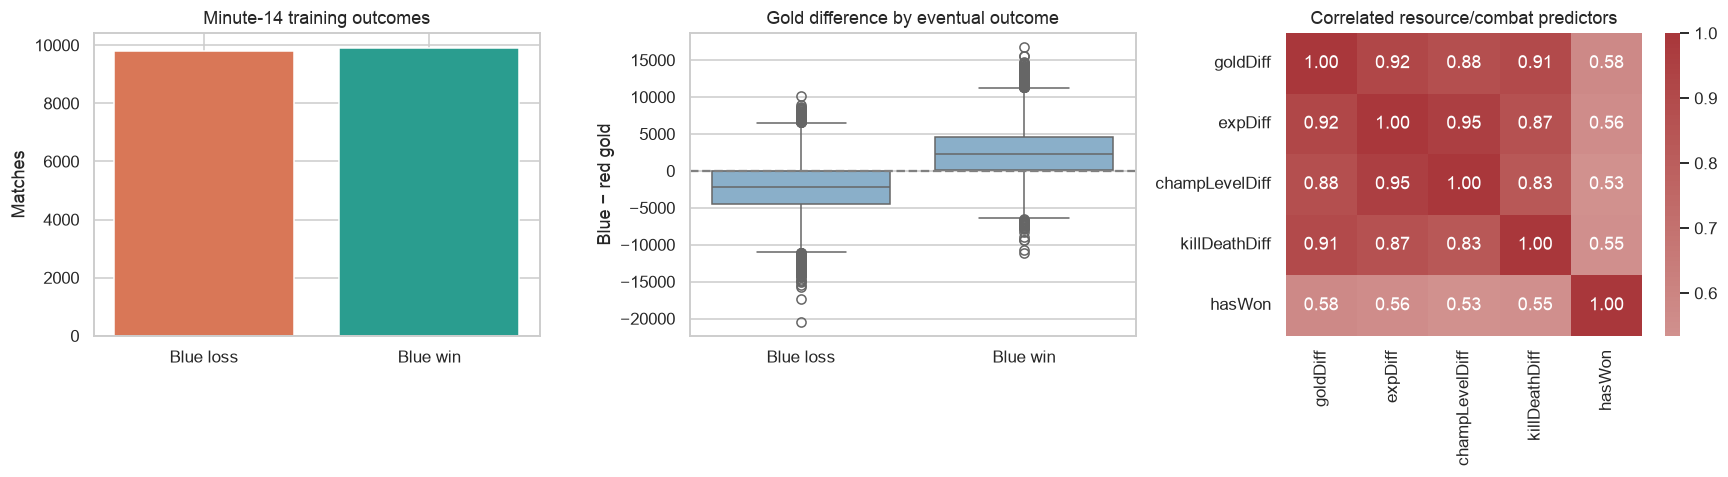

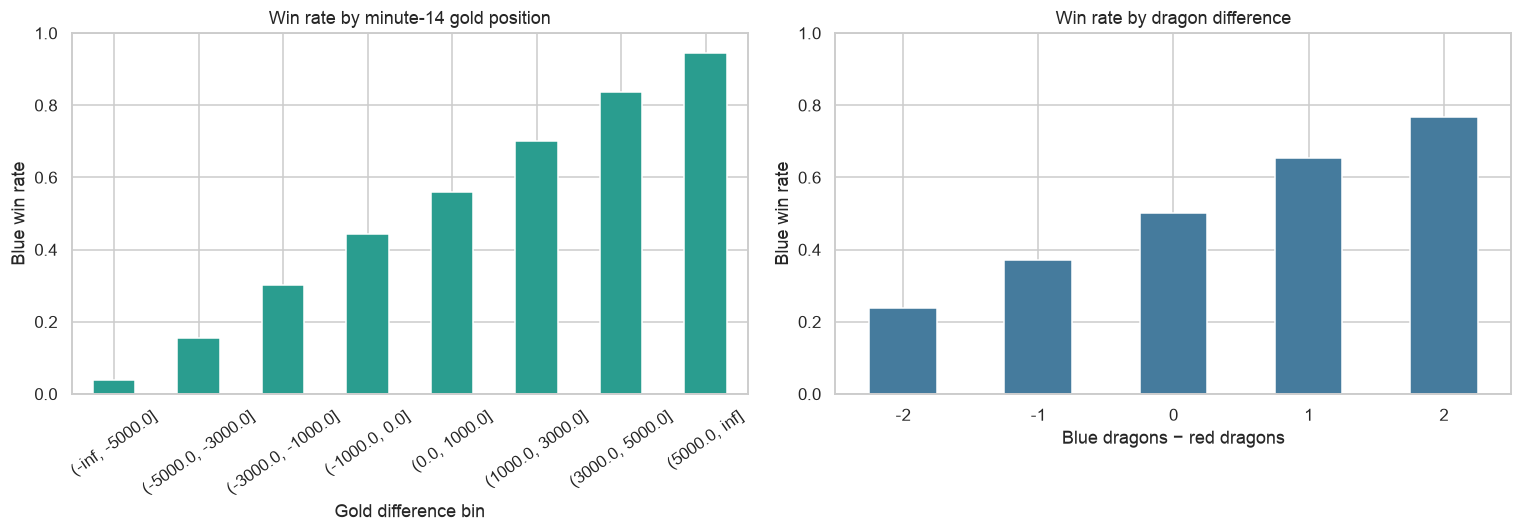

matches  win_rate
deficit trend                             
0–1k    Closing the gap      761     0.473
        Not closing         1171     0.423
1–2k    Closing the gap      414     0.372
        Not closing         1357     0.340
2–3k    Closing the gap      213     0.282
        Not closing         1378     0.245
3–5k    Closing the gap      113     0.221
        Not closing         2214     0.150
5k+     Closing the gap        8     0.250
        Not closing         2103     0.039

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
counts = train14.hasWon.value_counts().reindex([0, 1])
axes[0].bar(["Blue loss", "Blue win"], counts, color=["#d97757", "#2a9d8f"])
axes[0].set(title="Minute-14 training outcomes", ylabel="Matches")
sns.boxplot(data=train14, x="hasWon", y="goldDiff", color="#80b1d3", ax=axes[1])
axes[1].set_xticks([0, 1], ["Blue loss", "Blue win"])
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(title="Gold difference by eventual outcome", xlabel="", ylabel="Blue − red gold")
corr_cols = ["goldDiff", "expDiff", "champLevelDiff", "killDeathDiff", "hasWon"]
sns.heatmap(train14[corr_cols].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[2])
axes[2].set_title("Correlated resource/combat predictors")
save_figure(fig, "training_balance_resources.png")

gold_bins = [-np.inf, -5000, -3000, -1000, 0, 1000, 3000, 5000, np.inf]
gold_curve = (train14.groupby(pd.cut(train14.goldDiff, gold_bins), observed=True)["hasWon"]
              .agg(matches="size", win_rate="mean"))
objective_summary = train14.groupby("dragonDiff")["hasWon"].agg(matches="size", win_rate="mean")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gold_curve.win_rate.plot.bar(ax=axes[0], color="#2a9d8f", rot=35)
axes[0].set(title="Win rate by minute-14 gold position", xlabel="Gold difference bin", ylabel="Blue win rate", ylim=(0, 1))
objective_summary.win_rate.plot.bar(ax=axes[1], color="#457b9d", rot=0)
axes[1].set(title="Win rate by dragon difference", xlabel="Blue dragons − red dragons", ylabel="Blue win rate", ylim=(0, 1))
save_figure(fig, "training_advantage_win_rates.png")

behind = train14.loc[train14.goldDiff.lt(0)].copy()
behind["deficit"] = pd.cut(-behind.goldDiff, [0, 1000, 2000, 3000, 5000, np.inf], labels=["0–1k", "1–2k", "2–3k", "3–5k", "5k+"])
behind["trend"] = np.where(behind.goldChange4.gt(0), "Closing the gap", "Not closing")
comebacks = behind.groupby(["deficit", "trend"], observed=True).hasWon.agg(matches="size", win_rate="mean")
display(comebacks.round(3))

### Clustering of early-game states

Following notebook 01, we standardize six training-only features and compare K-means with k=2…6. The original silhouette comparison favored k=2 (approximately 0.357), separating broadly advantaged and disadvantaged blue-team states. The cluster win rates describe association; the target is not used to fit the clusters. When cluster distances were later used as classifier features, clustering was fit inside each CV training fold.

,clusters,inertia,silhouette,smallest_cluster
0,2,64981.465,0.357,9775
1,3,50109.839,0.273,5030
2,4,43132.323,0.241,4142
3,5,37996.352,0.231,2270
4,6,34029.086,0.222,2248


,matches,goldDiff,expDiff,killDeathDiff,dragonDiff,outerTurretDiff,goldChange4,win_rate
cluster,,,,,,,,
0,9775,3327.500,2304.826,4.555,0.562,0.570,1857.945,0.772
1,9948,-3107.709,-2363.768,-4.223,-0.620,-0.497,-1731.565,0.238


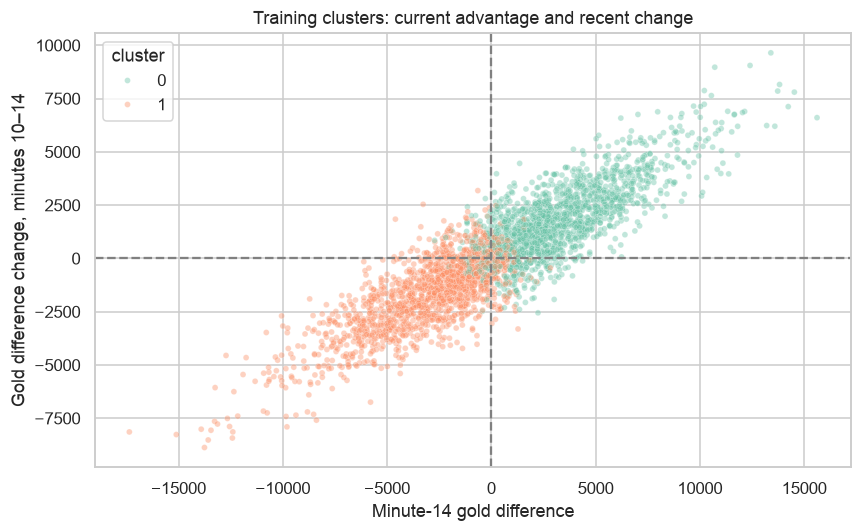

In [7]:
cluster_cols = ["goldDiff", "expDiff", "killDeathDiff", "dragonDiff", "outerTurretDiff", "goldChange4"]
with threadpool_limits(limits=1):
    cluster_X = StandardScaler().fit_transform(train14[cluster_cols])
    cluster_rows = []
    for k in range(2, 7):
        fitted = KMeans(n_clusters=k, random_state=42, n_init=10).fit(cluster_X)
        cluster_rows.append({"clusters": k, "inertia": fitted.inertia_,
            "silhouette": silhouette_score(cluster_X, fitted.labels_, sample_size=2000, random_state=42),
            "smallest_cluster": int(pd.Series(fitted.labels_).value_counts().min())})
    cluster_model = KMeans(n_clusters=2, random_state=42, n_init=10).fit(cluster_X)
cluster_profile_data = train14.assign(cluster=cluster_model.labels_)
cluster_profiles = cluster_profile_data.groupby("cluster")[cluster_cols].mean()
cluster_profiles.insert(0, "matches", cluster_profile_data.groupby("cluster").size())
cluster_profiles["win_rate"] = cluster_profile_data.groupby("cluster").hasWon.mean()
display(pd.DataFrame(cluster_rows).round(3))
display(cluster_profiles.round(3))
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=cluster_profile_data.sample(n=min(3000, len(train14)), random_state=42),
                x="goldDiff", y="goldChange4", hue="cluster", palette="Set2", alpha=0.4, s=15, ax=ax)
ax.axhline(0, color="gray", linestyle="--"); ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Training clusters: current advantage and recent change", xlabel="Minute-14 gold difference", ylabel="Gold difference change, minutes 10–14")
save_figure(fig, "training_clusters.png")

## Modeling

### Evaluation design and baselines

We split the full ordered match list once into 80% training IDs and 20% reserved test IDs, stratified by match outcome with seed 42. Every minute uses those same assignments. Training CV uses five-fold `StratifiedGroupKFold` grouped by `gameId`. Scaling, PCA, clustering distances, and supervised selection are fit using training data; fitted transformations belong inside the CV pipeline.

Metrics are accuracy, ROC AUC, log loss, and Brier score. **Minimum CV log loss** selects hyperparameters because useful win probabilities matter in addition to hard classifications. Accuracy, AUC, and interpretability support the comparison. The majority baseline predicts the fold-training class prior; the gold-lead rule predicts the fold-training win rate conditional on whether blue leads in gold.

The helpers below reproduce the shared evaluation module. Tuning scores and later feature-selection scores reuse CV for selection, so they are not independent unbiased estimates. The reserved test set supplies the final evaluation.

In [8]:
"""Shared cross-validation and scoring helpers (same protocol as notebook 02).

All snapshots of a match stay in one fold (grouped by ``gameId``). Losses are
reported as positive numbers (lower is better).
"""

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate

SEED = 42

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score",
}
LOWER_IS_BETTER = {"log_loss", "brier"}
METRIC_COLS = ["accuracy", "accuracy_sd", "roc_auc", "log_loss", "brier"]


def _positive(raw_scores):
    return {m: -v if m in LOWER_IS_BETTER else v for m, v in raw_scores.items()}


def cv_scores(model, data, cols, target="hasWon", group="gameId"):
    """Per-fold scores for a model with fixed hyperparameters."""
    result = cross_validate(
        model, data[cols], data[target], groups=data[group], cv=cv, scoring=scoring, n_jobs=-1
    )
    return _positive({m: result[f"test_{m}"] for m in scoring})


def tune(model, grid, data, cols, target="hasWon", group="gameId"):
    """Grid search with grouped CV; the best setting is chosen by log loss."""
    search = GridSearchCV(
        model, grid, cv=cv, scoring=scoring, refit="log_loss",
        n_jobs=-1, return_train_score=True,
    )
    search.fit(data[cols], data[target], groups=data[group])
    i = search.best_index_
    scores = {
        m: np.array([search.cv_results_[f"split{k}_test_{m}"][i] for k in range(cv.get_n_splits())])
        for m in scoring
    }
    return search, _positive(scores)


def summarize(model_name, feature_set, scores, params=None, **extra):
    """One results-table row: mean of each metric across folds."""
    row = {"model": model_name, "features": feature_set}
    row.update({m: v.mean() for m, v in scores.items()})
    row["accuracy_sd"] = scores["accuracy"].std()
    row["params"] = params or {}
    # Per-fold scores; folds are identical across feature sets, so they can be paired
    row["fold_accuracy"] = scores["accuracy"].tolist()
    row["fold_log_loss"] = scores["log_loss"].tolist()
    row.update(extra)
    return row


class GoldLeadRule(ClassifierMixin, BaseEstimator):
    """Baseline: predict the training win rate of teams ahead (goldDiff > 0) or not ahead."""

    def fit(self, X, y):
        ahead = np.asarray(X["goldDiff"]) > 0
        y = np.asarray(y)
        self.classes_ = np.array([0, 1])
        self.p_ahead_ = y[ahead].mean()
        self.p_not_ahead_ = y[~ahead].mean()
        return self

    def predict_proba(self, X):
        p = np.where(np.asarray(X["goldDiff"]) > 0, self.p_ahead_, self.p_not_ahead_)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [9]:
with parallel_config(backend="loky", inner_max_num_threads=1), threadpool_limits(limits=1):
    baseline_rows = [summarize("Majority class", "none", cv_scores(DummyClassifier(strategy="prior"), train14, ["goldDiff"])),
                     summarize("Gold-lead rule", "sign of goldDiff", cv_scores(GoldLeadRule(), train14, ["goldDiff"]))]
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results[["model"] + METRIC_COLS].round(4))

,model,accuracy,accuracy_sd,roc_auc,log_loss,brier
0,Majority class,0.5029,0.0001,0.5000,0.6931,0.2500
1,Gold-lead rule,0.7622,0.0078,0.7622,0.5487,0.1813


### Logistic regression, decision trees, and feature ablation

Notebook 02 compared gold alone, three resource differences, changes in advantage, objective summaries, a compact combination, and all nonconstant features. LR uses `StandardScaler → LogisticRegression(max_iter=5000)` and tunes C over 0.001, 0.01, 0.1, 1, and 10. The initial tree grid covered depths 2/3/4/5/6/8/10/unrestricted and leaf minima 1/20/50/100/200. The later grid extends to depths 3/4/6/8/10/12 and leaf minima 100/200/400/800/1600 because the initial trees favored the largest allowed leaves.

Objectives add a small improvement beyond resource differences, while recent changes add little after current resources are included. Very deep trees with small leaves overfit. The completed training-CV results and the original depth diagnostic are retained below.

In [10]:
initial_results = recorded_table("lr_dt_cv_results.csv")
feature_results14 = recorded_table("fe_minute14_results.csv")
feature_results_by_minute = recorded_table("fe_by_minute.csv")
display(initial_results[["model", "features"] + METRIC_COLS + ["params"]].round(4))

,model,features,accuracy,accuracy_sd,roc_auc,log_loss,brier,params
0,Majority class,none,0.5029,0.0001,0.5000,0.6931,0.2500,{}
1,Gold-lead rule,sign of goldDiff,0.7622,0.0078,0.7622,0.5487,0.1813,{}
2,Logistic regression,Gold only,0.7623,0.0086,0.8453,0.4851,0.1606,{'logisticregression__C': 1}
3,Logistic regression,Resources,0.7640,0.0093,0.8496,0.4789,0.1582,{'logisticregression__C': 1}
4,Logistic regression,Resources + changes,0.7641,0.0099,0.8496,0.4789,0.1583,{'logisticregression__C': 1}
5,Logistic regression,Resources + objectives,0.7710,0.0091,0.8554,0.4707,0.1551,{'logisticregression__C': 10}
6,Logistic regression,Compact,0.7712,0.0085,0.8554,0.4708,0.1551,{'logisticregression__C': 1}
7,Logistic regression,All features,0.7705,0.0094,0.8549,0.4715,0.1554,{'logisticregression__C': 0.1}
8,Decision tree,Gold only,0.7611,0.0076,0.8434,0.4868,0.1610,"{'max_depth': 4, 'min_samples_leaf': 200}"
9,Decision tree,Resources,0.7602,0.0083,0.8446,0.4855,0.1603,"{'max_depth': 4, 'min_samples_leaf': 200}"


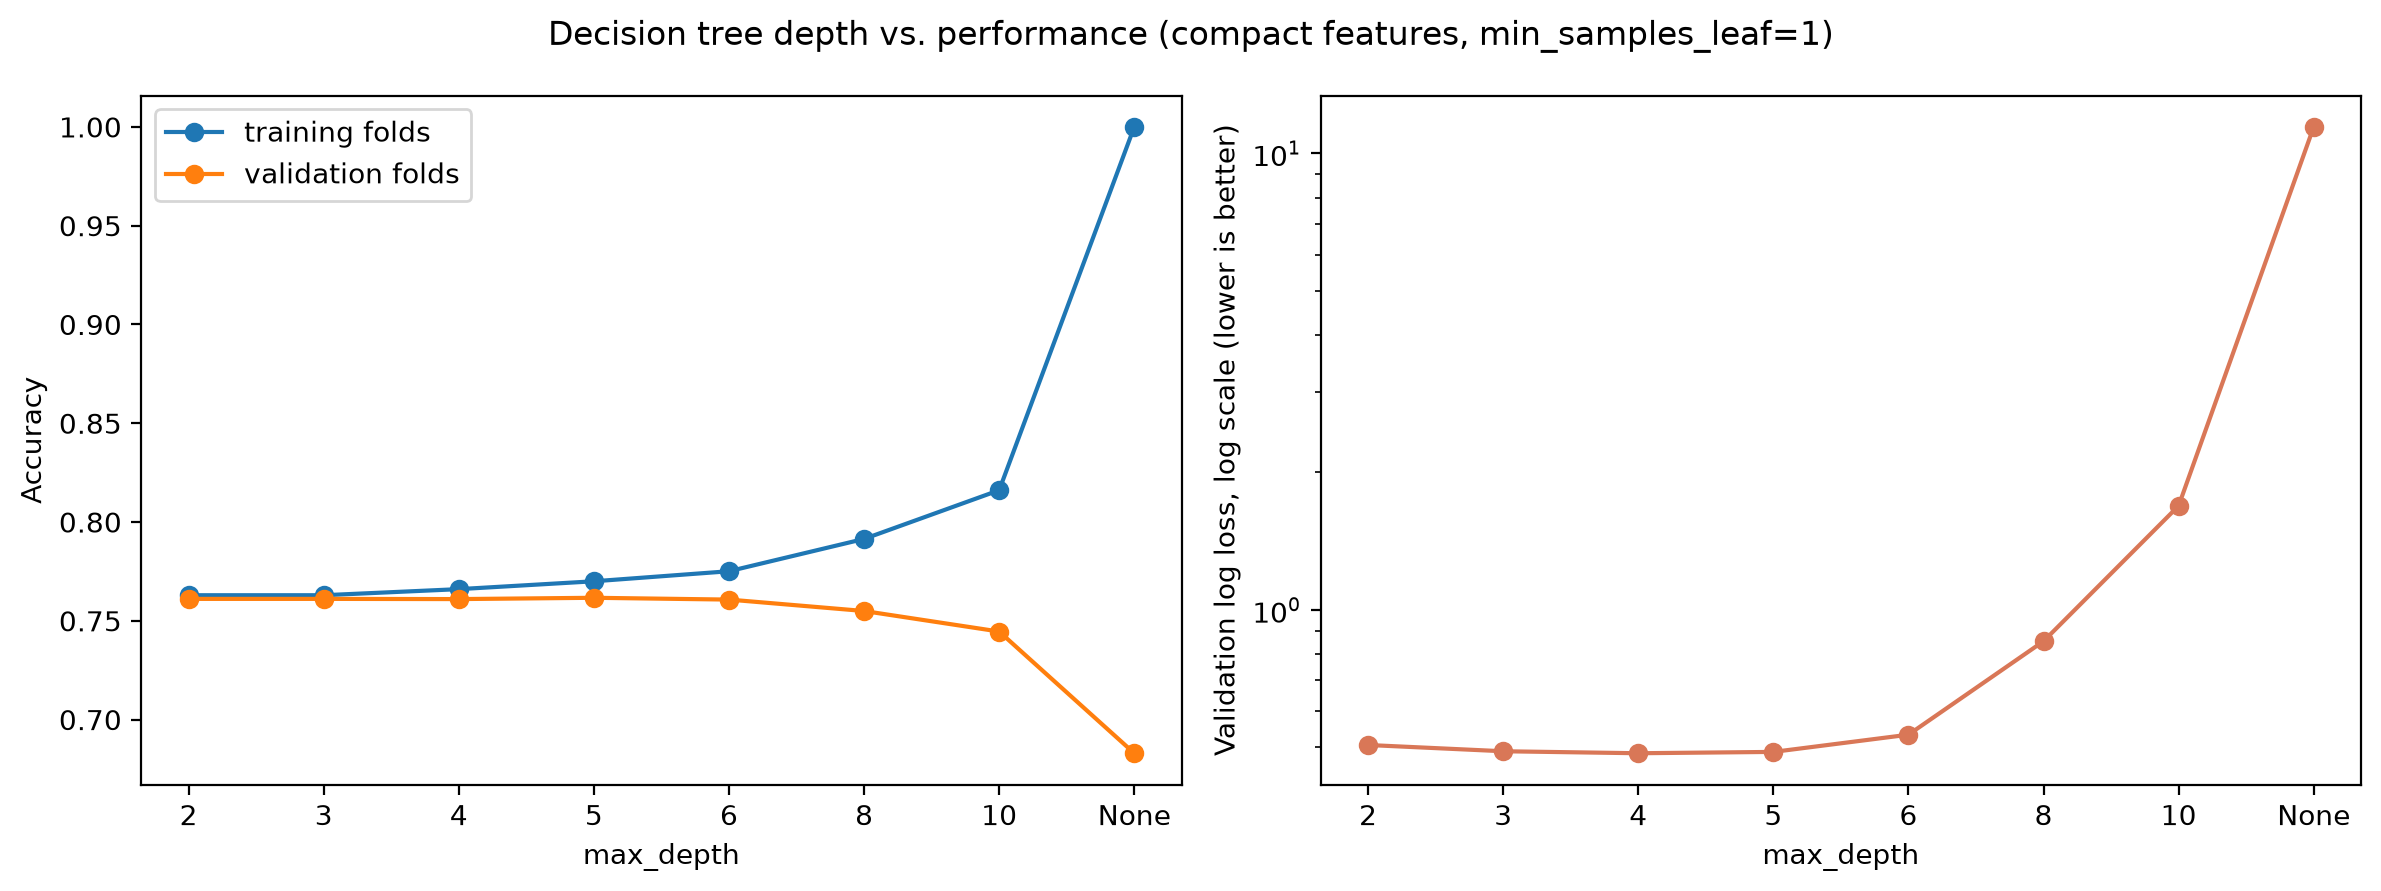

Original notebook-02 training/CV diagnostic: increasing tree depth with min_samples_leaf=1 produces overfitting. This figure records the completed training experiment; it does not use test matches.

### Richer features, transformations, and supervised selection

Notebook 03 compares the original engineered baseline with added objective summaries, trajectories, all engineered features, and a compact engineered set. PCA on the correlated resource features and training-fold K-means distances did not materially improve LR's log loss.

An L1 logistic-regression path used the one-standard-error rule to choose a sparse feature list. At C≈0.0032, it retained **goldDiff, expDiff, dragonDiff, and killShare** from 80 candidates. We then retuned ordinary scaled LR on that fixed list; its selected C is 10. The screening estimator and the final four-feature classifier therefore have different regularization settings. Because the feature list was selected on the full training portion before its downstream CV comparison, the downstream score is a selection result rather than a nested-CV performance estimate.

,model,features,n_features,accuracy,accuracy_sd,roc_auc,log_loss,brier,params
0,Gold-lead rule,sign of goldDiff,1,0.7622,0.0078,0.7622,0.5487,0.1813,{}
1,Logistic regression,Notebook 01 features,58,0.7705,0.0094,0.8549,0.4715,0.1554,{'logisticregression__C': 0.1}
2,Decision tree,Notebook 01 features,58,0.7642,0.0105,0.8483,0.4817,0.1587,"{'max_depth': 8, 'min_samples_leaf': 400}"
3,Logistic regression,+ objective,72,0.7689,0.0093,0.8550,0.4714,0.1554,{'logisticregression__C': 0.1}
4,Decision tree,+ objective,72,0.7658,0.0096,0.8484,0.4818,0.1587,"{'max_depth': 8, 'min_samples_leaf': 400}"
5,Logistic regression,+ trajectory,66,0.7700,0.0098,0.8546,0.4718,0.1556,{'logisticregression__C': 0.01}
6,Decision tree,+ trajectory,66,0.7642,0.0105,0.8478,0.4825,0.1588,"{'max_depth': 8, 'min_samples_leaf': 400}"
7,Logistic regression,All engineered,80,0.7697,0.0092,0.8546,0.4717,0.1555,{'logisticregression__C': 0.01}
8,Decision tree,All engineered,80,0.7658,0.0096,0.8481,0.4824,0.1588,"{'max_depth': 8, 'min_samples_leaf': 400}"
9,Logistic regression,Compact engineered,30,0.7701,0.0087,0.8553,0.4708,0.1552,{'logisticregression__C': 10}


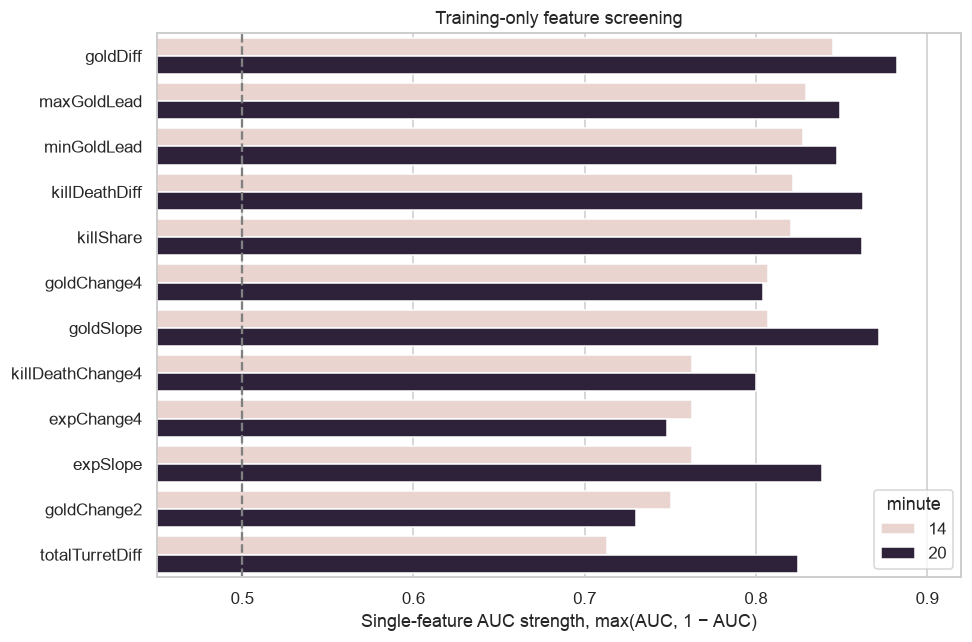

In [11]:
display(feature_results14[["model", "features", "n_features"] + METRIC_COLS + ["params"]].round(4))
train20 = feature_tables[20].loc[feature_tables[20].gameId.isin(train_ids)]
screen_rows = []
for minute, data in [(14, train14), (20, train20)]:
    for feature in OBJECTIVE_FEATURES + TRAJECTORY_FEATURES + ["goldDiff"]:
        auc = roc_auc_score(data.hasWon, data[feature])
        screen_rows.append({"minute": minute, "feature": feature, "auc_strength": max(auc, 1 - auc)})
screen = pd.DataFrame(screen_rows)
top_features = screen.loc[screen.minute.eq(14)].nlargest(12, "auc_strength").feature
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=screen.loc[screen.feature.isin(top_features)], x="auc_strength", y="feature", hue="minute", order=top_features, ax=ax)
ax.axvline(0.5, color="gray", linestyle="--")
ax.set(xlim=(0.45, 0.92), xlabel="Single-feature AUC strength, max(AUC, 1 − AUC)", ylabel="", title="Training-only feature screening")
save_figure(fig, "feature_screening.png")

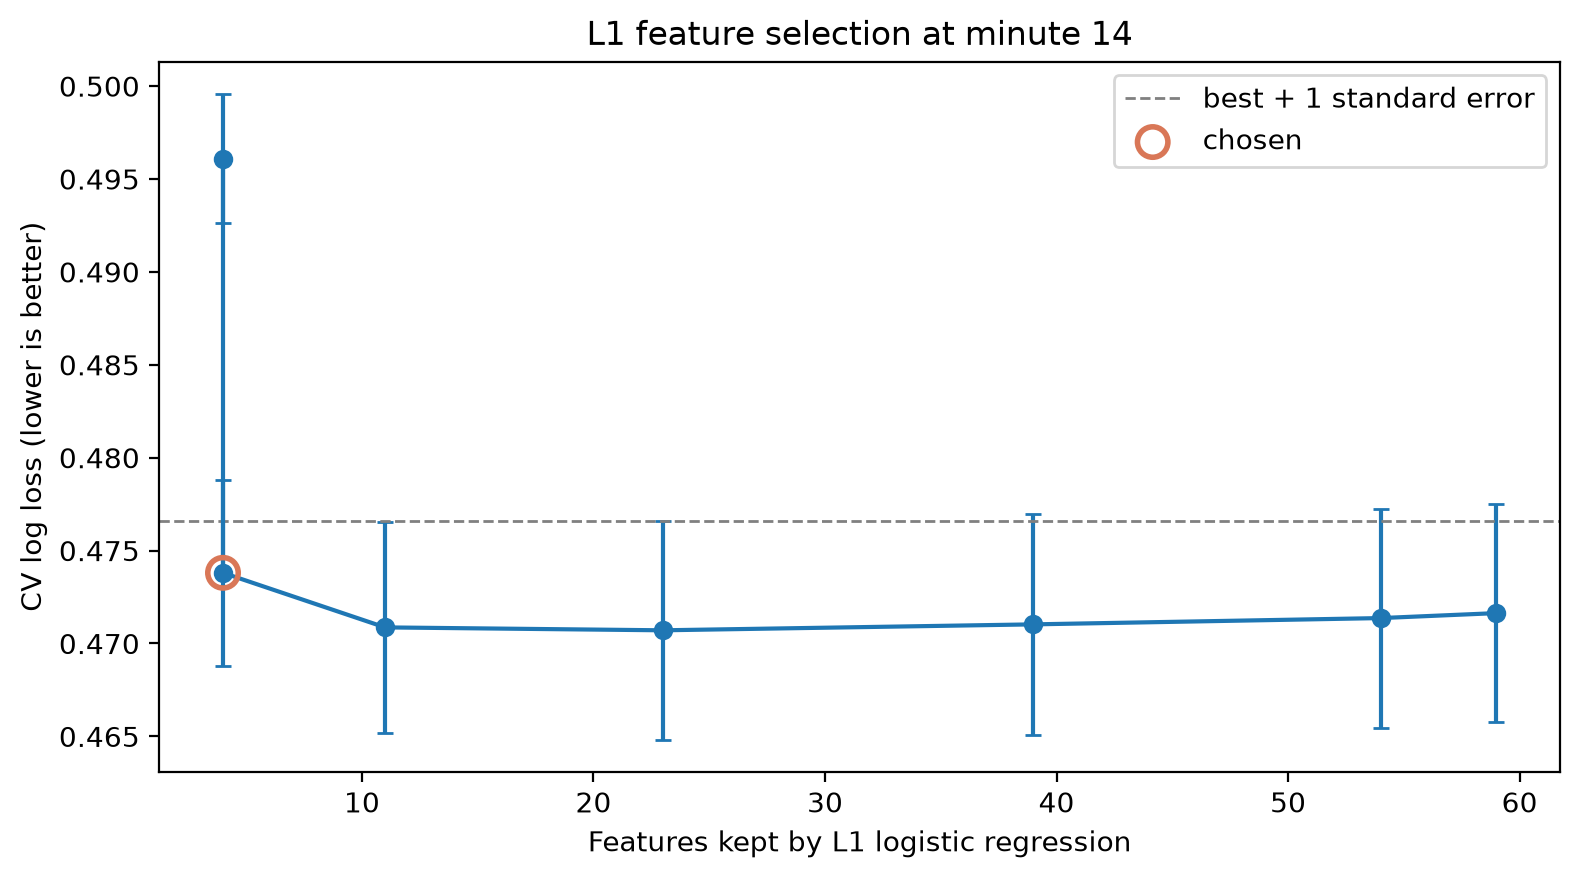

Original notebook-03 L1 path: the one-standard-error rule selects a four-feature list. The error bars describe CV variability during selection.

### Ensemble experiments and reproducible search procedures

Yejune compared the exact notebook-03 baseline and expanded groups at all four prediction times. RF tunes `n_estimators`, `max_depth`, `min_samples_leaf`, and `max_features`; HGB varies learning rate, leaf count, leaf minimum, and L2 regularization with 200 iterations and early stopping disabled. Each ensemble has 16 settings. Two feature sets × four minutes × five folds means 1,280 ensemble CV fits, plus refits.

The functions below include the initial LR/DT comparisons, expanded feature ablation, transformations, L1 screening, and ensemble searches. A normal run displays the embedded completed records. Setting `RECOMPUTE_TRAINING_SEARCHES=True` repeats the original procedures on training matches only, writes results under this submission's output folder, and leaves the pre-test final specifications unchanged.

In [12]:
LR_GRID = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]}
DT_GRID = {"max_depth": [3, 4, 6, 8, 10, 12], "min_samples_leaf": [100, 200, 400, 800, 1600]}
RF_GRID = ARCHIVE["ensemble_protocol"]["random_forest_grid"]
HGB_GRID = ARCHIVE["ensemble_protocol"]["hist_gradient_boosting_grid"]

def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

def initial_feature_sets(data):
    resources = ["goldDiff", "expDiff", "champLevelDiff"]
    changes = ["goldChange4", "expChange4"]
    objectives = ["killDeathDiff", "dragonDiff", "outerTurretDiff", "isFirstTower", "killedRiftHerald", "lostRiftHerald"]
    old_order = feature_groups[14]["raw"] + ["dragonDiff", "goldChange4", "expChange4", "killDeathDiff", "outerTurretDiff"]
    model_cols = [c for c in old_order if data[c].nunique() > 1]
    return {"Gold only": ["goldDiff"], "Resources": resources,
        "Resources + changes": resources + changes, "Resources + objectives": resources + objectives,
        "Compact": resources + changes + objectives, "All features": model_cols}

def run_initial_searches(data):
    rows = []
    models = [("Logistic regression", make_lr(), LR_GRID),
        ("Decision tree", DecisionTreeClassifier(random_state=SEED),
         {"max_depth": [2, 3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 20, 50, 100, 200]})]
    for label, cols in initial_feature_sets(data).items():
        for name, model, grid in models:
            search, scores = tune(model, grid, data, cols)
            rows.append(summarize(name, label, scores, search.best_params_, minute=14))
    return pd.DataFrame(rows)

def run_feature_ablation():
    rows = []
    for minute in MINUTES:
        data = feature_tables[minute].loc[feature_tables[minute].gameId.isin(train_ids)].reset_index(drop=True)
        for label, cols in feature_sets_for(feature_groups[minute], minute).items():
            for name, model, grid in [("Logistic regression", make_lr(), LR_GRID),
                    ("Decision tree", DecisionTreeClassifier(random_state=SEED), DT_GRID)]:
                search, scores = tune(model, grid, data, cols)
                rows.append(summarize(name, label, scores, search.best_params_, minute=minute, n_features=len(cols)))
    return pd.DataFrame(rows)

def run_transformations_and_selection(data):
    resources = ["goldDiff", "expDiff", "champLevelDiff"]
    cols = feature_sets_for(feature_groups[14], 14)["All engineered"]
    others = [c for c in cols if c not in resources]
    pca_lr = make_pipeline(ColumnTransformer([
        ("resources", make_pipeline(StandardScaler(), PCA(random_state=SEED)), resources),
        ("rest", StandardScaler(), others)]), LogisticRegression(max_iter=5000))
    kmeans_lr = make_pipeline(FeatureUnion([
        ("scaled", StandardScaler()),
        ("clusters", make_pipeline(StandardScaler(), KMeans(n_init=10, random_state=SEED)))]),
        StandardScaler(), LogisticRegression(max_iter=5000))
    rows = []
    for label, model, grid in [
        ("PCA on resources", pca_lr, {"columntransformer__resources__pca__n_components": [1, 2], "logisticregression__C": [0.1, 1]}),
        ("K-means distances", kmeans_lr, {"featureunion__clusters__kmeans__n_clusters": [2, 4, 8], "logisticregression__C": [0.1, 1]})]:
        search, scores = tune(model, grid, data, cols)
        rows.append(summarize("Logistic regression", label, scores, search.best_params_))
    path = []
    for C in np.logspace(-3, 0, 7):
        model = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=5000))
        scores = cv_scores(model, data, cols)
        model.fit(data[cols], data.hasWon)
        kept = [c for c, weight in zip(cols, model[-1].coef_[0]) if weight != 0]
        path.append({"C": C, "n_kept": len(kept), "kept": kept, "log_loss": scores["log_loss"].mean(),
            "log_loss_se": scores["log_loss"].std(ddof=1) / np.sqrt(5)})
    path = pd.DataFrame(path)
    best = path.loc[path.log_loss.idxmin()]
    within = path.loc[path.log_loss.le(best.log_loss + best.log_loss_se)]
    selected = within.loc[within.n_kept.idxmin(), "kept"]
    for name, model, grid in [("Logistic regression", make_lr(), LR_GRID),
            ("Decision tree", DecisionTreeClassifier(random_state=SEED), DT_GRID)]:
        search, scores = tune(model, grid, data, selected)
        rows.append(summarize(name, "L1-selected", scores, search.best_params_))
    return pd.DataFrame(rows), path

def run_ensemble_searches():
    rows = []
    for minute in MINUTES:
        data = feature_tables[minute].loc[feature_tables[minute].gameId.isin(train_ids)].reset_index(drop=True)
        all_sets = feature_sets_for(feature_groups[minute], minute)
        expanded = all_sets["All engineered"] if "All engineered" in all_sets else all_sets["+ objective"]
        for label, cols in {"Notebook 01 features": all_sets["Notebook 01 features"], "All engineered": expanded}.items():
            for name, model, grid in [
                ("Random forest", RandomForestClassifier(random_state=SEED, n_jobs=1), RF_GRID),
                ("HistGradientBoosting", HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), HGB_GRID)]:
                search, scores = tune(model, grid, data, cols)
                rows.append(summarize(name, label, scores, search.best_params_, minute=minute, n_features=len(cols)))
    return pd.DataFrame(rows)

if RECOMPUTE_TRAINING_SEARCHES:
    with parallel_config(backend="loky", inner_max_num_threads=1), threadpool_limits(limits=1):
        repeated_initial = run_initial_searches(train14)
        repeated_ablation = run_feature_ablation()
        repeated_transforms, repeated_l1_path = run_transformations_and_selection(train14)
        repeated_ensembles = run_ensemble_searches()
    for name, frame in [("initial", repeated_initial), ("ablation", repeated_ablation),
                        ("transformations", repeated_transforms), ("l1_path", repeated_l1_path), ("ensembles", repeated_ensembles)]:
        frame.to_csv(report_dir / f"reproduced_training_{name}.csv", index=False)
    print("Repeated fixed training search procedures; frozen final configurations are unchanged.")
else:
    print("Using the completed training-CV records embedded above.")

ensemble_records = recorded_table("ensemble_by_minute.csv")
matching_records = recorded_table("ensemble_all_models_by_minute.csv")
paired_gain = recorded_table("ensemble_paired_gain.csv")
display(ensemble_records.loc[ensemble_records.minute.eq(14), ["model", "features", "n_features"] + METRIC_COLS + ["params"]].round(4))
display(paired_gain.loc[paired_gain.model.isin(["Random forest", "HistGradientBoosting"])].round(5))

Using the completed training-CV records embedded above.


,model,features,n_features,accuracy,accuracy_sd,roc_auc,log_loss,brier,params
5,Gold-lead rule,sign of goldDiff,1,0.7622,0.0078,0.7622,0.5487,0.1813,{}
6,Random forest,Notebook 01 features,58,0.7697,0.0102,0.8536,0.4735,0.1561,"{'max_depth': 8, 'max_features': 0.5, 'min_sam..."
7,HistGradientBoosting,Notebook 01 features,58,0.7698,0.0091,0.8529,0.4747,0.1566,"{'l2_regularization': 1.0, 'learning_rate': 0...."
8,Random forest,All engineered,80,0.7682,0.0089,0.8537,0.4733,0.1561,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
9,HistGradientBoosting,All engineered,80,0.7680,0.0097,0.8525,0.4753,0.1567,"{'l2_regularization': 1.0, 'learning_rate': 0...."


,model,minute,features,log_loss_reduction,log_loss_se,accuracy_gain_pp,accuracy_se_pp
4,HistGradientBoosting,10,All engineered,-0.00021,0.00071,-0.25110,0.13312
5,HistGradientBoosting,14,All engineered,-0.00068,0.00050,-0.17240,0.08113
6,HistGradientBoosting,18,All engineered,-0.00024,0.00074,0.25855,0.07971
7,HistGradientBoosting,20,All engineered,-0.00001,0.00074,-0.06763,0.20651
12,Random forest,10,All engineered,-0.00013,0.00042,0.08037,0.13058
13,Random forest,14,All engineered,0.00022,0.00053,-0.14704,0.10057
14,Random forest,18,All engineered,-0.00015,0.00023,0.29087,0.09575
15,Random forest,20,All engineered,0.00024,0.00044,0.03947,0.06214


### Training findings and pre-test choices

At minute 14, the four-feature LR reaches 77.10% CV accuracy and 0.4705 log loss; RF's selected expanded set reaches 76.82% and 0.4733, HGB's baseline set 76.98% and 0.4747, and the four-feature tree 76.50% and 0.4816. These are training-selection scores.

Expanded features produce no consistent ensemble improvement: RF's minute-14 log-loss reduction is 0.000220 with descriptive SE 0.000535; its minute-20 reduction is 0.000237 with SE 0.000440. HGB's expanded features slightly worsen log loss at all four times. Accuracy and log loss sometimes favor different feature sets, so we preserve the stated log-loss criterion. Paired fold errors overlap in training data and supported tuning, so these SEs are not an independent significance test.

LR/DT minute-14 choices use Isaac's four-feature candidates. At other minutes, their configurations minimize the saved feature-ablation CV log loss. RF/HGB choices come from notebook 04. Several grid optima lie at boundaries; HGB used 200 iterations. The claims concern the tested configurations, not every possible ensemble.

The original pre-test manifest below identifies all 16 frozen configurations and the preferred primary model. No choices are changed using the test results.

,minute,model,feature_set,n_features,train_matches,test_matches,cv_log_loss,params
0,10,Logistic regression,Compact engineered,20,19912,4978,0.5379,"{'C': 0.1, 'max_iter': 5000}"
1,10,Decision tree,Notebook 01 features,56,19912,4978,0.5449,"{'max_depth': 6, 'min_samples_leaf': 400, 'ran..."
2,10,Random forest,Notebook 01 features,56,19912,4978,0.5410,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
3,10,HistGradientBoosting,Notebook 01 features,56,19912,4978,0.5429,"{'categorical_features': 'from_dtype', 'class_..."
4,14,Logistic regression,L1-selected,4,19723,4927,0.4705,"{'C': 10.0, 'max_iter': 5000}"
5,14,Decision tree,L1-selected,4,19723,4927,0.4816,"{'max_depth': 6, 'min_samples_leaf': 400, 'ran..."
6,14,Random forest,All engineered,80,19723,4927,0.4733,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
7,14,HistGradientBoosting,Notebook 01 features,58,19723,4927,0.4747,"{'categorical_features': 'from_dtype', 'class_..."
8,18,Logistic regression,Compact engineered,30,18565,4633,0.4248,"{'C': 0.1, 'max_iter': 5000}"
9,18,Decision tree,Compact engineered,30,18565,4633,0.4395,"{'max_depth': 8, 'min_samples_leaf': 400, 'ran..."


Preferred minute-14 model chosen from CV: Logistic regression
Original pre-test freeze ID: 29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048


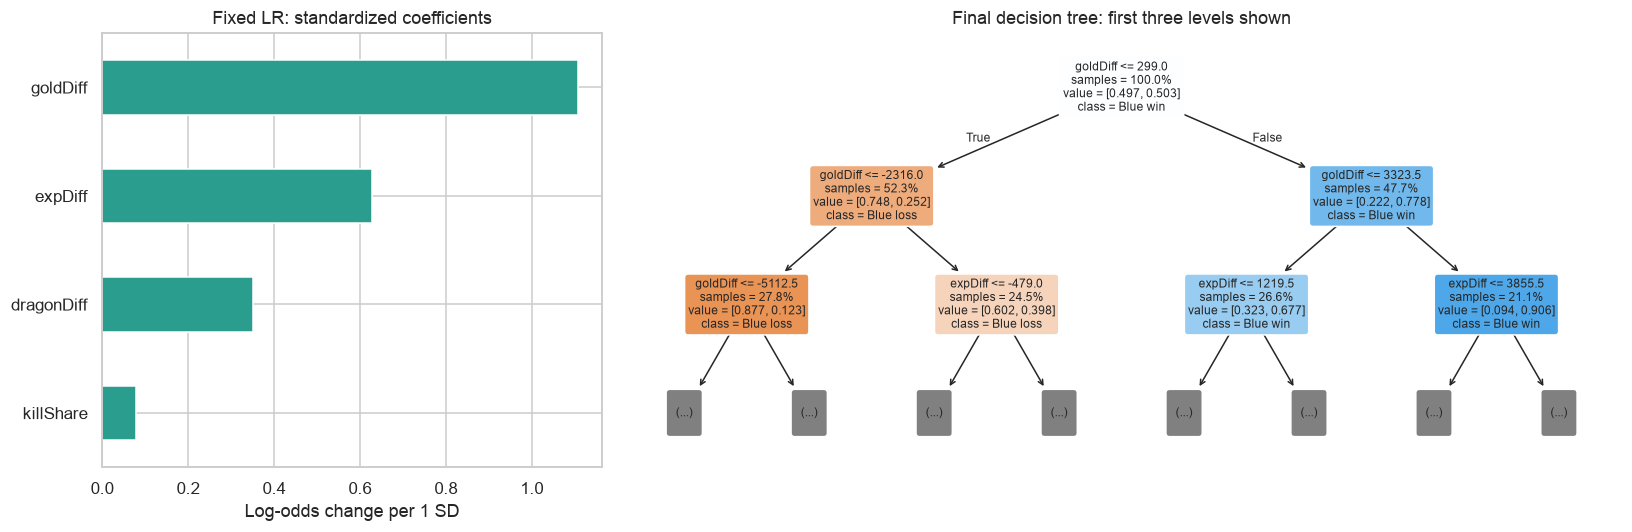

In [13]:
specs = frozen_manifest["models"]
PRIMARY_MODEL = frozen_manifest["preferred_model_from_cv"]
spec_table = pd.DataFrame(specs)
assert PRIMARY_MODEL == "Logistic regression"
for spec in specs:
    table = feature_tables[spec["minute"]]
    cols = spec["feature_columns"]
    assert len(cols) == spec["n_features"] and len(cols) == len(set(cols))
    assert not {"gameId", "hasWon", "gameDuration", "frame", "split"}.intersection(cols)
    assert int(table.gameId.isin(train_ids).sum()) == spec["train_matches"]
    assert int(table.gameId.isin(test_ids).sum()) == spec["test_matches"]
    assert np.isfinite(table[cols].to_numpy()).all()
manifest_path = report_dir / "final_model_specs.json"
save_json(manifest_path, frozen_manifest)
display(spec_table[["minute", "model", "feature_set", "n_features", "train_matches", "test_matches", "cv_log_loss", "params"]].round(4))
print("Preferred minute-14 model chosen from CV:", PRIMARY_MODEL)
print("Original pre-test freeze ID:", freeze_id)

# Train-only interpretation of the fixed four-feature LR and the final decision tree.
lr_spec = next(s for s in specs if s["minute"] == 14 and s["model"] == "Logistic regression")
tree_spec = next(s for s in specs if s["minute"] == 14 and s["model"] == "Decision tree")
with threadpool_limits(limits=1):
    interpret_lr = make_pipeline(StandardScaler(), LogisticRegression(**lr_spec["params"])).fit(train14[lr_spec["feature_columns"]], train14.hasWon)
    interpret_tree = DecisionTreeClassifier(**tree_spec["params"]).fit(train14[tree_spec["feature_columns"]], train14.hasWon)
coefs = pd.Series(interpret_lr[-1].coef_[0], index=lr_spec["feature_columns"]).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2]})
coefs.plot.barh(ax=axes[0], color="#2a9d8f")
axes[0].set(title="Fixed LR: standardized coefficients", xlabel="Log-odds change per 1 SD")
plot_tree(interpret_tree, feature_names=tree_spec["feature_columns"], class_names=["Blue loss", "Blue win"],
          max_depth=2, filled=True, rounded=True, impurity=False, proportion=True, fontsize=8, ax=axes[1])
axes[1].set_title("Final decision tree: first three levels shown")
save_figure(fig, "fixed_model_interpretation.png")

## Results & Analysis

### Frozen final refits and predictions

All models were refit on the full eligible training cohort at their prediction minute and evaluated in the final stage with threshold 0.5. We reproduce those same choices here. A valid original prediction checkpoint is read without refitting; if no checkpoint is available, the fixed model is refit from the raw-derived training table and its resulting metrics are checked against the recorded final evaluation. This does not retune or select a model after inspecting test performance.

In [14]:
reference_test_metrics = recorded_table("final_test_comparison.csv")

def make_model(spec):
    if spec["model"] == "Logistic regression":
        return make_pipeline(StandardScaler(), LogisticRegression(**spec["params"]))
    constructors = {"Decision tree": DecisionTreeClassifier, "Random forest": RandomForestClassifier,
                    "HistGradientBoosting": HistGradientBoostingClassifier}
    return constructors[spec["model"]](**spec["params"])

def validate_predictions(frame, spec, test):
    assert len(frame) == len(test) == spec["test_matches"]
    assert frame.gameId.is_unique and frame.gameId.tolist() == test.gameId.tolist()
    assert frame.gameId.isin(test_ids).all() and not frame.gameId.isin(train_ids).any()
    assert frame.minute.eq(spec["minute"]).all() and frame.model.eq(spec["model"]).all()
    assert np.array_equal(frame.y_true.to_numpy(), test.hasWon.to_numpy())
    assert np.isfinite(frame.p_blue_win).all() and frame.p_blue_win.between(0, 1).all()
    assert np.array_equal(frame.y_pred.to_numpy(), frame.p_blue_win.ge(spec["threshold"]).astype(int).to_numpy())

def validate_original_metrics(frame, spec):
    reference = reference_test_metrics.loc[reference_test_metrics.minute.eq(spec["minute"])
                                          & reference_test_metrics.model.eq(spec["model"])].iloc[0]
    measured = [accuracy_score(frame.y_true, frame.y_pred), roc_auc_score(frame.y_true, frame.p_blue_win),
                log_loss(frame.y_true, frame.p_blue_win), brier_score_loss(frame.y_true, frame.p_blue_win)]
    np.testing.assert_allclose(measured, reference[METRICS].to_numpy(dtype=float), rtol=1e-9, atol=1e-11,
                               err_msg="Frozen evaluation did not reproduce; check software and data rather than changing models.")

def reproduce_final_prediction(spec):
    assert spec in frozen_manifest["models"]
    table = feature_tables[spec["minute"]]
    train = table.loc[table.gameId.isin(train_ids)].reset_index(drop=True)
    test = table.loc[table.gameId.isin(test_ids)].reset_index(drop=True)
    stem = f"minute{spec['minute']}_{spec['model'].lower().replace(' ', '_')}"
    expected = ARCHIVE["prediction_checkpoints"][stem]
    for folder in (root / "reports/final_predictions", prediction_dir):
        candidate = folder / f"{stem}.csv"
        if candidate.is_file() and file_sha256(candidate) == expected["prediction_sha256"]:
            frame = pd.read_csv(candidate, float_precision="round_trip")
            validate_predictions(frame, spec, test)
            validate_original_metrics(frame, spec)
            print("Reuse frozen predictions:", spec["minute"], spec["model"], flush=True)
            return frame
    print("Reproduce frozen refit:", spec["minute"], spec["model"], flush=True)
    model = make_model(spec)
    with threadpool_limits(limits=1):
        model.fit(train[spec["feature_columns"]], train.hasWon)
        p = model.predict_proba(test[spec["feature_columns"]])[:, list(model.classes_).index(1)]
    frame = pd.DataFrame({"gameId": test.gameId.to_numpy(), "minute": spec["minute"], "model": spec["model"],
                          "y_true": test.hasWon.to_numpy(), "p_blue_win": p,
                          "y_pred": (p >= spec["threshold"]).astype(int)})
    validate_predictions(frame, spec, test)
    validate_original_metrics(frame, spec)
    save_csv(frame, prediction_dir / f"{stem}.csv")
    return frame

predictions = pd.concat([reproduce_final_prediction(spec) for spec in specs], ignore_index=True)
assert len(predictions) == 75812 and not predictions.duplicated(["minute", "model", "gameId"]).any()
save_csv(predictions, report_dir / "final_test_predictions.csv")

Reuse frozen predictions: 10 Logistic regression
Reuse frozen predictions: 10 Decision tree
Reuse frozen predictions: 10 Random forest
Reuse frozen predictions: 10 HistGradientBoosting
Reuse frozen predictions: 14 Logistic regression
Reuse frozen predictions: 14 Decision tree
Reuse frozen predictions: 14 Random forest
Reuse frozen predictions: 14 HistGradientBoosting
Reuse frozen predictions: 18 Logistic regression
Reuse frozen predictions: 18 Decision tree
Reuse frozen predictions: 18 Random forest
Reuse frozen predictions: 18 HistGradientBoosting
Reuse frozen predictions: 20 Logistic regression
Reuse frozen predictions: 20 Decision tree
Reuse frozen predictions: 20 Random forest
Reuse frozen predictions: 20 HistGradientBoosting


In [15]:
spec_lookup = {(spec["minute"], spec["model"]): spec for spec in specs}

def score_predictions(frame):
    y, p = frame["y_true"], frame["p_blue_win"]
    return {
        "n_test": len(frame), "accuracy": accuracy_score(y, frame["y_pred"]),
        "roc_auc": roc_auc_score(y, p) if y.nunique() == 2 else np.nan,
        "log_loss": log_loss(y, np.column_stack([1 - p, p]), labels=[0, 1]),
        "brier": brier_score_loss(y, p),
    }

metric_rows = []
for (minute, model_name), frame in predictions.groupby(["minute", "model"], sort=True):
    spec = spec_lookup[(minute, model_name)]
    metric_rows.append({"minute": int(minute), "model": model_name,
                        "feature_set": spec["feature_set"], "n_features": spec["n_features"],
                        "n_train": spec["train_matches"], **score_predictions(frame),
                        "cv_accuracy": spec["cv_accuracy"], "cv_log_loss": spec["cv_log_loss"]})
final_metrics = pd.DataFrame(metric_rows)
save_csv(final_metrics, report_dir / "final_test_comparison.csv")
primary_metrics = final_metrics.loc[final_metrics["minute"].eq(PRIMARY_MINUTE)].set_index("model").loc[MODEL_ORDER].reset_index()
save_csv(primary_metrics, report_dir / "final_test_minute14_comparison.csv")
print("Primary minute-14 held-out comparison; preferred model from CV:", PRIMARY_MODEL)
display(primary_metrics[["model", "feature_set", "n_train", "n_test", "cv_log_loss"] + METRICS].round(4))
print("All prediction times:")
display(final_metrics[["minute", "model", "n_test"] + METRICS].round(4))

Primary minute-14 held-out comparison; preferred model from CV: Logistic regression


,model,feature_set,n_train,n_test,cv_log_loss,accuracy,roc_auc,log_loss,brier
0,Logistic regression,L1-selected,19723,4927,0.4705,0.7719,0.8596,0.4634,0.1529
1,Decision tree,L1-selected,19723,4927,0.4816,0.7658,0.8512,0.4757,0.1572
2,Random forest,All engineered,19723,4927,0.4733,0.7672,0.8585,0.4656,0.1536
3,HistGradientBoosting,Notebook 01 features,19723,4927,0.4747,0.7707,0.8575,0.4664,0.1540


All prediction times:


,minute,model,n_test,accuracy,roc_auc,log_loss,brier
0,10,Decision tree,4978,0.7226,0.7976,0.5459,0.1836
1,10,HistGradientBoosting,4978,0.7266,0.8031,0.5394,0.1812
2,10,Logistic regression,4978,0.7312,0.8056,0.5355,0.1800
3,10,Random forest,4978,0.7296,0.8036,0.5380,0.1809
4,14,Decision tree,4927,0.7658,0.8512,0.4757,0.1572
5,14,HistGradientBoosting,4927,0.7707,0.8575,0.4664,0.1540
6,14,Logistic regression,4927,0.7719,0.8596,0.4634,0.1529
7,14,Random forest,4927,0.7672,0.8585,0.4656,0.1536
8,18,Decision tree,4633,0.7837,0.8733,0.4479,0.1447
9,18,HistGradientBoosting,4633,0.7962,0.8796,0.4328,0.1411


### Minute-14 results and probability diagnostics

The CV-preferred four-feature LR achieved **77.19% accuracy, 0.8596 AUC, 0.4634 log loss, and 0.1529 Brier score** on 4,927 reserved matches. It also has the lowest observed test log loss among the four finalists. HGB has 77.07% accuracy, RF 76.72%, and the tree 76.58%. These small observed gaps do not establish a statistically significant ranking.

The ROC curve evaluates ranking; confusion matrices use threshold 0.5; calibration curves compare predicted probabilities with observed win rates. No probability calibrator is fit on the test set. Bin counts are shown because sparse probability ranges can be unstable.

The descriptive 10-bin calibration error is approximately 0.008 for LR, 0.011 for HGB, 0.014 for the tree, and 0.018 for RF. LR has the smallest observed discrepancy under this binning, consistent with its probability-quality metrics. This summary depends on bin boundaries and sampling variation and was not used to select or recalibrate a model.

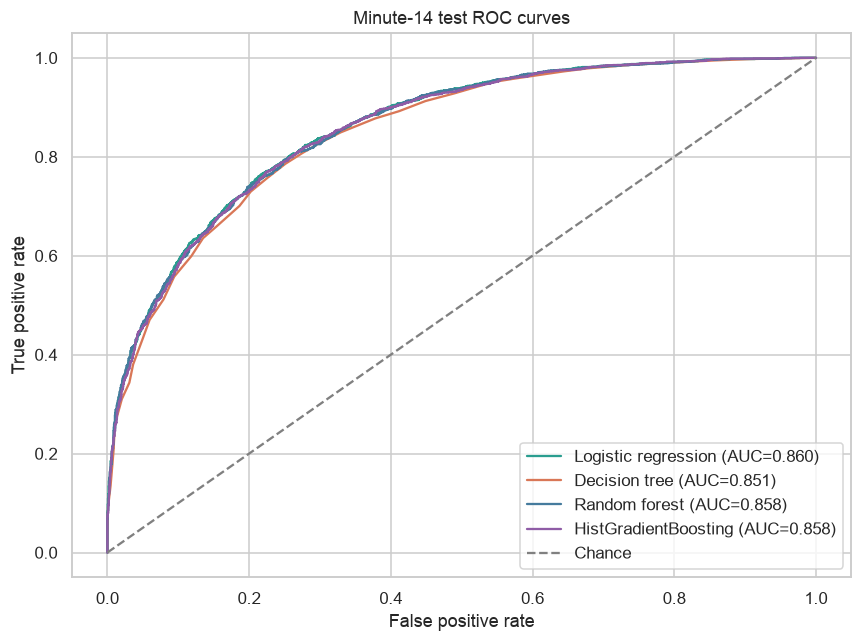

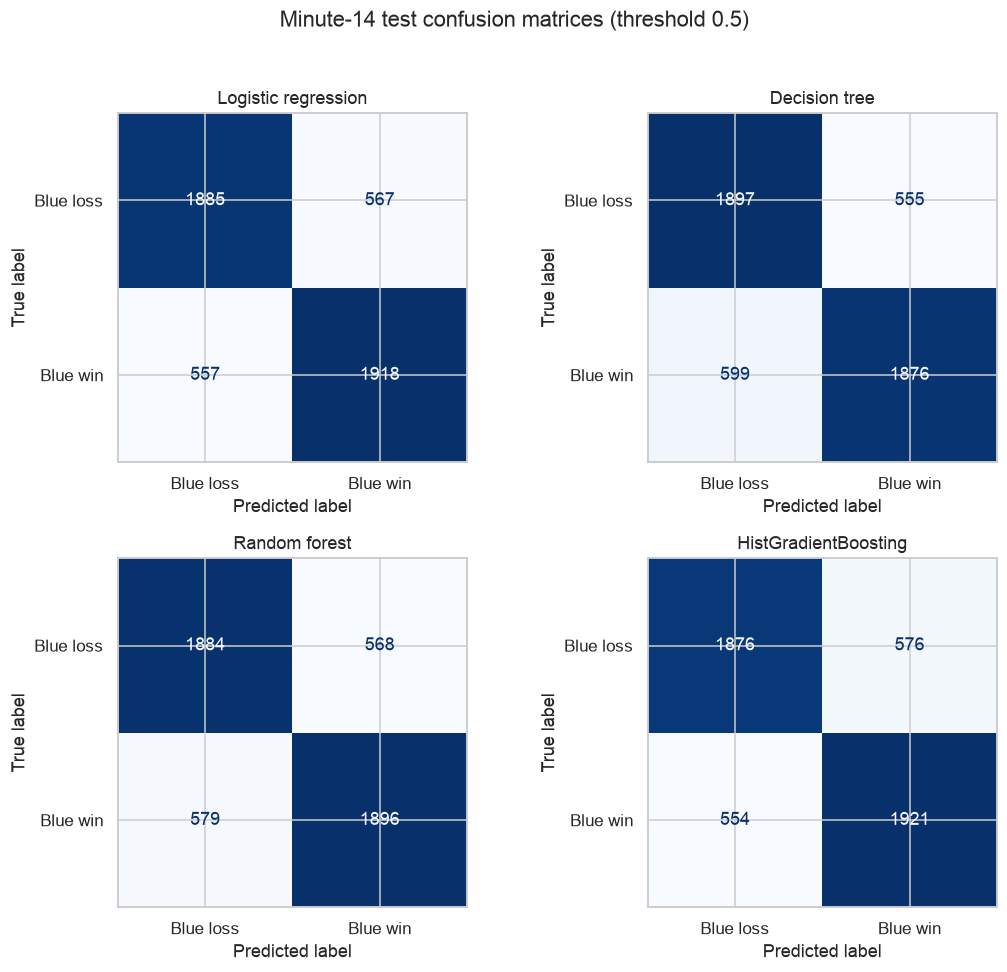

In [16]:
primary_predictions = predictions.loc[predictions["minute"].eq(PRIMARY_MINUTE)].copy()
fig, ax = plt.subplots(figsize=(8, 6))
roc_rows = []
for name in MODEL_ORDER:
    frame = primary_predictions.loc[primary_predictions["model"].eq(name)]
    fpr, tpr, thresholds = roc_curve(frame["y_true"], frame["p_blue_win"])
    auc = roc_auc_score(frame["y_true"], frame["p_blue_win"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", color=MODEL_COLORS[name])
    roc_rows.extend({"minute": PRIMARY_MINUTE, "model": name, "fpr": float(f),
                     "tpr": float(t), "threshold": float(c)} for f, t, c in zip(fpr, tpr, thresholds))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Minute-14 test ROC curves")
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "final_test_roc_minute14.png", dpi=180, bbox_inches="tight")
save_csv(pd.DataFrame(roc_rows), report_dir / "final_test_roc_points.csv")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
confusion_rows = []
for ax, name in zip(axes.flat, MODEL_ORDER):
    frame = primary_predictions.loc[primary_predictions["model"].eq(name)]
    matrix = confusion_matrix(frame["y_true"], frame["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Blue loss", "Blue win"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name)
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({"model": name, "minute": PRIMARY_MINUTE,
                           "true_negative": int(tn), "false_positive": int(fp),
                           "false_negative": int(fn), "true_positive": int(tp)})
fig.suptitle("Minute-14 test confusion matrices (threshold 0.5)")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figure_dir / "final_test_confusion_minute14.png", dpi=180, bbox_inches="tight")
save_csv(pd.DataFrame(confusion_rows), report_dir / "final_test_confusion_counts.csv")
plt.show()

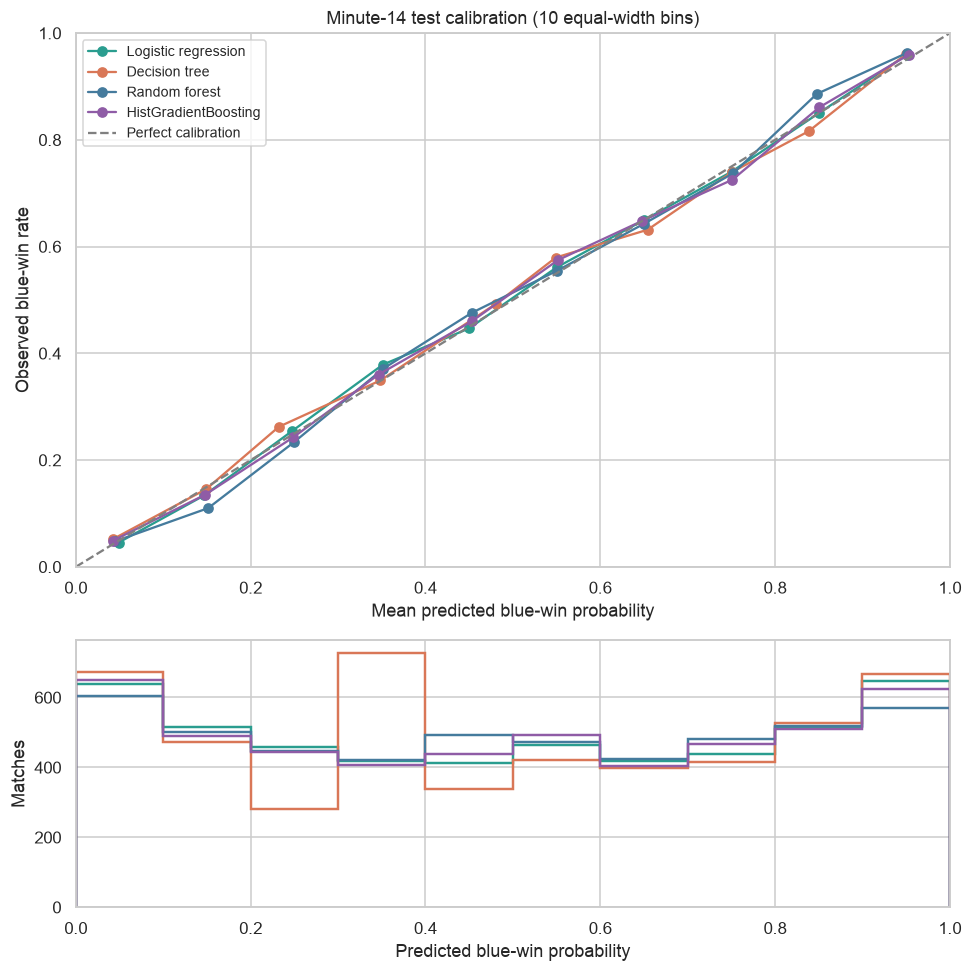

In [17]:
calibration_frames = []
for (minute, name), frame in predictions.groupby(["minute", "model"]):
    frame = frame.copy()
    frame["probability_bin"] = pd.cut(frame["p_blue_win"], np.linspace(0, 1, 11), include_lowest=True)
    bins = (frame.groupby("probability_bin", observed=True)
            .agg(matches=("y_true", "size"), mean_probability=("p_blue_win", "mean"),
                 observed_win_rate=("y_true", "mean")).reset_index())
    bins["probability_bin"] = bins["probability_bin"].astype(str)
    bins["minute"], bins["model"] = minute, name
    calibration_frames.append(bins)
calibration_bins = pd.concat(calibration_frames, ignore_index=True)
save_csv(calibration_bins, report_dir / "final_test_calibration_bins.csv")

fig, (ax, histogram_ax) = plt.subplots(2, 1, figsize=(9, 9), gridspec_kw={"height_ratios": [2, 1]})
for name in MODEL_ORDER:
    bins = calibration_bins.loc[calibration_bins["minute"].eq(PRIMARY_MINUTE)
                                & calibration_bins["model"].eq(name)]
    ax.plot(bins["mean_probability"], bins["observed_win_rate"], marker="o",
            color=MODEL_COLORS[name], label=name)
    probabilities = primary_predictions.loc[primary_predictions["model"].eq(name), "p_blue_win"]
    histogram_ax.hist(probabilities, bins=np.linspace(0, 1, 11), histtype="step",
                      linewidth=1.6, color=MODEL_COLORS[name], label=name)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted blue-win probability",
       ylabel="Observed blue-win rate", title="Minute-14 test calibration (10 equal-width bins)")
ax.legend(fontsize=9)
histogram_ax.set(xlabel="Predicted blue-win probability", ylabel="Matches", xlim=(0, 1))
fig.tight_layout()
fig.savefig(figure_dir / "final_test_calibration_minute14.png", dpi=180, bbox_inches="tight")
plt.show()

In [18]:
calibration_summary_rows = []
for name in MODEL_ORDER:
    bins = calibration_bins.loc[calibration_bins.minute.eq(PRIMARY_MINUTE) & calibration_bins.model.eq(name)]
    ece = (bins.matches * (bins.mean_probability - bins.observed_win_rate).abs()).sum() / bins.matches.sum()
    calibration_summary_rows.append({"model": name, "10_bin_ECE": ece, "test_matches": int(bins.matches.sum())})
calibration_summary = pd.DataFrame(calibration_summary_rows)
display(calibration_summary.round(4))
print("ECE is a descriptive calibration summary that depends on the chosen bins; it was not a selection metric.")

,model,10_bin_ECE,test_matches
0,Logistic regression,0.0082,4927
1,Decision tree,0.0136,4927
2,Random forest,0.0178,4927
3,HistGradientBoosting,0.0112,4927


ECE is a descriptive calibration summary that depends on the chosen bins; it was not a selection metric.


### Prediction time: eligible cohorts and common survivors

LR accuracy increases from **73.12% at minute 10** to **80.45% at minute 20** in the per-minute eligible cohorts. The primary four-feature LR is used at minute 14; other minutes use their separately frozen compact configurations. LR has the lowest observed log loss at each minute, although HGB has the highest accuracy at minute 18.

Later cohorts exclude games that ended earlier. We therefore also evaluate the same 4,415 surviving matches at every minute. On that conditional cohort, LR accuracy rises from **69.88% to 80.45%**, so improvement is not solely due to dropping earlier-ending games. Different per-minute configurations and conditioning on survival still prevent interpreting this as a controlled causal effect of waiting longer.

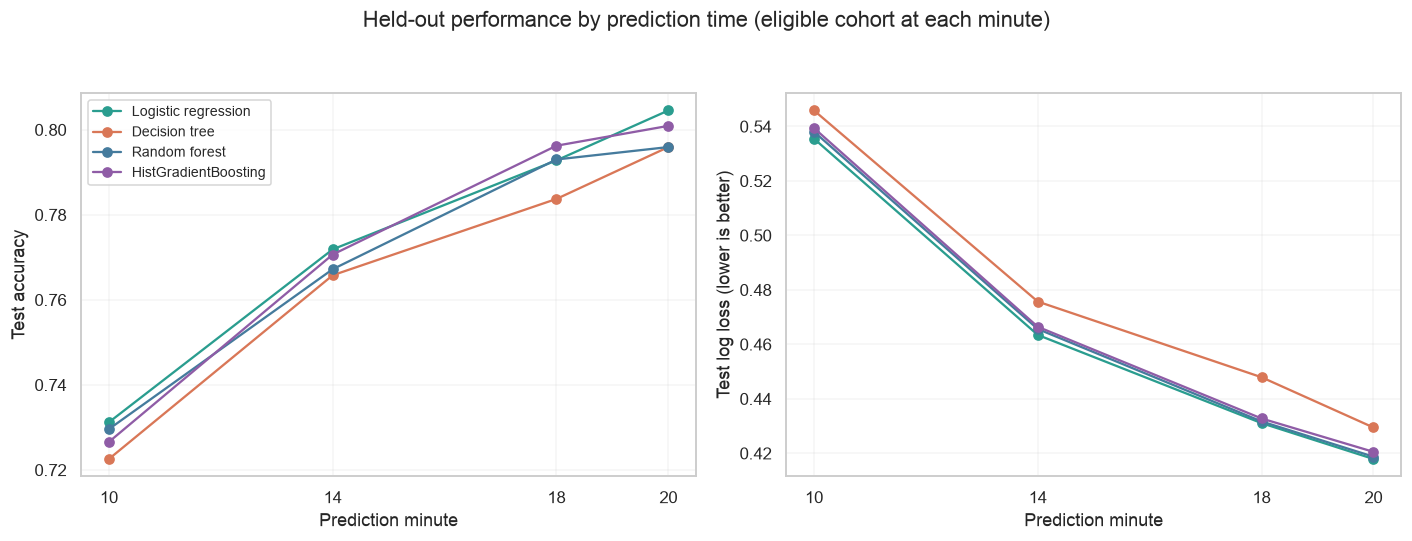

,minute,n_train,n_test
0,10,19912,4978
4,14,19723,4927
8,18,18565,4633
12,20,17738,4415


Common surviving cohort: 4,415 matches at every minute.


,minute,model,n_test,accuracy,roc_auc,log_loss,brier
0,10,Decision tree,4415,0.6895,0.7544,0.5935,0.2022
1,10,HistGradientBoosting,4415,0.6938,0.7605,0.5866,0.1996
2,10,Logistic regression,4415,0.6988,0.7631,0.5825,0.1984
3,10,Random forest,4415,0.6965,0.7607,0.5851,0.1994
4,14,Decision tree,4415,0.7386,0.8171,0.5237,0.1746
5,14,HistGradientBoosting,4415,0.7441,0.8244,0.5141,0.1711
6,14,Logistic regression,4415,0.7454,0.8268,0.5107,0.1699
7,14,Random forest,4415,0.7402,0.8254,0.5122,0.1706
8,18,Decision tree,4415,0.7730,0.8609,0.4687,0.1517
9,18,HistGradientBoosting,4415,0.7862,0.8678,0.4528,0.1480


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in MODEL_ORDER:
    frame = final_metrics.loc[final_metrics["model"].eq(name)].sort_values("minute")
    for ax, metric in zip(axes, ("accuracy", "log_loss")):
        ax.plot(frame["minute"], frame[metric], marker="o", color=MODEL_COLORS[name], label=name)
for ax, ylabel in zip(axes, ("Test accuracy", "Test log loss (lower is better)")):
    ax.set(xlabel="Prediction minute", ylabel=ylabel)
    ax.set_xticks(MINUTES)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=9)
fig.suptitle("Held-out performance by prediction time (eligible cohort at each minute)")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(figure_dir / "final_test_by_minute.png", dpi=180, bbox_inches="tight")
plt.show()

cohort_table = final_metrics[["minute", "n_train", "n_test"]].drop_duplicates().sort_values("minute")
display(cohort_table)
common_ids = set.intersection(*[
    set(predictions.loc[predictions["minute"].eq(minute), "gameId"]) for minute in MINUTES
])
common_rows = []
for (minute, name), frame in predictions.loc[predictions["gameId"].isin(common_ids)].groupby(["minute", "model"]):
    common_rows.append({"minute": int(minute), "model": name, **score_predictions(frame)})
common_cohort_metrics = pd.DataFrame(common_rows)
save_csv(common_cohort_metrics, report_dir / "final_test_common_cohort.csv")
print(f"Common surviving cohort: {len(common_ids):,} matches at every minute.")
display(common_cohort_metrics.round(4))

### Error analysis: confident mistakes and outcome reversals

Confidence is `max(p_blue_win, 1 − p_blue_win)`. We describe wrong predictions with confidence ≥90%, and outcome reversals from leads/deficits of at least 3,000 gold. These descriptive thresholds do not change the fixed classification threshold or model settings.

The minute-14 LR made **1,124 errors**, including **55 errors with at least 90% confidence**. A high-confidence error is different from a large-lead reversal: a reversal may have been predicted correctly. Match-state tables below use only features available at the prediction time, not future inputs.

In [20]:
state_columns = ["goldDiff", "expDiff", "champLevelDiff", "dragonDiff", "killShare",
                 "killDeathDiff", "outerTurretDiff", "totalTurretDiff",
                 "goldChange4", "goldSlope", "goldVolatility", "leadChanges"]
states = []
for minute, table in feature_tables.items():
    available = [column for column in state_columns if column in table]
    state = table.loc[table["gameId"].isin(test_ids), ["gameId"] + available].copy()
    state["minute"] = minute
    states.append(state)
test_states = pd.concat(states, ignore_index=True)
analysis = predictions.merge(test_states, on=["gameId", "minute"], validate="many_to_one")
assert len(analysis) == len(predictions)
analysis["wrong"] = analysis["y_pred"].ne(analysis["y_true"])
analysis["confidence"] = np.maximum(analysis["p_blue_win"], 1 - analysis["p_blue_win"])
analysis["confident_wrong"] = analysis["wrong"] & analysis["confidence"].ge(CONFIDENCE_CUTOFF)
analysis["error_type"] = np.select(
    [analysis["wrong"] & analysis["y_pred"].eq(1), analysis["wrong"] & analysis["y_pred"].eq(0)],
    ["False positive (predicted win)", "False negative (predicted loss)"], default="Correct")
confident_errors = analysis.loc[analysis["confident_wrong"]].sort_values("confidence", ascending=False)
save_csv(confident_errors, report_dir / "confident_errors.csv")

error_summary = (analysis.groupby(["minute", "model"])
                 .agg(matches=("wrong", "size"), errors=("wrong", "sum"), error_rate=("wrong", "mean"),
                      confident_errors=("confident_wrong", "sum"), mean_confidence=("confidence", "mean"))
                 .reset_index())
save_csv(error_summary, report_dir / "final_error_summary.csv")
display(error_summary.round(4))

case_columns = ["gameId", "y_true", "y_pred", "p_blue_win", "confidence", "wrong", "error_type"] + state_columns
primary_cases = analysis.loc[analysis["minute"].eq(PRIMARY_MINUTE) & analysis["model"].eq(PRIMARY_MODEL)]
primary_wrong = primary_cases.loc[primary_cases["wrong"]].sort_values("confidence", ascending=False)
print(f"Most confident minute-14 errors for the CV-preferred model ({PRIMARY_MODEL}):")
display(primary_wrong[case_columns].head(10).round(4))

large_lead_losses = primary_cases.loc[
    primary_cases["goldDiff"].ge(LARGE_GOLD_LEAD) & primary_cases["y_true"].eq(0)
].sort_values("goldDiff", ascending=False)
large_deficit_wins = primary_cases.loc[
    primary_cases["goldDiff"].le(-LARGE_GOLD_LEAD) & primary_cases["y_true"].eq(1)
].sort_values("goldDiff")
save_csv(large_lead_losses, report_dir / "minute14_large_lead_losses.csv")
save_csv(large_deficit_wins, report_dir / "minute14_large_deficit_wins.csv")
print(f"Blue led by at least {LARGE_GOLD_LEAD:,} gold at minute 14 but lost: {len(large_lead_losses):,} matches.")
display(large_lead_losses[case_columns].head(10).round(4))
print(f"Blue trailed by at least {LARGE_GOLD_LEAD:,} gold at minute 14 but won: {len(large_deficit_wins):,} matches.")
display(large_deficit_wins[case_columns].head(10).round(4))

for label, mask in [("Large lead", primary_cases["goldDiff"].ge(LARGE_GOLD_LEAD)),
                    ("Large deficit", primary_cases["goldDiff"].le(-LARGE_GOLD_LEAD))]:
    subset = primary_cases.loc[mask]
    reversals = len(large_lead_losses) if label == "Large lead" else len(large_deficit_wins)
    rate = reversals / len(subset) if len(subset) else np.nan
    print(f"{label}: {reversals:,} reversals / {len(subset):,} matches ({rate:.1%}).")

,minute,model,matches,errors,error_rate,confident_errors,mean_confidence
0,10,Decision tree,4978,1381,0.2774,74,0.7247
1,10,HistGradientBoosting,4978,1361,0.2734,45,0.7257
2,10,Logistic regression,4978,1338,0.2688,35,0.7273
3,10,Random forest,4978,1346,0.2704,37,0.7242
4,14,Decision tree,4927,1154,0.2342,61,0.7705
5,14,HistGradientBoosting,4927,1130,0.2293,57,0.7697
6,14,Logistic regression,4927,1124,0.2281,55,0.7715
7,14,Random forest,4927,1147,0.2328,50,0.7621
8,18,Decision tree,4633,1002,0.2163,59,0.7954
9,18,HistGradientBoosting,4633,944,0.2038,76,0.7975


Most confident minute-14 errors for the CV-preferred model (Logistic regression):


,gameId,y_true,y_pred,p_blue_win,confidence,wrong,error_type,goldDiff,expDiff,champLevelDiff,dragonDiff,killShare,killDeathDiff,outerTurretDiff,totalTurretDiff,goldChange4,goldSlope,goldVolatility,leadChanges
22551,4542619089,1,0,0.0147,0.9853,True,False negative (predicted loss),-8376,-6493,-1.2,-2,0.1818,-14,-1,-1,-4295.0,-1073.75,932.6738,0.0
23516,4521071452,1,0,0.0198,0.9802,True,False negative (predicted loss),-7109,-8187,-1.6,-1,0.2500,-12,0,0,-4599.0,-1149.75,1127.8353,0.0
24208,4401337188,1,0,0.0212,0.9788,True,False negative (predicted loss),-7277,-7647,-1.4,-1,0.2593,-13,0,0,-2749.0,-687.25,297.6920,0.0
23130,4529020760,1,0,0.0213,0.9787,True,False negative (predicted loss),-7848,-5286,-1.0,-2,0.1765,-11,-1,-1,-4556.0,-1139.00,292.7422,0.0
24113,4543688797,1,0,0.0224,0.9776,True,False negative (predicted loss),-9995,-5239,-0.8,0,0.3125,-6,-1,-3,-3712.0,-928.00,1622.1030,0.0
21689,4519650812,0,1,0.9692,0.9692,True,False positive (predicted win),9645,4989,1.0,-1,0.7619,11,2,2,4446.0,1111.50,524.6732,0.0
23876,4534629528,1,0,0.0317,0.9683,True,False negative (predicted loss),-6368,-5571,-1.2,-2,0.3077,-10,0,0,-5215.0,-1303.75,553.6646,0.0
23374,4462636555,0,1,0.9634,0.9634,True,False positive (predicted win),6663,4277,1.0,2,0.6842,14,1,1,4397.0,1099.25,1823.6284,0.0
21054,4545087272,0,1,0.9592,0.9592,True,False positive (predicted win),7264,4461,1.0,1,0.6111,4,3,3,5990.0,1497.50,1067.7312,0.0
22950,4426978948,1,0,0.0437,0.9563,True,False negative (predicted loss),-5850,-4620,-1.0,-2,0.3182,-8,-1,-1,-1516.0,-379.00,1043.6896,0.0


Blue led by at least 3,000 gold at minute 14 but lost: 106 matches.


,gameId,y_true,y_pred,p_blue_win,confidence,wrong,error_type,goldDiff,expDiff,champLevelDiff,dragonDiff,killShare,killDeathDiff,outerTurretDiff,totalTurretDiff,goldChange4,goldSlope,goldVolatility,leadChanges
21689,4519650812,0,1,0.9692,0.9692,True,False positive (predicted win),9645,4989,1.0,-1,0.7619,11,2,2,4446.0,1111.50,524.6732,0.0
21054,4545087272,0,1,0.9592,0.9592,True,False positive (predicted win),7264,4461,1.0,1,0.6111,4,3,3,5990.0,1497.50,1067.7312,0.0
22205,4546195429,0,1,0.9505,0.9505,True,False positive (predicted win),6822,3837,1.0,1,0.6774,11,1,1,3480.0,870.00,3102.7846,0.0
23827,4545763602,0,1,0.9317,0.9317,True,False positive (predicted win),6787,3332,1.0,0,0.7368,9,3,3,1723.0,430.75,591.8484,0.0
23374,4462636555,0,1,0.9634,0.9634,True,False positive (predicted win),6663,4277,1.0,2,0.6842,14,1,1,4397.0,1099.25,1823.6284,0.0
21269,4406066773,0,1,0.9460,0.9460,True,False positive (predicted win),6472,4013,0.4,1,0.6190,10,1,1,3711.0,927.75,490.0250,0.0
24603,4448468440,0,1,0.9456,0.9456,True,False positive (predicted win),6365,2479,1.0,2,0.7222,8,0,0,6162.0,1540.50,1347.7455,0.0
22842,4400704645,0,1,0.9561,0.9561,True,False positive (predicted win),6320,3872,0.6,2,0.6522,7,2,2,3157.0,789.25,712.0565,0.0
20678,4533468782,0,1,0.9468,0.9468,True,False positive (predicted win),6185,3153,0.8,2,0.6111,4,1,2,2851.0,712.75,1785.4446,0.0
23163,4395522621,0,1,0.9210,0.9210,True,False positive (predicted win),6102,5018,1.2,-1,0.6579,12,2,3,764.0,191.00,14.1421,0.0


Blue trailed by at least 3,000 gold at minute 14 but won: 97 matches.


,gameId,y_true,y_pred,p_blue_win,confidence,wrong,error_type,goldDiff,expDiff,champLevelDiff,dragonDiff,killShare,killDeathDiff,outerTurretDiff,totalTurretDiff,goldChange4,goldSlope,goldVolatility,leadChanges
24113,4543688797,1,0,0.0224,0.9776,True,False negative (predicted loss),-9995,-5239,-0.8,0,0.3125,-6,-1,-3,-3712.0,-928.00,1622.1030,0.0
22551,4542619089,1,0,0.0147,0.9853,True,False negative (predicted loss),-8376,-6493,-1.2,-2,0.1818,-14,-1,-1,-4295.0,-1073.75,932.6738,0.0
23130,4529020760,1,0,0.0213,0.9787,True,False negative (predicted loss),-7848,-5286,-1.0,-2,0.1765,-11,-1,-1,-4556.0,-1139.00,292.7422,0.0
24529,4383231600,1,0,0.0628,0.9372,True,False negative (predicted loss),-7830,-5449,-0.8,2,0.3333,-9,-2,-2,-6336.0,-1584.00,2868.0251,0.0
22538,4527970110,1,0,0.0503,0.9497,True,False negative (predicted loss),-7763,-5199,-1.2,1,0.2667,-7,-1,-2,-2557.0,-639.25,942.5733,0.0
24027,4413299216,1,0,0.0592,0.9408,True,False negative (predicted loss),-7309,-3240,-1.0,0,0.1429,-15,-1,-1,-4848.0,-1212.00,156.9777,0.0
24208,4401337188,1,0,0.0212,0.9788,True,False negative (predicted loss),-7277,-7647,-1.4,-1,0.2593,-13,0,0,-2749.0,-687.25,297.6920,0.0
23516,4521071452,1,0,0.0198,0.9802,True,False negative (predicted loss),-7109,-8187,-1.6,-1,0.2500,-12,0,0,-4599.0,-1149.75,1127.8353,0.0
22583,4546700612,1,0,0.0595,0.9405,True,False negative (predicted loss),-6904,-4251,-0.8,0,0.3158,-7,-2,-2,-3296.0,-824.00,247.4874,0.0
23882,4469472842,1,0,0.1252,0.8748,True,False negative (predicted loss),-6649,-3178,-0.4,2,0.3235,-12,-1,-1,-2048.0,-512.00,748.1190,0.0


Large lead: 106 reversals / 1,137 matches (9.3%).
Large deficit: 97 reversals / 1,108 matches (8.8%).


### Where errors concentrate

For the preferred minute-14 LR, the error rate is **40.1%** when absolute gold difference is below 1,000 (999 matches), **30.9%** between 1,000 and below 3,000 (1,683 matches), and **9.0%** at at least 3,000 (2,245 matches). Close games are substantially harder, while large advantages are informative but not conclusive.

Objective and turret slices are descriptive: small or correlated groups should not be interpreted as causal effects. We report their counts and compare whether models fail on the same matches.

Minute-14 slices for the CV-preferred model:


,minute,model,slice,matches,errors,error_rate,confident_errors,mean_confidence,dimension
18,14,Logistic regression,"<1,000",999,401,0.4014,0,0.5982,absolute_gold_bin
19,14,Logistic regression,"1,000–<3,000",1683,520,0.3090,1,0.7033,absolute_gold_bin
20,14,Logistic regression,"≥3,000",2245,203,0.0904,54,0.8998,absolute_gold_bin
60,14,Logistic regression,Blue ahead,2504,565,0.2256,26,0.7674,gold_position
61,14,Logistic regression,Blue behind,2423,559,0.2307,29,0.7758,gold_position
98,14,Logistic regression,Blue ahead,1859,413,0.2222,25,0.7867,dragon_position
99,14,Logistic regression,Blue behind,2040,455,0.2230,24,0.7777,dragon_position
100,14,Logistic regression,Tied,1028,256,0.2490,6,0.7317,dragon_position
146,14,Logistic regression,Blue ahead,1357,267,0.1968,22,0.8101,outer_turret_position
147,14,Logistic regression,Blue behind,1207,216,0.1790,18,0.8168,outer_turret_position


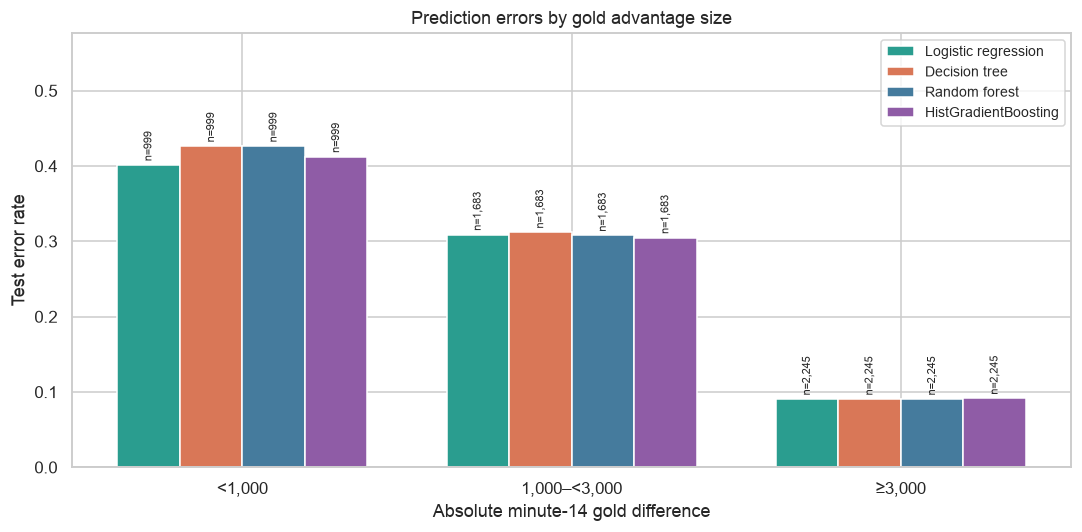

,minute,model_a,model_b,matches,both_wrong,either_wrong,error_overlap_jaccard
0,14,Logistic regression,Decision tree,4927,1019,1259,0.8094
1,14,Logistic regression,Random forest,4927,1060,1211,0.8753
2,14,Logistic regression,HistGradientBoosting,4927,1035,1219,0.8491
3,14,Decision tree,Random forest,4927,1035,1266,0.8175
4,14,Decision tree,HistGradientBoosting,4927,1008,1276,0.7900
5,14,Random forest,HistGradientBoosting,4927,1038,1239,0.8378


In [21]:
analysis["absolute_gold_bin"] = pd.cut(analysis["goldDiff"].abs(), [0, 1000, 3000, np.inf],
                                       labels=["<1,000", "1,000–<3,000", "≥3,000"], right=False)
def advantage_label(values):
    return np.select([values.gt(0), values.lt(0)], ["Blue ahead", "Blue behind"], default="Tied")
analysis["gold_position"] = advantage_label(analysis["goldDiff"])
analysis["dragon_position"] = advantage_label(analysis["dragonDiff"])
analysis["outer_turret_position"] = advantage_label(analysis["outerTurretDiff"])

slice_frames = []
for dimension in ("absolute_gold_bin", "gold_position", "dragon_position", "outer_turret_position"):
    table = (analysis.groupby(["minute", "model", dimension], observed=True)
             .agg(matches=("wrong", "size"), errors=("wrong", "sum"), error_rate=("wrong", "mean"),
                  confident_errors=("confident_wrong", "sum"), mean_confidence=("confidence", "mean"))
             .reset_index().rename(columns={dimension: "slice"}))
    table["slice"] = table["slice"].astype(str)
    table["dimension"] = dimension
    slice_frames.append(table)
error_slices = pd.concat(slice_frames, ignore_index=True)
save_csv(error_slices, report_dir / "error_slices.csv")
print("Minute-14 slices for the CV-preferred model:")
display(error_slices.loc[error_slices["minute"].eq(PRIMARY_MINUTE)
                         & error_slices["model"].eq(PRIMARY_MODEL)].round(4))

gold_slice = error_slices.loc[error_slices["minute"].eq(PRIMARY_MINUTE)
                             & error_slices["dimension"].eq("absolute_gold_bin")]
gold_labels = ["<1,000", "1,000–<3,000", "≥3,000"]
fig, ax = plt.subplots(figsize=(10, 5))
width = 0.19
for j, name in enumerate(MODEL_ORDER):
    frame = gold_slice.loc[gold_slice["model"].eq(name)].set_index("slice").reindex(gold_labels)
    positions = np.arange(len(gold_labels)) + (j - 1.5) * width
    ax.bar(positions, frame["error_rate"], width, color=MODEL_COLORS[name], label=name)
    for x, (_, row) in zip(positions, frame.iterrows()):
        if pd.notna(row["matches"]):
            ax.text(x, row["error_rate"] + 0.005, f"n={int(row['matches']):,}",
                    ha="center", va="bottom", rotation=90, fontsize=7)
ax.set_xticks(np.arange(len(gold_labels)), gold_labels)
ax.set(xlabel="Absolute minute-14 gold difference", ylabel="Test error rate",
       title="Prediction errors by gold advantage size")
highest = gold_slice["error_rate"].max()
ax.set_ylim(0, min(1.15, max(0.2, highest + 0.15)))
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figure_dir / "final_error_by_gold.png", dpi=180, bbox_inches="tight")
plt.show()

wrong_matrix = analysis.loc[analysis["minute"].eq(PRIMARY_MINUTE)].pivot(
    index="gameId", columns="model", values="wrong").reindex(columns=MODEL_ORDER)
agreement_rows = []
for i, first in enumerate(MODEL_ORDER):
    for second in MODEL_ORDER[i + 1:]:
        both = int((wrong_matrix[first] & wrong_matrix[second]).sum())
        either = int((wrong_matrix[first] | wrong_matrix[second]).sum())
        agreement_rows.append({"minute": PRIMARY_MINUTE, "model_a": first, "model_b": second,
                                "matches": len(wrong_matrix), "both_wrong": both,
                                "either_wrong": either, "error_overlap_jaccard": both / either if either else np.nan})
error_overlap = pd.DataFrame(agreement_rows)
save_csv(error_overlap, report_dir / "final_error_overlap.csv")
display(error_overlap.round(4))

### Representative cases and interpretation

- **Match 4519650812 — large lead, eventual loss:** blue led by 9,645 gold and 4,989 experience at minute 14, had an outer-turret difference of +2, and had improved its gold difference by 4,446 since minute 10. LR assigned a 96.9% win probability, yet blue lost. Blue's dragon difference was −1, but this single observation does not establish the cause of the loss.
- **Match 4542619089 — large deficit, eventual win:** blue trailed by 8,376 gold and 6,493 experience with a dragon difference of −2. LR assigned about a 1.5% win probability, yet blue won. The example demonstrates uncertainty beyond the observed resource state.

There were **106 minute-14 matches where blue led by at least 3,000 gold but lost**, and **97 where blue trailed by at least 3,000 gold but won**. The model captures strong average associations, but resource advantages do not determine every outcome. The supplied fields cannot explain unobserved gameplay decisions or establish why a specific reversal happened.

### Limitations

- The data is an observational sample of ranked matches. Results apply to its recorded population and eligible in-progress cohorts; transfer to other ranks, game versions, or play settings was not tested.
- Resource, combat, and objective features are correlated. Coefficients, feature importances, and marginal win-rate plots do not establish causal effects.
- The downstream four-feature CV score follows supervised feature selection on training data; CV supported model selection rather than an independent nested estimate. The reserved test stage supplies the final evaluation.
- Ensemble grids were bounded, HGB used a fixed 200 iterations, and several optima lie at grid boundaries. The results compare tested configurations, not the best possible instance of each model family.
- Five fold scores are dependent through overlapping training sets. Small differences and descriptive fold SEs should not be presented as formal significance claims.
- Later prediction times use smaller survivor cohorts and separately trained configurations. The common-cohort table helps describe this issue but does not remove all differences.

### Conclusion

The four-feature logistic regression offers the most interpretable primary model and the lowest observed minute-14 test log loss among the tested finalists. Objective summaries help modestly beyond resource differences in the initial LR analysis, but richer trajectory features and the tested ensembles provide little additional benefit. Prediction improves later in the match, and uncertainty is concentrated in close resource states; confidently wrong predictions and large-lead reversals remain important limitations.

All final configurations remain those selected before held-out evaluation. This notebook includes the complete analysis, completed training records, frozen configurations, final comparison, probability diagnostics, and error analysis in the required order.

In [22]:
assert len(final_metrics) == len(MINUTES) * len(MODEL_ORDER)
np.testing.assert_allclose(
    final_metrics.sort_values(["minute", "model"])[METRICS].to_numpy(),
    reference_test_metrics.sort_values(["minute", "model"])[METRICS].to_numpy(), rtol=1e-9, atol=1e-11)
assert int(primary_metrics.loc[primary_metrics.model.eq(PRIMARY_MODEL), "n_test"].item()) == 4927
assert len(primary_wrong) == 1124 and int(primary_cases.confident_wrong.sum()) == 55
assert len(large_lead_losses) == 106 and len(large_deficit_wins) == 97
print("Reproduced all 16 frozen evaluations and the reported primary error counts.")
print("The only external input was the original raw CSV; all helper code and completed records are included.")
print("Generated tables and figures:", report_dir)

Reproduced all 16 frozen evaluations and the reported primary error counts.
The only external input was the original raw CSV; all helper code and completed records are included.
Generated tables and figures: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/reports/submission06
